In [19]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("LM2500 Marine Gas Turbine Analytics")
print("Python environment ready!")


LM2500 Marine Gas Turbine Analytics
Python environment ready!


In [20]:

from pathlib import Path

data_path = Path("/content")

required_files = [
    "train_FD001.txt",
    "test_FD001.txt",
    "RUL_FD001.txt"
]

for filename in required_files:
    filepath = data_path / filename
    if filepath.exists():
        print(f"FOUND: {filename}")
    else:
        print(f"MISSING: {filename}")


FOUND: train_FD001.txt
FOUND: test_FD001.txt
FOUND: RUL_FD001.txt


In [21]:

# STEP 3 - CELL 1: Load NASA FD001 datasets

import pandas as pd
from pathlib import Path

data_path = Path("/content")

columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train_df = pd.read_csv(
    data_path / "train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    data_path / "test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

rul_df = pd.read_csv(
    data_path / "RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)
print("RUL dataset:", rul_df.shape)

display(train_df.head())


Training dataset: (20631, 26)
Testing dataset: (13096, 26)
RUL dataset: (100, 1)


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [22]:

# STEP 3 - CELL 2: Data quality checks

for name, df in [
    ("Training", train_df),
    ("Testing", test_df),
    ("RUL", rul_df)
]:
    print(f"\n{name} Dataset")
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

print("\nTraining data types:")
print(train_df.dtypes)



Training Dataset
Missing values: 0
Duplicate rows: 0

Testing Dataset
Missing values: 0
Duplicate rows: 0

RUL Dataset
Missing values: 0
Duplicate rows: 29

Training data types:
engine_id      int64
cycle          int64
setting_1    float64
setting_2    float64
setting_3    float64
sensor_1     float64
sensor_2     float64
sensor_3     float64
sensor_4     float64
sensor_5     float64
sensor_6     float64
sensor_7     float64
sensor_8     float64
sensor_9     float64
sensor_10    float64
sensor_11    float64
sensor_12    float64
sensor_13    float64
sensor_14    float64
sensor_15    float64
sensor_16    float64
sensor_17      int64
sensor_18      int64
sensor_19    float64
sensor_20    float64
sensor_21    float64
dtype: object


In [23]:

# STEP 3 - CELL 3: Engine and cycle validation

print("Training engines:", train_df["engine_id"].nunique())
print("Testing engines:", test_df["engine_id"].nunique())

print("Minimum cycle:", train_df["cycle"].min())
print("Maximum cycle:", train_df["cycle"].max())

print("\nEngine cycle summary:")
display(
    train_df.groupby("engine_id")["cycle"]
    .agg(["min", "max", "count"])
    .head(10)
)

# Check for duplicate engine-cycle combinations
duplicate_cycles = train_df.duplicated(
    subset=["engine_id", "cycle"]
).sum()

print("Duplicate engine-cycle records:", duplicate_cycles)

# Check that cycles begin at 1 and increase consecutively
cycle_issues = []

for engine_id, group in train_df.groupby("engine_id"):
    cycles = group["cycle"].sort_values().to_numpy()
    expected = np.arange(1, len(cycles) + 1)

    if not np.array_equal(cycles, expected):
        cycle_issues.append(engine_id)

print("Engines with cycle sequence issues:", cycle_issues)


Training engines: 100
Testing engines: 100
Minimum cycle: 1
Maximum cycle: 362

Engine cycle summary:


,min,max,count
engine_id,,,
1,1,192,192
2,1,287,287
3,1,179,179
4,1,189,189
5,1,269,269
6,1,188,188
7,1,259,259
8,1,150,150
9,1,201,201


Duplicate engine-cycle records: 0
Engines with cycle sequence issues: []


In [24]:

# STEP 3 - CELL 4: Sensor variability

sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

sensor_summary = train_df[sensor_cols].agg(
    ["mean", "std", "min", "max"]
).T

sensor_summary["unique_values"] = (
    train_df[sensor_cols].nunique()
)

display(sensor_summary)

constant_sensors = [
    col for col in sensor_cols
    if train_df[col].nunique() == 1
]

print("Constant sensors:", constant_sensors)

low_variation_sensors = [
    col for col in sensor_cols
    if train_df[col].nunique() <= 2
]

print("Sensors with 2 or fewer unique values:",
      low_variation_sensors)


,mean,std,min,max,unique_values
sensor_1,518.670000,6.537152e-11,518.6700,518.6700,1
sensor_2,642.680934,5.000533e-01,641.2100,644.5300,310
sensor_3,1590.523119,6.131150e+00,1571.0400,1616.9100,3012
sensor_4,1408.933782,9.000605e+00,1382.2500,1441.4900,4051
sensor_5,14.620000,3.394700e-12,14.6200,14.6200,1
sensor_6,21.609803,1.388985e-03,21.6000,21.6100,2
sensor_7,553.367711,8.850923e-01,549.8500,556.0600,513
sensor_8,2388.096652,7.098548e-02,2387.9000,2388.5600,53
sensor_9,9065.242941,2.208288e+01,9021.7300,9244.5900,6403
sensor_10,1.300000,4.660829e-13,1.3000,1.3000,1


Constant sensors: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Sensors with 2 or fewer unique values: ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


In [25]:

# STEP 3 - CELL 5: Validate and save data

output_folder = Path("/content/LM2500_Project")
output_folder.mkdir(exist_ok=True)

assert train_df.shape[1] == 26, "Unexpected column count"
assert train_df["engine_id"].nunique() == 100, "Unexpected engine count"
assert train_df.isnull().sum().sum() == 0, "Missing values found"
assert train_df.duplicated().sum() == 0, "Duplicate rows found"
assert train_df.duplicated(["engine_id", "cycle"]).sum() == 0
assert not cycle_issues, "Engine cycle sequence issues found"
assert len(rul_df) == test_df["engine_id"].nunique(), (
    "RUL count does not match testing engine count"
)

clean_train = train_df.copy()
clean_test = test_df.copy()

clean_train.to_csv(
    output_folder / "train_FD001_validated.csv",
    index=False
)

clean_test.to_csv(
    output_folder / "test_FD001_validated.csv",
    index=False
)

rul_df.to_csv(
    output_folder / "RUL_FD001_validated.csv",
    index=False
)

print("Data validation successful!")
print("Training rows:", len(clean_train))
print("Testing rows:", len(clean_test))
print("Files saved to:", output_folder)


Data validation successful!
Training rows: 20631
Testing rows: 13096
Files saved to: /content/LM2500_Project


ENGINE OPERATING LIFE ANALYSIS
--------------------------------
Total engines: 100
Average operating life: 206.31 cycles
Median operating life: 199.00 cycles
Shortest operating life: 128 cycles
Longest operating life: 362 cycles

Shortest-life engine:
engine_id        39
total_cycles    128

Longest-life engine:
engine_id        69
total_cycles    362


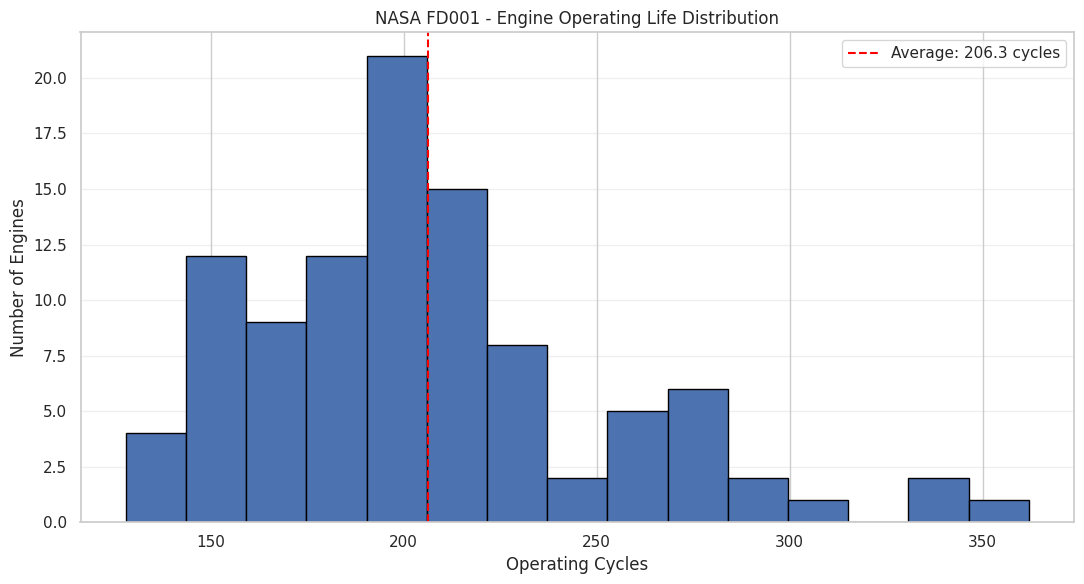

In [26]:

# STEP 4 - CELL 1
# Engine Operating Life Analysis

import pandas as pd
import matplotlib.pyplot as plt

# Use validated training dataset
engine_life = (
    clean_train.groupby("engine_id")["cycle"]
    .max()
    .reset_index()
)

engine_life.columns = ["engine_id", "total_cycles"]

# Calculate engine life statistics
average_life = engine_life["total_cycles"].mean()
minimum_life = engine_life["total_cycles"].min()
maximum_life = engine_life["total_cycles"].max()
median_life = engine_life["total_cycles"].median()

print("ENGINE OPERATING LIFE ANALYSIS")
print("--------------------------------")
print("Total engines:", len(engine_life))
print(f"Average operating life: {average_life:.2f} cycles")
print(f"Median operating life: {median_life:.2f} cycles")
print(f"Shortest operating life: {minimum_life} cycles")
print(f"Longest operating life: {maximum_life} cycles")

# Identify shortest and longest life engines
shortest_engine = engine_life.loc[
    engine_life["total_cycles"].idxmin()
]

longest_engine = engine_life.loc[
    engine_life["total_cycles"].idxmax()
]

print("\nShortest-life engine:")
print(shortest_engine.to_string())

print("\nLongest-life engine:")
print(longest_engine.to_string())

# Visualize operating life distribution
plt.figure(figsize=(11, 6))

plt.hist(
    engine_life["total_cycles"],
    bins=15,
    edgecolor="black"
)

plt.axvline(
    average_life,
    color="red",
    linestyle="--",
    label=f"Average: {average_life:.1f} cycles"
)

plt.title("NASA FD001 - Engine Operating Life Distribution")
plt.xlabel("Operating Cycles")
plt.ylabel("Number of Engines")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


AVERAGE SENSOR VALUES BY ENGINE LIFE


,sensor_2,sensor_4,sensor_11,sensor_15
life_bin,,,,
10,642.371502,1402.537372,47.346782,8.417166
20,642.384635,1402.801126,47.356390,8.418495
30,642.401832,1403.368610,47.371268,8.420826
40,642.458557,1404.303229,47.400743,8.423761
50,642.495145,1405.412772,47.432440,8.427015
60,642.566060,1406.942075,47.480342,8.432868
70,642.697617,1409.033850,47.546699,8.442628
80,642.843865,1412.398604,47.645652,8.456668
90,643.094370,1417.258999,47.792197,8.474743


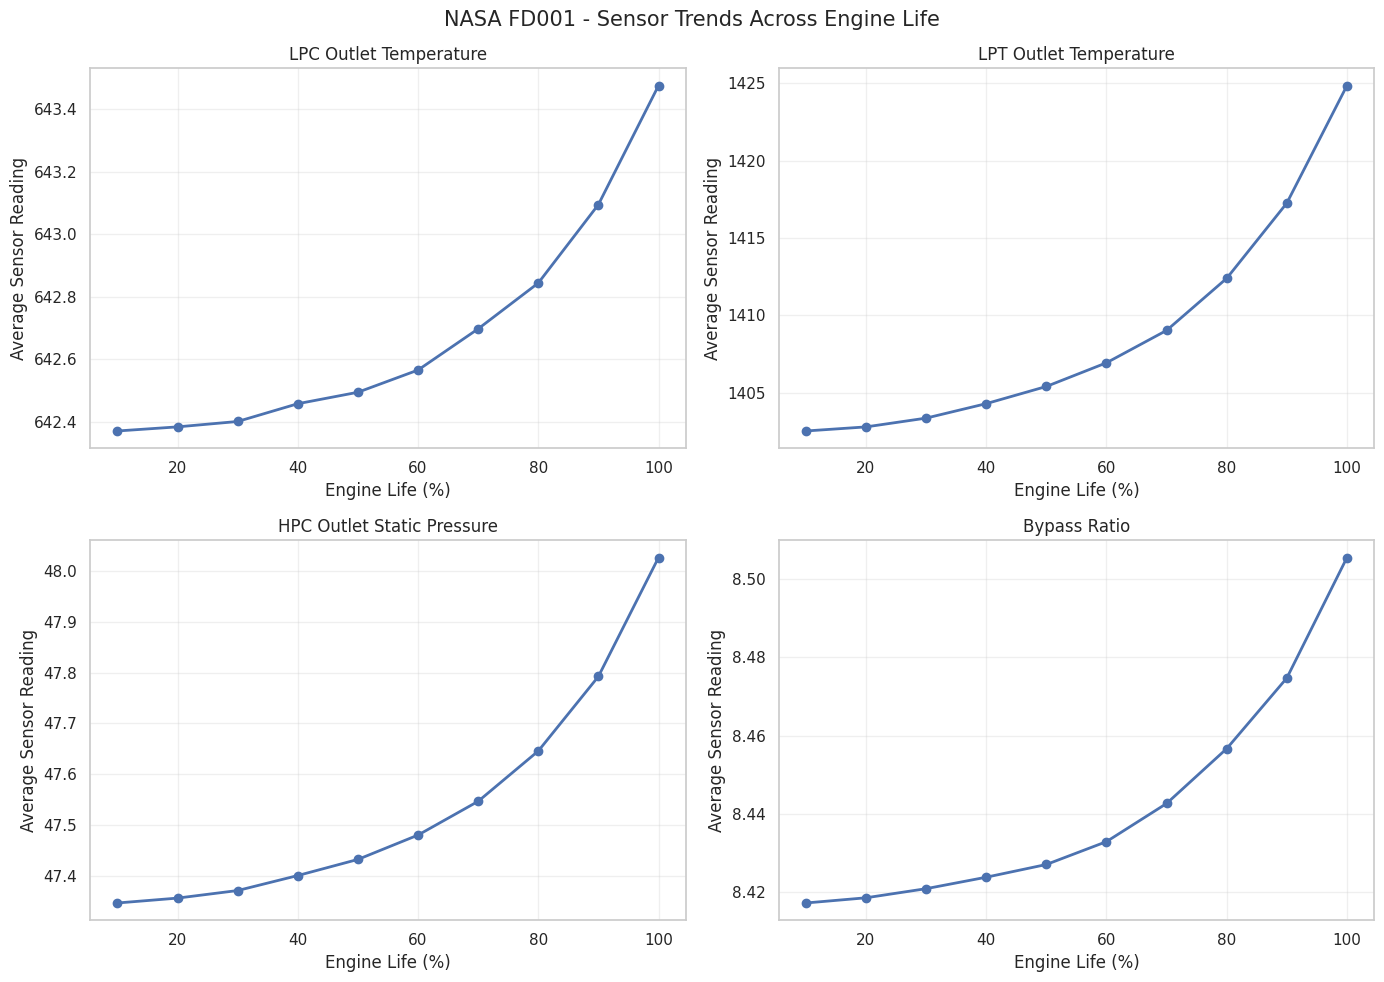

In [27]:

# STEP 4 - CELL 2
# Sensor Trends Across Engine Life

import pandas as pd
import matplotlib.pyplot as plt

# Select sensors for degradation analysis
selected_sensors = [
    "sensor_2",
    "sensor_4",
    "sensor_11",
    "sensor_15"
]

# Use training data validated in Step 3
sensor_data = clean_train.copy()

# Determine each engine's final operating cycle
sensor_data["max_cycle"] = (
    sensor_data.groupby("engine_id")["cycle"]
    .transform("max")
)

# Calculate percentage of operating life
sensor_data["life_percent"] = (
    sensor_data["cycle"] /
    sensor_data["max_cycle"] * 100
)

# Divide engine life into 10 equal percentage intervals
sensor_data["life_bin"] = pd.cut(
    sensor_data["life_percent"],
    bins=range(0, 101, 10),
    labels=range(10, 101, 10),
    include_lowest=True
)

# Calculate average sensor values by life interval
sensor_trends = (
    sensor_data.groupby(
        "life_bin",
        observed=True
    )[selected_sensors]
    .mean()
)

print("AVERAGE SENSOR VALUES BY ENGINE LIFE")
display(sensor_trends)

# Create four sensor trend charts
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

sensor_titles = {
    "sensor_2": "LPC Outlet Temperature",
    "sensor_4": "LPT Outlet Temperature",
    "sensor_11": "HPC Outlet Static Pressure",
    "sensor_15": "Bypass Ratio"
}

for ax, sensor in zip(axes.flat, selected_sensors):

    ax.plot(
        sensor_trends.index.astype(int),
        sensor_trends[sensor],
        marker="o",
        linewidth=2
    )

    ax.set_title(sensor_titles[sensor])
    ax.set_xlabel("Engine Life (%)")
    ax.set_ylabel("Average Sensor Reading")
    ax.grid(alpha=0.3)

plt.suptitle(
    "NASA FD001 - Sensor Trends Across Engine Life",
    fontsize=15
)

plt.tight_layout()
plt.show()


TEMPERATURE AND PRESSURE ANALYSIS
---------------------------------


,Early Mean,Late Mean,Mean Change,Median Change,Engines Increasing,Engines Decreasing
LPC Outlet Temperature,642.385,643.478,1.094,1.101,100,0
LPT Outlet Temperature,1402.765,1424.894,22.129,22.156,100,0
HPC Outlet Static Pressure,47.354,48.029,0.675,0.659,100,0


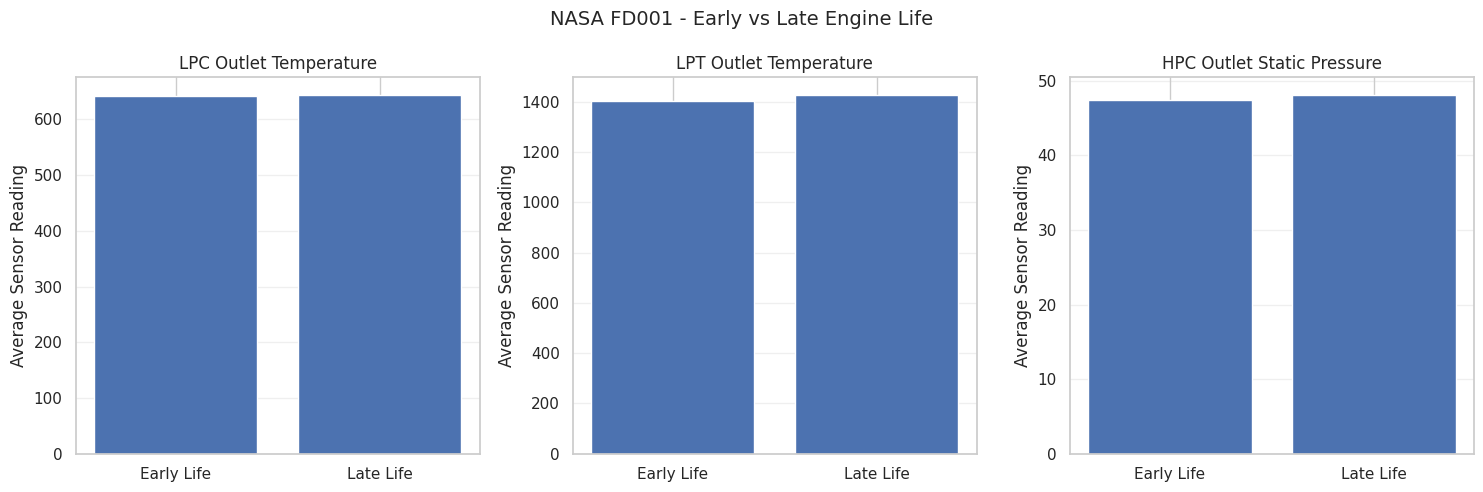

Analysis saved successfully.


In [28]:

# STEP 4 - CELL 3
# Temperature and Pressure Sensor Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use validated NASA FD001 training data
df = clean_train.copy()

selected_sensors = [
    "sensor_2",
    "sensor_4",
    "sensor_11"
]

sensor_names = {
    "sensor_2": "LPC Outlet Temperature",
    "sensor_4": "LPT Outlet Temperature",
    "sensor_11": "HPC Outlet Static Pressure"
}

# Sort observations by engine and cycle
df = df.sort_values(
    ["engine_id", "cycle"]
)

# Compare first and last 10% of cycles per engine
df["max_cycle"] = (
    df.groupby("engine_id")["cycle"]
    .transform("max")
)

df["life_fraction"] = (
    df["cycle"] / df["max_cycle"]
)

early_data = df[
    df["life_fraction"] <= 0.10
]

late_data = df[
    df["life_fraction"] > 0.90
]

# Calculate each engine's early and late averages
early_avg = (
    early_data.groupby("engine_id")[selected_sensors]
    .mean()
)

late_avg = (
    late_data.groupby("engine_id")[selected_sensors]
    .mean()
)

# Calculate changes for each engine
sensor_change = late_avg - early_avg

# Summarize across engines
results = pd.DataFrame({
    "Early Mean": early_avg.mean(),
    "Late Mean": late_avg.mean(),
    "Mean Change": sensor_change.mean(),
    "Median Change": sensor_change.median(),
    "Engines Increasing": (
        sensor_change > 0
    ).sum(),
    "Engines Decreasing": (
        sensor_change < 0
    ).sum()
})

results.index = [
    sensor_names[s] for s in selected_sensors
]

print("TEMPERATURE AND PRESSURE ANALYSIS")
print("---------------------------------")
display(results.round(3))

# Plot average early and late sensor readings
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

for ax, sensor in zip(axes, selected_sensors):

    values = [
        early_avg[sensor].mean(),
        late_avg[sensor].mean()
    ]

    ax.bar(
        ["Early Life", "Late Life"],
        values
    )

    ax.set_title(sensor_names[sensor])
    ax.set_ylabel("Average Sensor Reading")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "NASA FD001 - Early vs Late Engine Life",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Save results for later reporting
results.to_csv(
    "/content/LM2500_Project/"
    "temperature_pressure_analysis.csv"
)

print("Analysis saved successfully.")


SENSOR CORRELATION WITH RUL
--------------------------------


,Correlation with RUL
sensor_11,-0.6962
sensor_4,-0.6789
sensor_12,0.6720
sensor_7,0.6572
sensor_15,-0.6427
sensor_21,0.6357
sensor_20,0.6294
sensor_2,-0.6065
sensor_17,-0.6062
sensor_3,-0.5845



TOP 5 SENSORS BY ABSOLUTE CORRELATION


,RUL
sensor_11,-0.696228
sensor_4,-0.678948
sensor_12,0.671983
sensor_7,0.657223
sensor_15,-0.642667


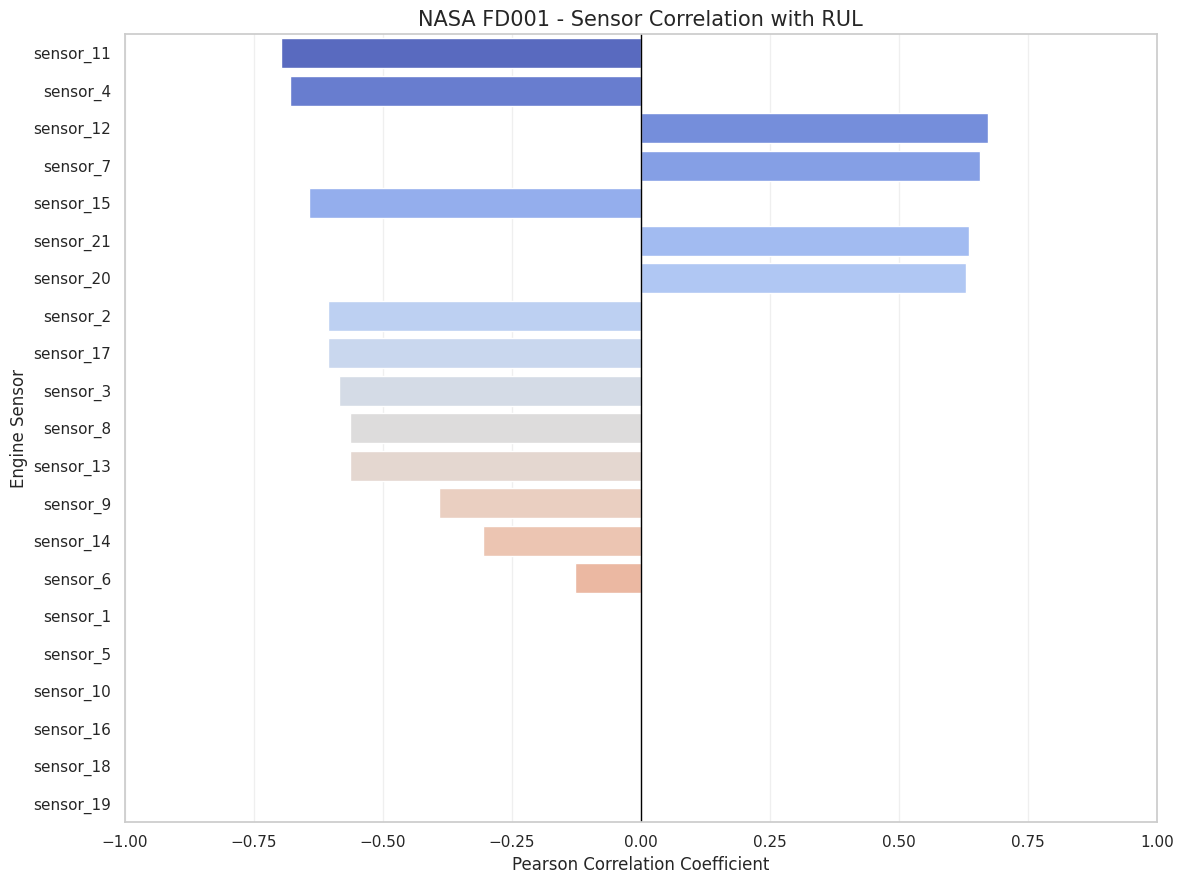

Correlation analysis saved successfully.


In [29]:

# STEP 4 - CELL 4
# Sensor Correlation Analysis with Remaining Useful Life

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Use validated training dataset
df = clean_train.copy()

# Calculate final cycle for each engine
df["max_cycle"] = (
    df.groupby("engine_id")["cycle"]
    .transform("max")
)

# Calculate remaining useful life
df["RUL"] = df["max_cycle"] - df["cycle"]

# Select all 21 sensor channels
sensor_cols = [
    f"sensor_{i}" for i in range(1, 22)
]

# Calculate Pearson correlations with RUL
correlations = (
    df[sensor_cols + ["RUL"]]
    .corr(method="pearson")["RUL"]
    .drop("RUL")
)

# Sort from strongest absolute correlation
correlations = correlations.reindex(
    correlations.abs().sort_values(
        ascending=False
    ).index
)

print("SENSOR CORRELATION WITH RUL")
print("--------------------------------")

display(
    correlations.to_frame(
        name="Correlation with RUL"
    ).round(4)
)

# Display strongest relationships
print("\nTOP 5 SENSORS BY ABSOLUTE CORRELATION")
display(correlations.head(5))

# Create horizontal correlation chart
plt.figure(figsize=(12, 9))

sns.barplot(
    x=correlations.values,
    y=correlations.index,
    hue=correlations.index,
    palette="coolwarm",
    legend=False
)

plt.axvline(
    x=0,
    color="black",
    linewidth=1
)

plt.title(
    "NASA FD001 - Sensor Correlation with RUL",
    fontsize=15
)

plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Engine Sensor")

plt.xlim(-1, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Save correlation results
correlations.to_csv(
    "/content/LM2500_Project/"
    "sensor_rul_correlations.csv",
    header=["Correlation with RUL"]
)

print("Correlation analysis saved successfully.")


SELECTED ENGINES
----------------
Engine 39: 128 cycles
Engine 26: 199 cycles
Engine 15: 207 cycles
Engine 69: 362 cycles


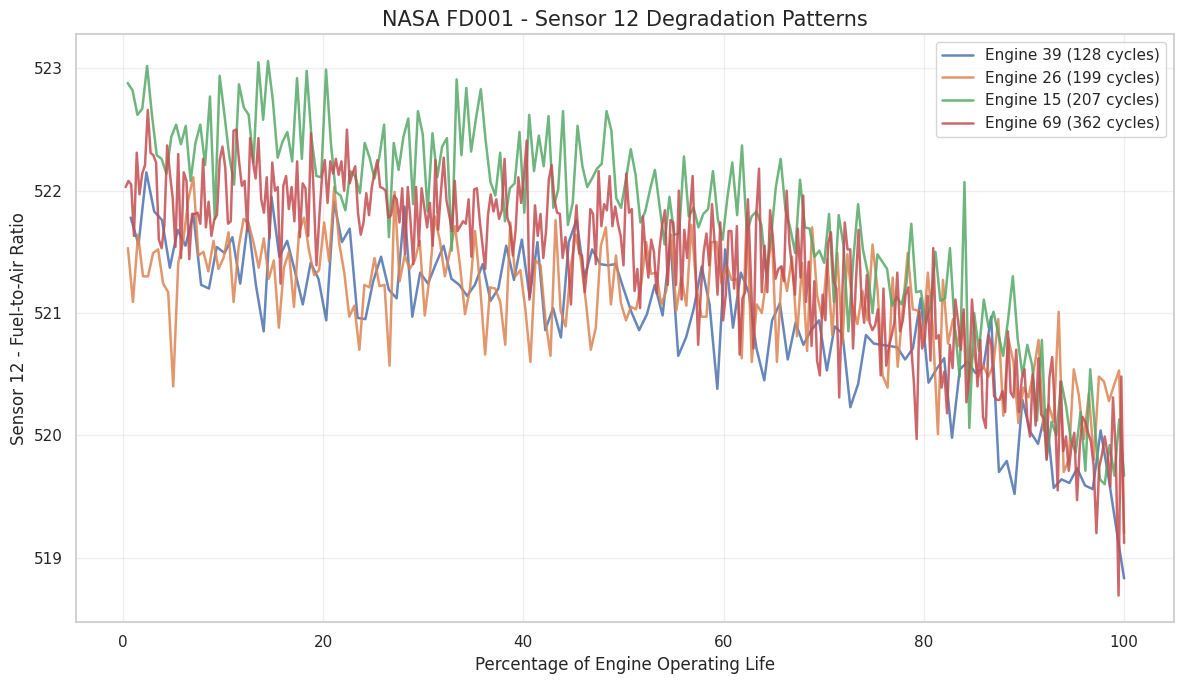


ENGINE DEGRADATION COMPARISON


,Engine,Total Cycles,Early Sensor 12,Late Sensor 12,Sensor Change
0,39,128,521.61154,519.66462,-1.94692
1,26,199,521.42150,520.24200,-1.17950
2,15,207,522.50143,520.08286,-2.41857
3,69,362,521.97838,519.96811,-2.01027


Engine degradation comparison saved.


In [30]:

# STEP 4 - CELL 5
# Individual Engine Degradation Patterns

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use validated training data
df = clean_train.copy()

# Calculate engine operating life
engine_life = (
    df.groupby("engine_id")["cycle"]
    .max()
)

# Select representative engines
shortest_engine = engine_life.idxmin()
longest_engine = engine_life.idxmax()

average_life = engine_life.mean()
median_life = engine_life.median()

average_engine = (
    (engine_life - average_life).abs().idxmin()
)

median_engine = (
    (engine_life - median_life).abs().idxmin()
)

selected_engines = list(dict.fromkeys([
    shortest_engine,
    median_engine,
    average_engine,
    longest_engine
]))

print("SELECTED ENGINES")
print("----------------")

for engine in selected_engines:
    print(
        f"Engine {engine}: "
        f"{engine_life.loc[engine]} cycles"
    )

# Calculate normalized engine life percentage
df["max_cycle"] = (
    df.groupby("engine_id")["cycle"]
    .transform("max")
)

df["life_percent"] = (
    df["cycle"] / df["max_cycle"] * 100
)

# Calculate remaining useful life
df["RUL"] = df["max_cycle"] - df["cycle"]

# Plot Sensor 12 degradation patterns
plt.figure(figsize=(12, 7))

for engine in selected_engines:

    engine_data = df[
        df["engine_id"] == engine
    ].sort_values("cycle")

    plt.plot(
        engine_data["life_percent"],
        engine_data["sensor_12"],
        label=(
            f"Engine {engine} "
            f"({engine_life.loc[engine]} cycles)"
        ),
        linewidth=1.8,
        alpha=0.85
    )

plt.title(
    "NASA FD001 - Sensor 12 Degradation Patterns",
    fontsize=15
)

plt.xlabel("Percentage of Engine Operating Life")
plt.ylabel("Sensor 12 - Fuel-to-Air Ratio")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Compare early and late Sensor 12 values
comparison = []

for engine in selected_engines:

    engine_data = df[
        df["engine_id"] == engine
    ].sort_values("cycle")

    n = max(1, int(np.ceil(len(engine_data) * 0.10)))

    early_mean = (
        engine_data["sensor_12"].head(n).mean()
    )

    late_mean = (
        engine_data["sensor_12"].tail(n).mean()
    )

    comparison.append({
        "Engine": engine,
        "Total Cycles": engine_life.loc[engine],
        "Early Sensor 12": early_mean,
        "Late Sensor 12": late_mean,
        "Sensor Change": late_mean - early_mean
    })

comparison_df = pd.DataFrame(comparison)

print("\nENGINE DEGRADATION COMPARISON")
display(comparison_df.round(5))

# Save analysis
comparison_df.to_csv(
    "/content/LM2500_Project/"
    "engine_degradation_comparison.csv",
    index=False
)

print("Engine degradation comparison saved.")


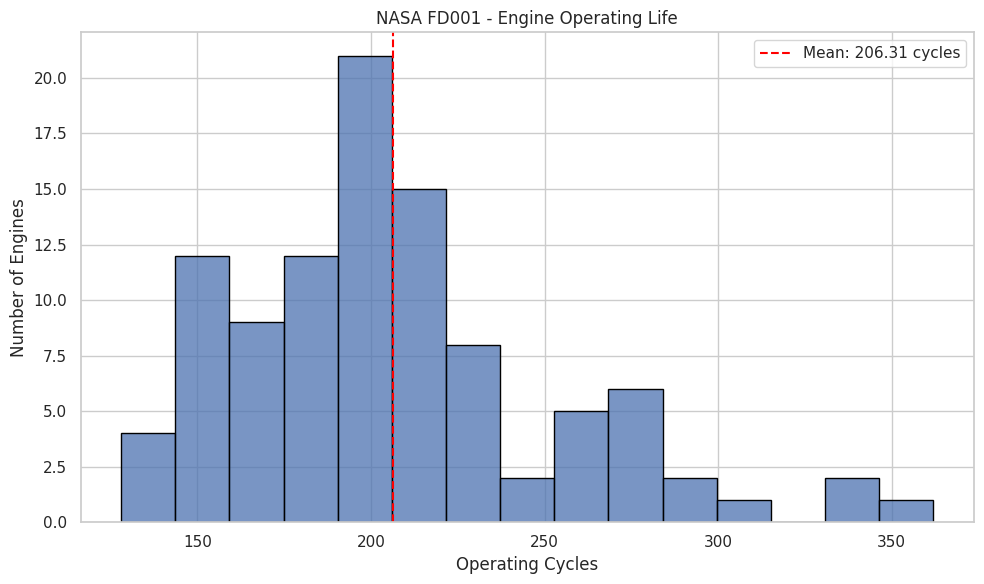

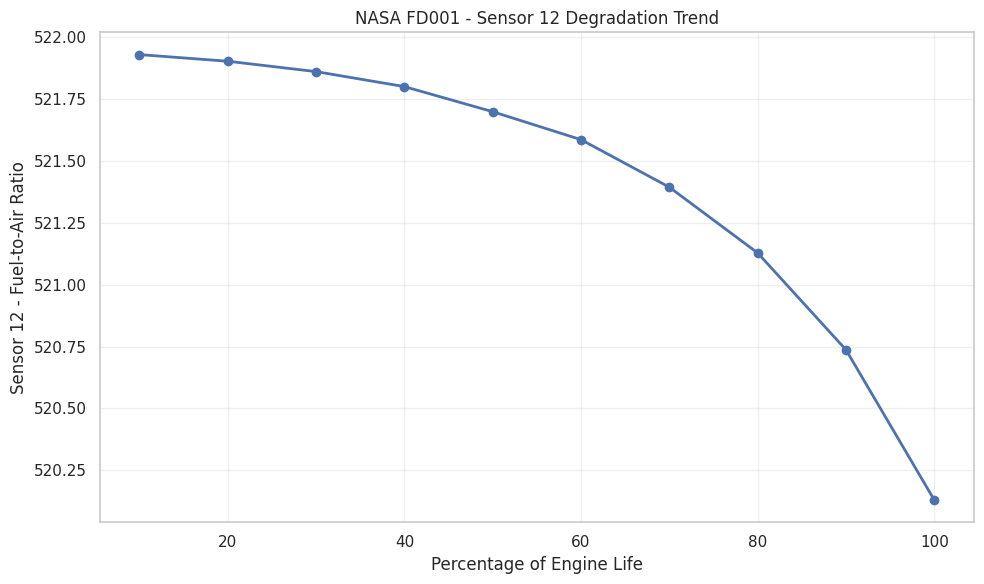

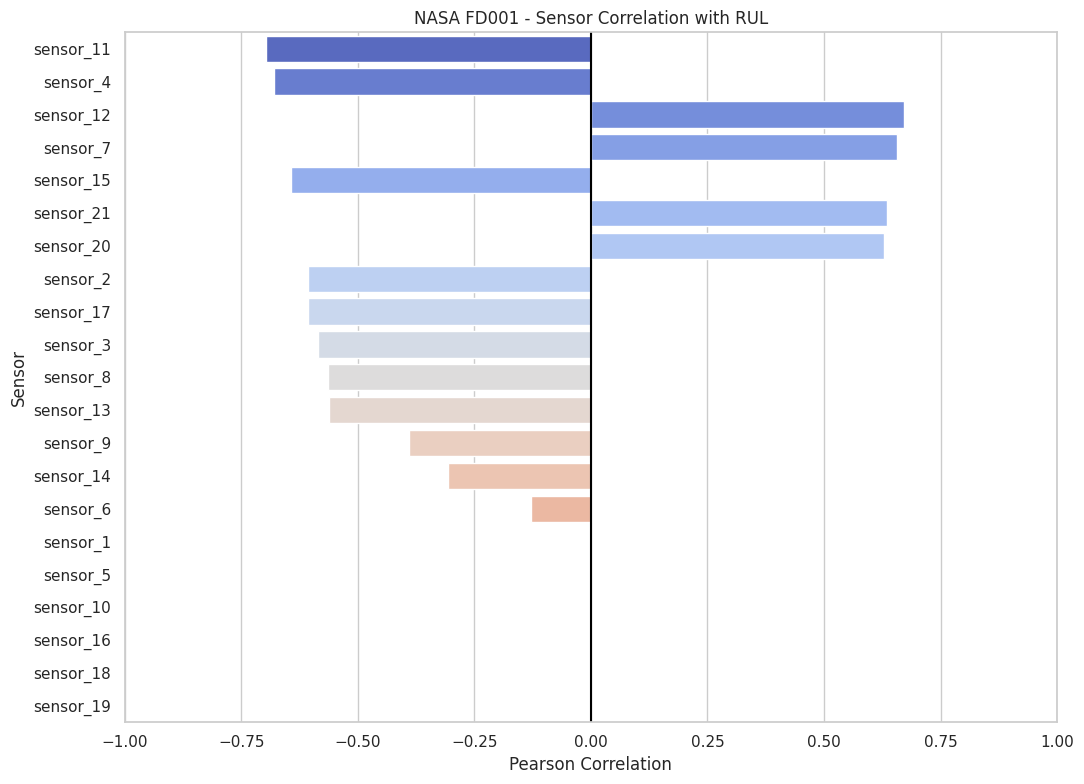

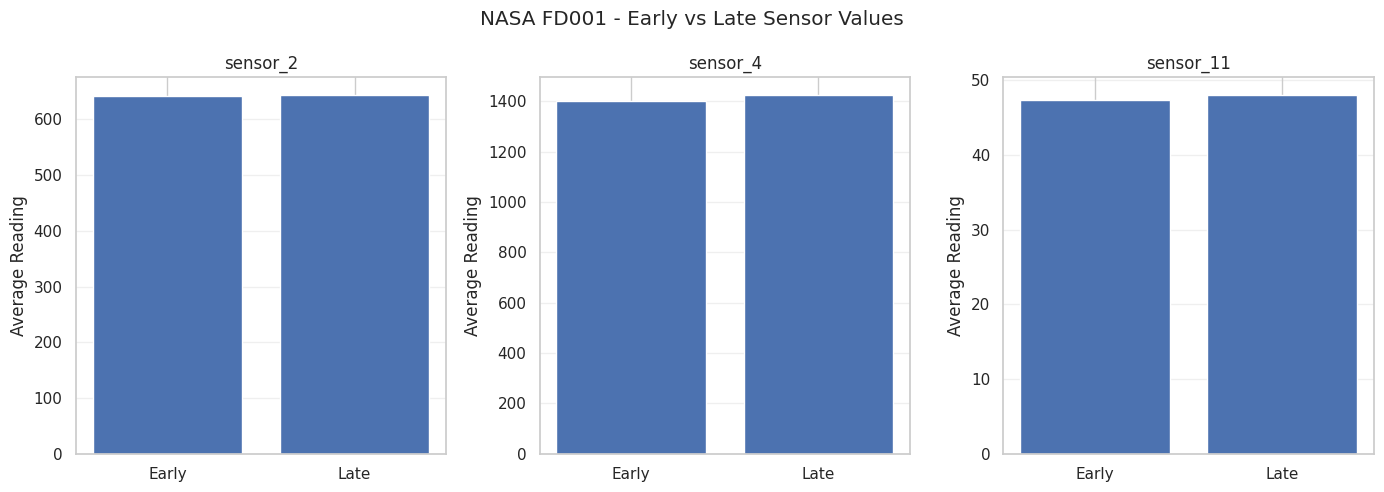


EDA EXPORT COMPLETE
----------------------
Saved visualizations:
engine_operating_life.png
sensor12_degradation.png
sensor_rul_correlations.png
temperature_pressure_changes.png

EDA summary saved:
/content/LM2500_Project/eda_summary.csv


In [31]:

# STEP 4 - CELL 6
# EDA Findings and Visualization Exports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Create output folders
project_folder = Path("/content/LM2500_Project")
visual_folder = project_folder / "Visualizations"

visual_folder.mkdir(parents=True, exist_ok=True)

# Use validated training data
eda_df = clean_train.copy()

# Calculate engine life and RUL
eda_df["max_cycle"] = (
    eda_df.groupby("engine_id")["cycle"]
    .transform("max")
)

eda_df["RUL"] = (
    eda_df["max_cycle"] - eda_df["cycle"]
)

eda_df["life_percent"] = (
    eda_df["cycle"] /
    eda_df["max_cycle"] * 100
)

engine_life = (
    eda_df.groupby("engine_id")["cycle"]
    .max()
)

# VISUAL 1: Engine Operating Life
plt.figure(figsize=(10, 6))

sns.histplot(
    engine_life,
    bins=15,
    edgecolor="black"
)

plt.axvline(
    engine_life.mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {engine_life.mean():.2f} cycles"
)

plt.title("NASA FD001 - Engine Operating Life")
plt.xlabel("Operating Cycles")
plt.ylabel("Number of Engines")
plt.legend()
plt.tight_layout()

plt.savefig(
    visual_folder / "engine_operating_life.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# VISUAL 2: Sensor 12 Degradation
eda_df["life_bin"] = pd.cut(
    eda_df["life_percent"],
    bins=np.arange(0, 101, 10),
    labels=np.arange(10, 101, 10),
    include_lowest=True
)

sensor12_trend = (
    eda_df.groupby("life_bin", observed=True)
    ["sensor_12"]
    .mean()
)

plt.figure(figsize=(10, 6))

plt.plot(
    sensor12_trend.index.astype(int),
    sensor12_trend.values,
    marker="o",
    linewidth=2
)

plt.title("NASA FD001 - Sensor 12 Degradation Trend")
plt.xlabel("Percentage of Engine Life")
plt.ylabel("Sensor 12 - Fuel-to-Air Ratio")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    visual_folder / "sensor12_degradation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# VISUAL 3: Sensor Correlation with RUL
sensor_cols = [
    f"sensor_{i}" for i in range(1, 22)
]

correlations = (
    eda_df[sensor_cols + ["RUL"]]
    .corr()["RUL"]
    .drop("RUL")
)

correlations = correlations.reindex(
    correlations.abs().sort_values(
        ascending=False
    ).index
)

plt.figure(figsize=(11, 8))

sns.barplot(
    x=correlations.values,
    y=correlations.index,
    hue=correlations.index,
    palette="coolwarm",
    legend=False
)

plt.axvline(0, color="black")
plt.xlim(-1, 1)
plt.title("NASA FD001 - Sensor Correlation with RUL")
plt.xlabel("Pearson Correlation")
plt.ylabel("Sensor")
plt.tight_layout()

plt.savefig(
    visual_folder / "sensor_rul_correlations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# VISUAL 4: Early vs Late Sensor Changes
selected = [
    "sensor_2",
    "sensor_4",
    "sensor_11"
]

early = eda_df[
    eda_df["life_percent"] <= 10
].groupby("engine_id")[selected].mean()

late = eda_df[
    eda_df["life_percent"] > 90
].groupby("engine_id")[selected].mean()

changes = (late - early).mean()

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, sensor in zip(axes, selected):
    ax.bar(
        ["Early", "Late"],
        [early[sensor].mean(), late[sensor].mean()]
    )
    ax.set_title(sensor)
    ax.set_ylabel("Average Reading")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("NASA FD001 - Early vs Late Sensor Values")
plt.tight_layout()

plt.savefig(
    visual_folder / "temperature_pressure_changes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save EDA summary
summary = pd.DataFrame({
    "Metric": [
        "Total Engines",
        "Average Engine Life",
        "Minimum Engine Life",
        "Maximum Engine Life",
        "Sensor 12 RUL Correlation",
        "Sensor 2 Mean Change",
        "Sensor 4 Mean Change",
        "Sensor 11 Mean Change"
    ],
    "Value": [
        int(engine_life.size),
        float(engine_life.mean()),
        int(engine_life.min()),
        int(engine_life.max()),
        float(correlations["sensor_12"]),
        float(changes["sensor_2"]),
        float(changes["sensor_4"]),
        float(changes["sensor_11"])
    ]
})

summary.to_csv(
    project_folder / "eda_summary.csv",
    index=False
)

print("\nEDA EXPORT COMPLETE")
print("----------------------")
print("Saved visualizations:")

for file in sorted(visual_folder.glob("*.png")):
    print(file.name)

print("\nEDA summary saved:")
print(project_folder / "eda_summary.csv")


In [32]:

# STEP 5 - CELL 1
# Establish Twin-Engine Comparison Profiles

import pandas as pd
import numpy as np
from pathlib import Path

# Load validated training data
df = clean_train.copy()

# Calculate each engine's operating life
engine_life = (
    df.groupby("engine_id")["cycle"]
    .max()
)

average_life = engine_life.mean()

# Engine A: closest to average lifespan
engine_a_id = (
    (engine_life - average_life)
    .abs()
    .idxmin()
)

# Engine B: shortest operating lifespan
engine_b_id = engine_life.idxmin()

# Extract engine operating histories
engine_a = (
    df[df["engine_id"] == engine_a_id]
    .copy()
    .sort_values("cycle")
)

engine_b = (
    df[df["engine_id"] == engine_b_id]
    .copy()
    .sort_values("cycle")
)

# Assign comparison labels
engine_a["engine_label"] = "Engine A"
engine_b["engine_label"] = "Engine B"

# Calculate normalized operating life
for engine in [engine_a, engine_b]:

    engine["max_cycle"] = engine["cycle"].max()

    engine["life_percent"] = (
        engine["cycle"] /
        engine["max_cycle"] * 100
    )

    engine["RUL"] = (
        engine["max_cycle"] - engine["cycle"]
    )

# Combine both engine histories
twin_engine_df = pd.concat(
    [engine_a, engine_b],
    ignore_index=True
)

# Create comparison summary
engine_summary = pd.DataFrame({
    "Engine": ["Engine A", "Engine B"],
    "NASA Engine ID": [engine_a_id, engine_b_id],
    "Operating Cycles": [
        engine_a["cycle"].max(),
        engine_b["cycle"].max()
    ],
    "Average Sensor 4": [
        engine_a["sensor_4"].mean(),
        engine_b["sensor_4"].mean()
    ],
    "Average Sensor 11": [
        engine_a["sensor_11"].mean(),
        engine_b["sensor_11"].mean()
    ],
    "Average Sensor 12": [
        engine_a["sensor_12"].mean(),
        engine_b["sensor_12"].mean()
    ]
})

print("TWIN-ENGINE PROFILE SELECTION")
print("--------------------------------")
print(f"Dataset average life: {average_life:.2f} cycles")
print(f"Engine A ID: {engine_a_id}")
print(f"Engine B ID: {engine_b_id}")

display(engine_summary.round(4))

# Save comparison datasets
output_folder = Path("/content/LM2500_Project")
output_folder.mkdir(parents=True, exist_ok=True)

twin_engine_df.to_csv(
    output_folder / "twin_engine_profiles.csv",
    index=False
)

engine_summary.to_csv(
    output_folder / "twin_engine_summary.csv",
    index=False
)

print("\nTwin-engine profiles saved successfully.")


TWIN-ENGINE PROFILE SELECTION
--------------------------------
Dataset average life: 206.31 cycles
Engine A ID: 15
Engine B ID: 39


,Engine,NASA Engine ID,Operating Cycles,Average Sensor 4,Average Sensor 11,Average Sensor 12
0,Engine A,15,207,1404.0257,47.4173,521.7797
1,Engine B,39,128,1414.0262,47.6914,520.9535



Twin-engine profiles saved successfully.


TWIN-ENGINE SENSOR COMPARISON
--------------------------------


engine_label,Engine A,Engine B,Difference (A - B),Difference (%)
LPC Outlet Temperature,642.4866,642.9580,-0.4714,-0.0733
LPT Outlet Temperature,1404.0257,1414.0262,-10.0005,-0.7072
HPC Outlet Static Pressure,47.4173,47.6914,-0.2741,-0.5748
Fuel-to-Air Ratio,521.7797,520.9535,0.8261,0.1586


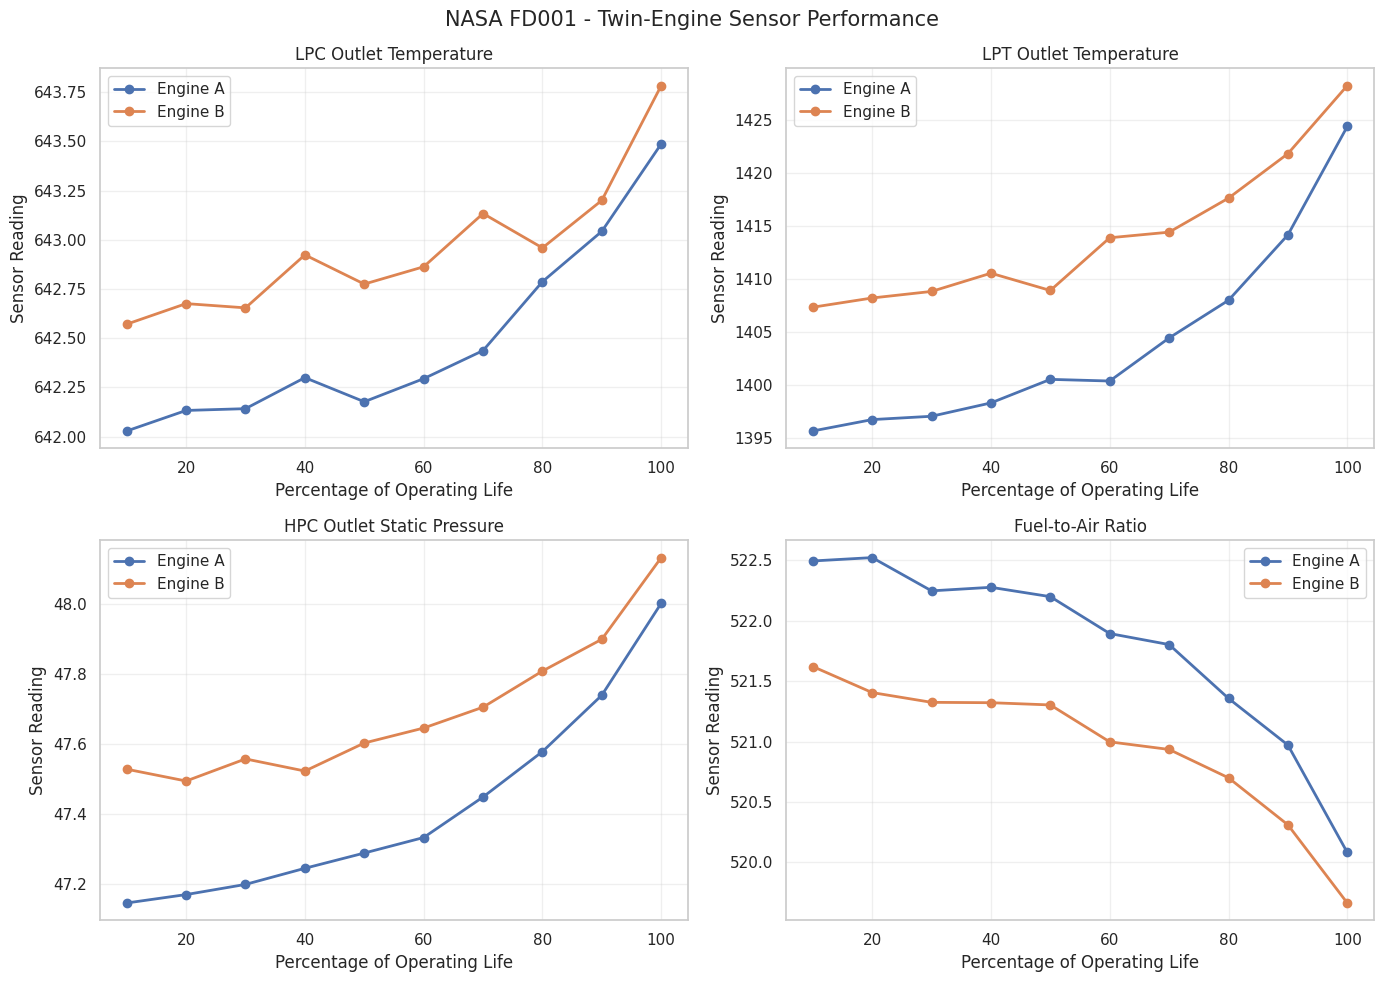

Sensor comparison saved successfully.


In [33]:

# STEP 5 - CELL 2
# Twin-Engine Operating Life and Sensor Comparison

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use the profiles created in Cell 1
df = twin_engine_df.copy()

selected_sensors = [
    "sensor_2",
    "sensor_4",
    "sensor_11",
    "sensor_12"
]

sensor_names = {
    "sensor_2": "LPC Outlet Temperature",
    "sensor_4": "LPT Outlet Temperature",
    "sensor_11": "HPC Outlet Static Pressure",
    "sensor_12": "Fuel-to-Air Ratio"
}

# Calculate average sensor readings by engine
sensor_comparison = (
    df.groupby("engine_label")[selected_sensors]
    .mean()
    .T
)

sensor_comparison["Difference (A - B)"] = (
    sensor_comparison["Engine A"]
    - sensor_comparison["Engine B"]
)

sensor_comparison["Difference (%)"] = (
    sensor_comparison["Difference (A - B)"]
    / sensor_comparison["Engine B"]
    * 100
)

sensor_comparison.index = [
    sensor_names[s] for s in selected_sensors
]

print("TWIN-ENGINE SENSOR COMPARISON")
print("--------------------------------")

display(sensor_comparison.round(4))

# Normalize engine operating life to percentage
df["life_bin"] = pd.cut(
    df["life_percent"],
    bins=np.arange(0, 101, 10),
    labels=np.arange(10, 101, 10),
    include_lowest=True
)

# Calculate sensor trends for each engine
sensor_trends = (
    df.groupby(
        ["engine_label", "life_bin"],
        observed=True
    )[selected_sensors]
    .mean()
    .reset_index()
)

sensor_trends["life_bin"] = (
    sensor_trends["life_bin"].astype(int)
)

# Create four comparison charts
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

for ax, sensor in zip(axes.flat, selected_sensors):

    for engine in ["Engine A", "Engine B"]:

        engine_data = sensor_trends[
            sensor_trends["engine_label"] == engine
        ]

        ax.plot(
            engine_data["life_bin"],
            engine_data[sensor],
            marker="o",
            linewidth=2,
            label=engine
        )

    ax.set_title(sensor_names[sensor])
    ax.set_xlabel("Percentage of Operating Life")
    ax.set_ylabel("Sensor Reading")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "NASA FD001 - Twin-Engine Sensor Performance",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Save comparison results
output_folder = "/content/LM2500_Project/"

sensor_comparison.to_csv(
    output_folder + "twin_engine_sensor_comparison.csv"
)

print("Sensor comparison saved successfully.")


TWIN-ENGINE DEGRADATION COMPARISON
----------------------------------


,Engine,Sensor,Measurement,Early Mean,Late Mean,Absolute Change,Percent Change
0,Engine A,sensor_2,LPC Outlet Temperature,642.0519,643.4876,1.4357,0.2236
1,Engine A,sensor_4,LPT Outlet Temperature,1395.6462,1424.3690,28.7229,2.0580
2,Engine A,sensor_11,HPC Outlet Static Pressure,47.1462,48.0019,0.8557,1.8150
3,Engine A,sensor_12,Fuel Flow / HPC Pressure Ratio,522.5014,520.0829,-2.4186,-0.4629
4,Engine B,sensor_2,LPC Outlet Temperature,642.6031,643.7838,1.1808,0.1837
5,Engine B,sensor_4,LPT Outlet Temperature,1406.9262,1428.2246,21.2985,1.5138
6,Engine B,sensor_11,HPC Outlet Static Pressure,47.5192,48.1323,0.6131,1.2902
7,Engine B,sensor_12,Fuel Flow / HPC Pressure Ratio,521.6115,519.6646,-1.9469,-0.3733


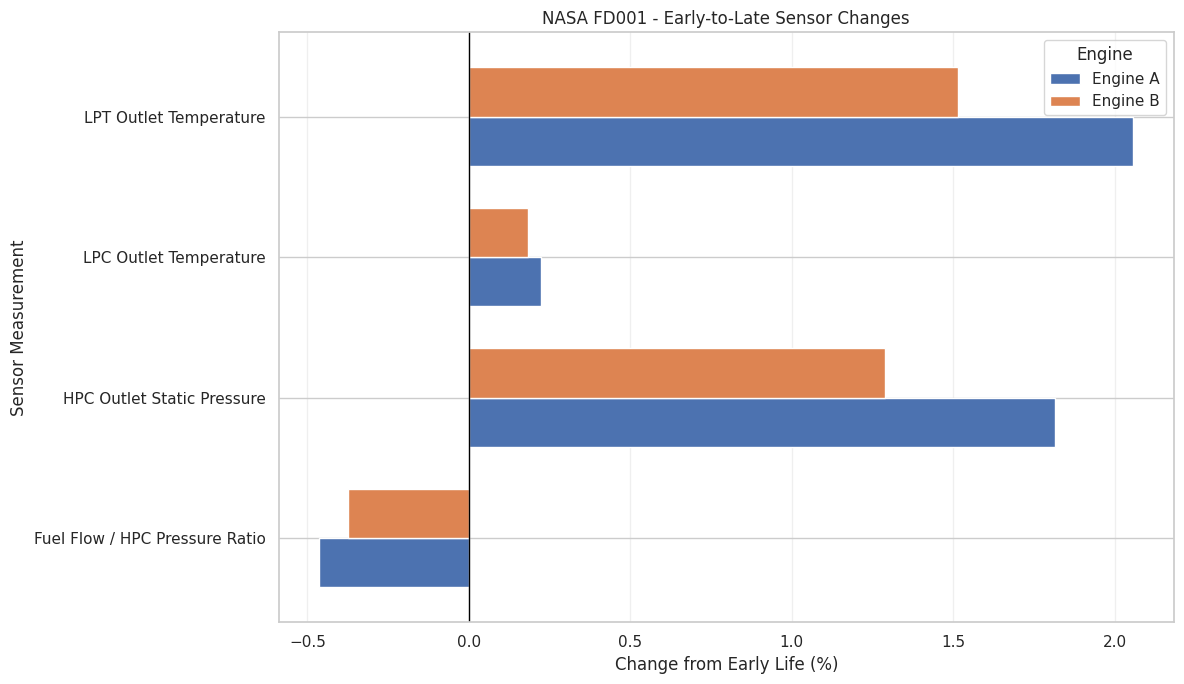

Twin-engine degradation analysis saved.


In [34]:

# STEP 5 - CELL 3
# Twin-Engine Temperature, Pressure, and Degradation Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

df = twin_engine_df.copy()

sensors = [
    "sensor_2",
    "sensor_4",
    "sensor_11",
    "sensor_12"
]

sensor_names = {
    "sensor_2": "LPC Outlet Temperature",
    "sensor_4": "LPT Outlet Temperature",
    "sensor_11": "HPC Outlet Static Pressure",
    "sensor_12": "Fuel Flow / HPC Pressure Ratio"
}

# Compare first and last 10% of each engine's cycles
results = []

for engine_label, group in df.groupby("engine_label"):

    group = group.sort_values("cycle")
    n = max(1, int(np.ceil(len(group) * 0.10)))

    early = group.head(n)
    late = group.tail(n)

    for sensor in sensors:

        early_mean = early[sensor].mean()
        late_mean = late[sensor].mean()
        change = late_mean - early_mean

        percent_change = (
            change / early_mean * 100
            if early_mean != 0 else np.nan
        )

        results.append({
            "Engine": engine_label,
            "Sensor": sensor,
            "Measurement": sensor_names[sensor],
            "Early Mean": early_mean,
            "Late Mean": late_mean,
            "Absolute Change": change,
            "Percent Change": percent_change
        })

degradation_df = pd.DataFrame(results)

print("TWIN-ENGINE DEGRADATION COMPARISON")
print("----------------------------------")

display(degradation_df.round(4))

# Create percent-change comparison chart
comparison = degradation_df.pivot(
    index="Measurement",
    columns="Engine",
    values="Percent Change"
)

ax = comparison.plot(
    kind="barh",
    figsize=(12, 7),
    width=0.7
)

ax.axvline(0, color="black", linewidth=1)
ax.set_title("NASA FD001 - Early-to-Late Sensor Changes")
ax.set_xlabel("Change from Early Life (%)")
ax.set_ylabel("Sensor Measurement")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# Save results
output_folder = Path("/content/LM2500_Project")
output_folder.mkdir(parents=True, exist_ok=True)

degradation_df.to_csv(
    output_folder / "twin_engine_degradation.csv",
    index=False
)

print("Twin-engine degradation analysis saved.")


EXPERIMENTAL ENGINE HEALTH COMPARISON
--------------------------------------


,Average_Score,Minimum_Score,Maximum_Score
engine_label,,,
Engine A,51.04,17.88,89.67
Engine B,39.53,16.53,77.59


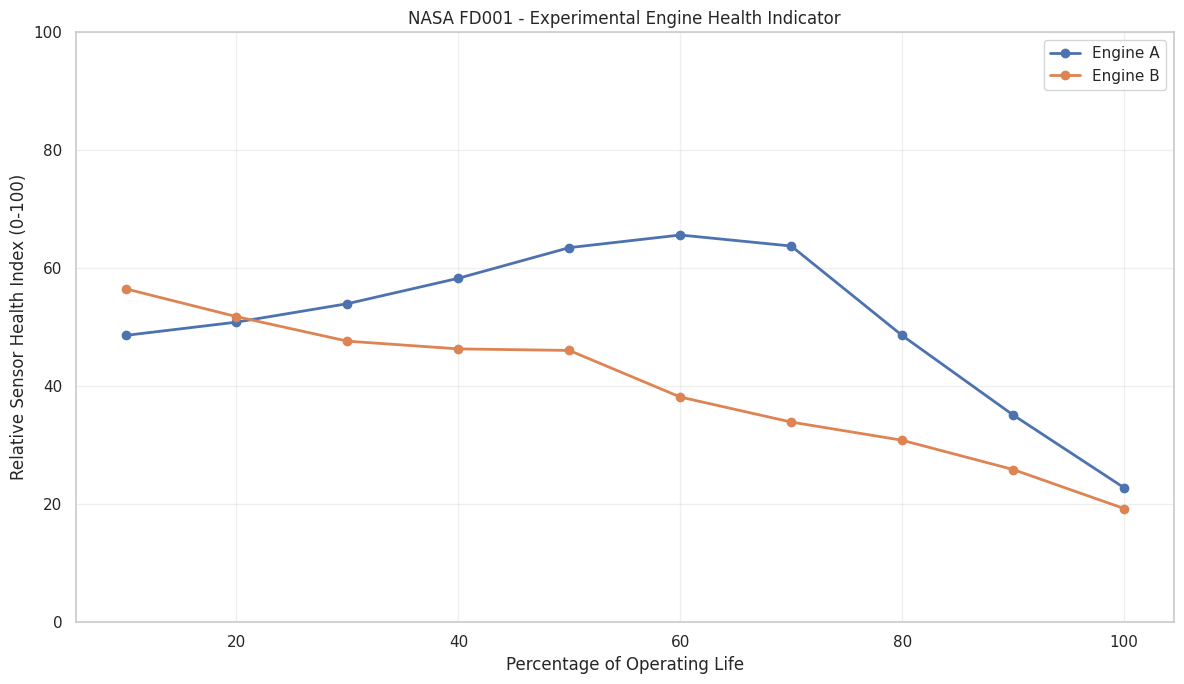

Experimental health analysis saved.


In [35]:

# STEP 5 - CELL 4
# Experimental Comparative Engine Health Indicator

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

sensors = [
    "sensor_2",
    "sensor_4",
    "sensor_11",
    "sensor_12"
]

# Reference population: first 10% of each
# training engine's operating history
reference_df = clean_train.copy()

reference_df["max_cycle"] = (
    reference_df.groupby("engine_id")["cycle"]
    .transform("max")
)

reference_df["life_fraction"] = (
    reference_df["cycle"] /
    reference_df["max_cycle"]
)

# Exclude Engines A and B from reference fitting
reference_df = reference_df[
    ~reference_df["engine_id"].isin(
        [engine_a_id, engine_b_id]
    )
]

early_reference = reference_df[
    reference_df["life_fraction"] <= 0.10
]

reference_mean = early_reference[sensors].mean()
reference_std = early_reference[sensors].std()

# Prevent division by zero
reference_std = reference_std.replace(0, np.nan)

# Use twin-engine dataset
health_df = twin_engine_df.copy()

# Calculate standardized sensor deviations
z_scores = (
    health_df[sensors] - reference_mean
) / reference_std

# Average absolute deviation across sensors
health_df["deviation_index"] = (
    z_scores.abs().mean(axis=1)
)

# Convert to a bounded experimental score
# 100 = matches early-life reference
# Lower = greater sensor deviation
health_df["health_score"] = (
    100 / (1 + health_df["deviation_index"])
)

# Confirm score validity
assert health_df["health_score"].notna().all()
assert health_df["health_score"].between(0, 100).all()

# Calculate score trends by operating-life interval
health_df["life_bin"] = pd.cut(
    health_df["life_percent"],
    bins=np.arange(0, 101, 10),
    labels=np.arange(10, 101, 10),
    include_lowest=True
)

health_trends = (
    health_df.groupby(
        ["engine_label", "life_bin"],
        observed=True
    )["health_score"]
    .mean()
    .reset_index()
)

health_trends["life_bin"] = (
    health_trends["life_bin"].astype(int)
)

# Summarize each engine's experimental score
health_summary = (
    health_df.groupby("engine_label")
    .agg(
        Average_Score=("health_score", "mean"),
        Minimum_Score=("health_score", "min"),
        Maximum_Score=("health_score", "max")
    )
)

print("EXPERIMENTAL ENGINE HEALTH COMPARISON")
print("--------------------------------------")
display(health_summary.round(2))

# Plot health indicator trends
plt.figure(figsize=(12, 7))

for engine in ["Engine A", "Engine B"]:

    engine_data = health_trends[
        health_trends["engine_label"] == engine
    ]

    plt.plot(
        engine_data["life_bin"],
        engine_data["health_score"],
        marker="o",
        linewidth=2,
        label=engine
    )

plt.title(
    "NASA FD001 - Experimental Engine Health Indicator"
)

plt.xlabel("Percentage of Operating Life")
plt.ylabel("Relative Sensor Health Index (0-100)")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Save results
output_folder = Path("/content/LM2500_Project")
output_folder.mkdir(parents=True, exist_ok=True)

health_df.to_csv(
    output_folder / "twin_engine_health_scores.csv",
    index=False
)

health_summary.to_csv(
    output_folder / "twin_engine_health_summary.csv"
)

print("Experimental health analysis saved.")


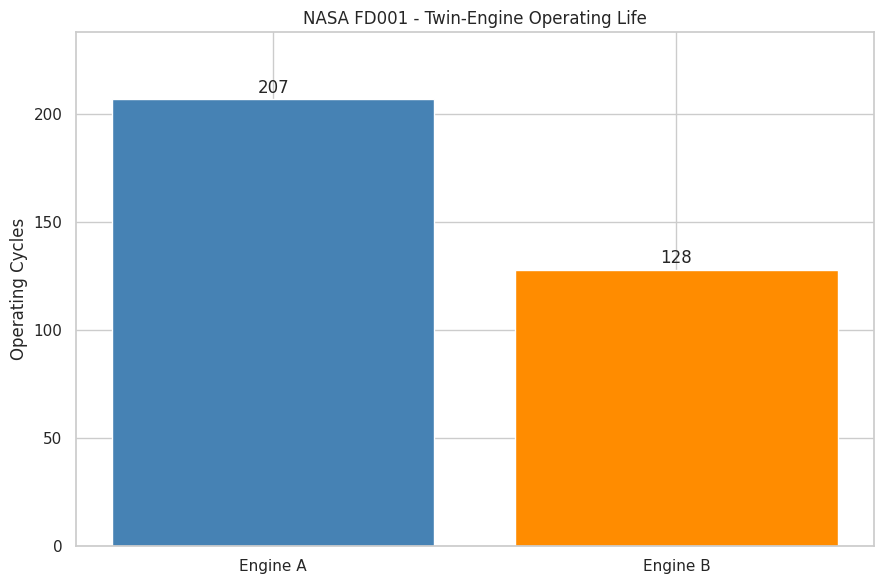

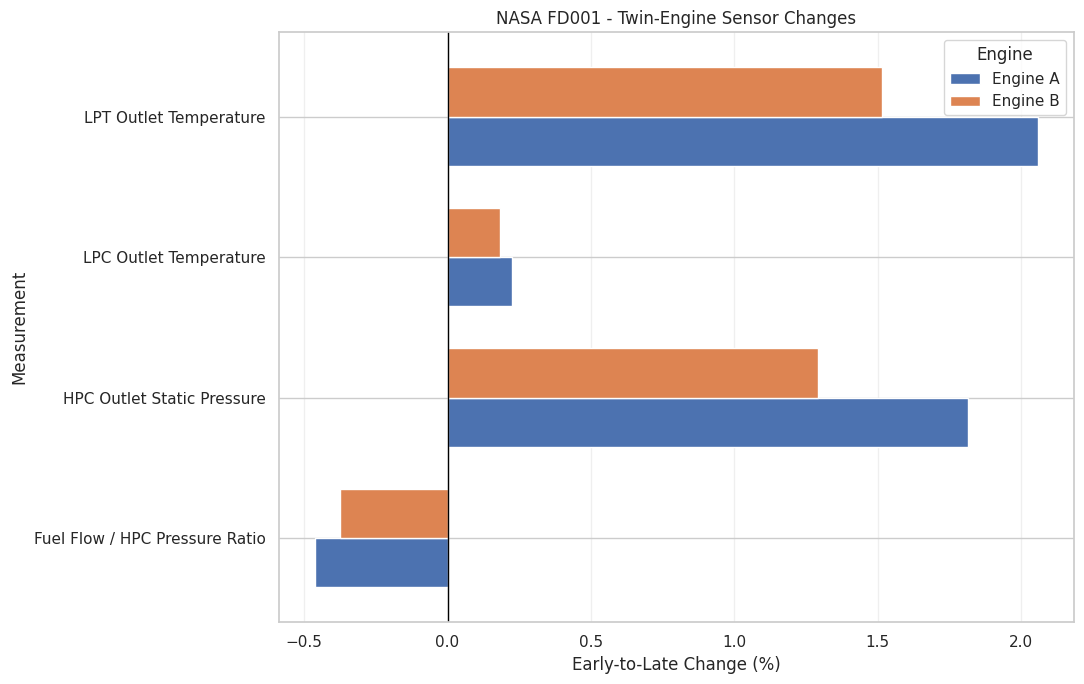

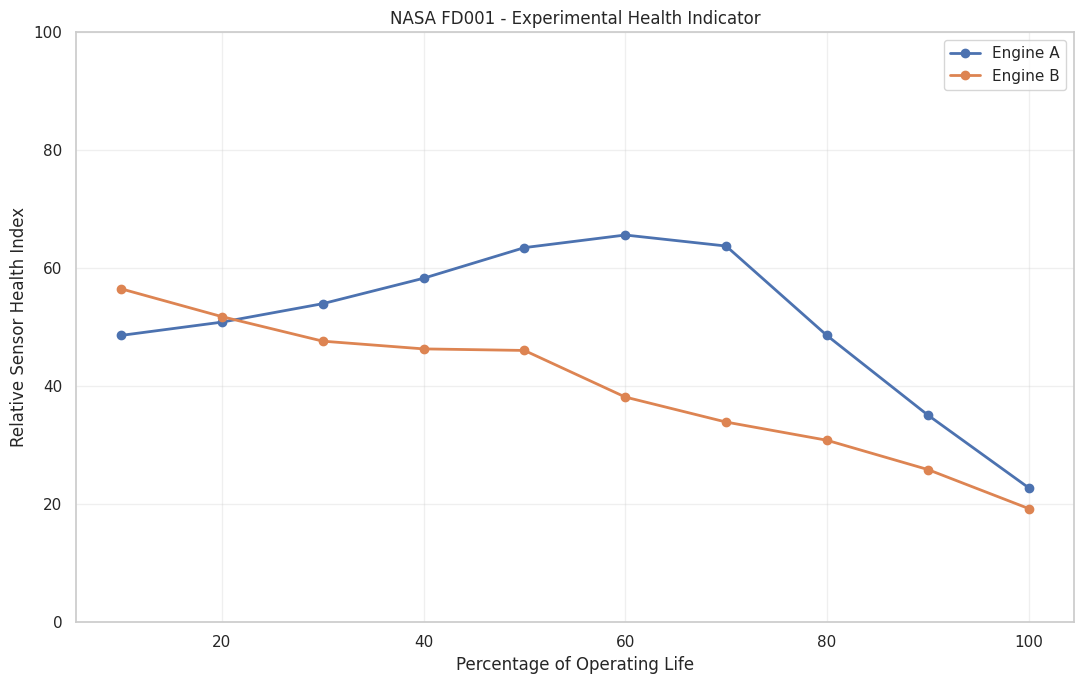


STEP 5 EXPORT COMPLETE
-----------------------

Final engine summary:


,Engine,NASA_Engine_ID,Operating_Cycles,Average_Health_Index,Minimum_Health_Index,Maximum_Health_Index
0,Engine A,15,207,51.04,17.88,89.67
1,Engine B,39,128,39.53,16.53,77.59



Saved visualizations:
twin_engine_health_trends.png
twin_engine_operating_life.png
twin_engine_sensor_changes.png

Saved report:
twin_engine_engineering_report.md

Saved summary:
twin_engine_final_summary.csv


In [36]:

# STEP 5 - CELL 5
# Twin-Engine Findings and Visualization Exports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project_folder = Path("/content/LM2500_Project")
visual_folder = project_folder / "Visualizations"
visual_folder.mkdir(parents=True, exist_ok=True)

# 1. Operating life comparison
life_data = (
    twin_engine_df.groupby("engine_label")["cycle"]
    .max()
    .reindex(["Engine A", "Engine B"])
)

plt.figure(figsize=(9, 6))

bars = plt.bar(
    life_data.index,
    life_data.values,
    color=["steelblue", "darkorange"]
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 3,
        f"{bar.get_height():.0f}",
        ha="center"
    )

plt.title("NASA FD001 - Twin-Engine Operating Life")
plt.ylabel("Operating Cycles")
plt.ylim(0, life_data.max() * 1.15)
plt.tight_layout()

plt.savefig(
    visual_folder / "twin_engine_operating_life.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 2. Early-to-late sensor changes
change_pivot = degradation_df.pivot(
    index="Measurement",
    columns="Engine",
    values="Percent Change"
)

ax = change_pivot.plot(
    kind="barh",
    figsize=(11, 7),
    width=0.7
)

ax.axvline(0, color="black", linewidth=1)
ax.set_title("NASA FD001 - Twin-Engine Sensor Changes")
ax.set_xlabel("Early-to-Late Change (%)")
ax.set_ylabel("Measurement")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    visual_folder / "twin_engine_sensor_changes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 3. Experimental health score trends
plt.figure(figsize=(11, 7))

for engine in ["Engine A", "Engine B"]:
    data = health_trends[
        health_trends["engine_label"] == engine
    ]

    plt.plot(
        data["life_bin"],
        data["health_score"],
        marker="o",
        linewidth=2,
        label=engine
    )

plt.title(
    "NASA FD001 - Experimental Health Indicator"
)
plt.xlabel("Percentage of Operating Life")
plt.ylabel("Relative Sensor Health Index")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    visual_folder / "twin_engine_health_trends.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 4. Build combined engine summary
final_summary = pd.DataFrame({
    "Engine": ["Engine A", "Engine B"],
    "NASA_Engine_ID": [engine_a_id, engine_b_id],
    "Operating_Cycles": [
        int(life_data["Engine A"]),
        int(life_data["Engine B"])
    ],
    "Average_Health_Index": [
        health_summary.loc["Engine A", "Average_Score"],
        health_summary.loc["Engine B", "Average_Score"]
    ],
    "Minimum_Health_Index": [
        health_summary.loc["Engine A", "Minimum_Score"],
        health_summary.loc["Engine B", "Minimum_Score"]
    ],
    "Maximum_Health_Index": [
        health_summary.loc["Engine A", "Maximum_Score"],
        health_summary.loc["Engine B", "Maximum_Score"]
    ]
})

final_summary.to_csv(
    project_folder / "twin_engine_final_summary.csv",
    index=False
)

# 5. Generate engineering report
life_difference = (
    int(life_data["Engine A"])
    - int(life_data["Engine B"])
)

score_difference = (
    health_summary.loc["Engine A", "Average_Score"]
    - health_summary.loc["Engine B", "Average_Score"]
)

report = f"""# Twin-Engine Performance Analysis

## Project
LM2500 Marine Gas Turbine Performance &
Predictive Maintenance Analytics

## Dataset
NASA C-MAPSS FD001 simulated aircraft engine data.

These are independent simulated turbofan histories,
not actual LM2500 marine gas turbines.

## Engine Profiles
- Engine A: NASA engine {engine_a_id}
- Engine B: NASA engine {engine_b_id}
- Engine A operating life: {int(life_data['Engine A'])} cycles
- Engine B operating life: {int(life_data['Engine B'])} cycles
- Operating life difference: {life_difference} cycles

## Experimental Health Indicator
- Engine A average: {health_summary.loc['Engine A', 'Average_Score']:.2f}
- Engine B average: {health_summary.loc['Engine B', 'Average_Score']:.2f}
- Difference: {score_difference:.2f} points

The indicator measures sensor deviation from an
early-life reference. It is not a validated
mechanical health or failure prediction score.

## Engineering Findings
1. Engine A operated longer than Engine B.
2. Engine B had a higher average LPT outlet temperature.
3. Engine A had larger early-to-late relative changes
   across the four selected sensors.
4. Engine A had a higher average experimental
   health index.
5. Operating life, sensor change, and health index
   are different measures and should not be
   treated as interchangeable.

## Limitations
- Aircraft simulation data, not marine field data.
- Engines were not operating simultaneously.
- Operating conditions may affect sensor differences.
- No validated maintenance alarm thresholds.
- No causal conclusions about failure mechanisms.

## Next Phase
Step 6: Predictive Maintenance and Failure Analysis.
"""

report_path = (
    project_folder / "twin_engine_engineering_report.md"
)

report_path.write_text(report, encoding="utf-8")

print("\nSTEP 5 EXPORT COMPLETE")
print("-----------------------")

print("\nFinal engine summary:")
display(final_summary.round(2))

print("\nSaved visualizations:")
for file in sorted(
    visual_folder.glob("twin_engine_*.png")
):
    print(file.name)

print("\nSaved report:")
print(report_path.name)

print("\nSaved summary:")
print("twin_engine_final_summary.csv")


In [37]:

# STEP 6 - CELL 1
# Prepare RUL Machine Learning Dataset

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import GroupShuffleSplit

# Load validated NASA training dataset
ml_df = clean_train.copy()

# Calculate true RUL for historical training records
ml_df["max_cycle"] = (
    ml_df.groupby("engine_id")["cycle"]
    .transform("max")
)

ml_df["RUL"] = (
    ml_df["max_cycle"] - ml_df["cycle"]
)

# Select operational settings and sensor features
feature_cols = (
    ["setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

target_col = "RUL"

X = ml_df[feature_cols].copy()
y = ml_df[target_col].copy()
groups = ml_df["engine_id"]

# Split entire engines into training and validation sets
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

train_engine_ids = set(
    groups.iloc[train_idx].unique()
)

val_engine_ids = set(
    groups.iloc[val_idx].unique()
)

# Verify there is no engine overlap
assert train_engine_ids.isdisjoint(val_engine_ids)

# Verify selected features have no missing values
assert X_train.notna().all().all()
assert X_val.notna().all().all()

# Check target and feature dimensions
print("RUL MACHINE LEARNING DATASET")
print("--------------------------------")
print(f"Total observations: {len(ml_df):,}")
print(f"Total engines: {groups.nunique()}")
print(f"Input features: {len(feature_cols)}")

print("\nTRAINING SET")
print(f"Engines: {len(train_engine_ids)}")
print(f"Observations: {len(X_train):,}")

print("\nVALIDATION SET")
print(f"Engines: {len(val_engine_ids)}")
print(f"Observations: {len(X_val):,}")

print("\nRUL STATISTICS")
print(ml_df["RUL"].describe().round(2))

print("\nEngine overlap:", len(
    train_engine_ids.intersection(val_engine_ids)
))

# Save split information for reproducibility
split_info = pd.DataFrame({
    "engine_id": sorted(groups.unique())
})

split_info["dataset_split"] = (
    split_info["engine_id"]
    .apply(
        lambda x: "Train"
        if x in train_engine_ids
        else "Validation"
    )
)

output_folder = Path("/content/LM2500_Project")
output_folder.mkdir(parents=True, exist_ok=True)

split_info.to_csv(
    output_folder / "rul_engine_split.csv",
    index=False
)

print("\nEngine-level split saved successfully.")


RUL MACHINE LEARNING DATASET
--------------------------------
Total observations: 20,631
Total engines: 100
Input features: 24

TRAINING SET
Engines: 80
Observations: 16,561

VALIDATION SET
Engines: 20
Observations: 4,070

RUL STATISTICS
count    20631.00
mean       107.81
std         68.88
min          0.00
25%         51.00
50%        103.00
75%        155.00
max        361.00
Name: RUL, dtype: float64

Engine overlap: 0

Engine-level split saved successfully.


In [38]:

# STEP 6 - CELL 2
# Train Baseline Random Forest RUL Model

import numpy as np
import pandas as pd
import joblib
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Initialize Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Train on the 80 training engines
print("Training Random Forest RUL model...")

rf_model.fit(X_train, y_train)

print("Model training complete.")

# Generate predictions for unseen validation engines
y_pred = rf_model.predict(X_val)

# RUL cannot be negative
y_pred = np.maximum(y_pred, 0)

# Calculate baseline performance
mae = mean_absolute_error(y_val, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_val, y_pred)
)

r2 = r2_score(y_val, y_pred)

print("\nBASELINE MODEL PERFORMANCE")
print("--------------------------------")
print(f"Mean Absolute Error: {mae:.2f} cycles")
print(f"Root Mean Squared Error: {rmse:.2f} cycles")
print(f"R-squared Score: {r2:.4f}")

# Save model performance
model_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Value": [mae, rmse, r2]
})

output_folder = Path("/content/LM2500_Project")
output_folder.mkdir(parents=True, exist_ok=True)

model_results.to_csv(
    output_folder / "rul_baseline_model_metrics.csv",
    index=False
)

# Save trained model
joblib.dump(
    rf_model,
    output_folder / "rul_random_forest_model.joblib"
)

print("\nModel and metrics saved successfully.")


Training Random Forest RUL model...
Model training complete.

BASELINE MODEL PERFORMANCE
--------------------------------
Mean Absolute Error: 25.71 cycles
Root Mean Squared Error: 35.20 cycles
R-squared Score: 0.7126

Model and metrics saved successfully.


MODEL ACCURACY COMPARISON
-------------------------


,Model,MAE,RMSE,R2
0,Mean RUL Baseline,55.3633,65.7154,-0.0019
1,Random Forest,25.7124,35.1956,0.7126


MAE improvement: 53.56%
RMSE improvement: 46.44%


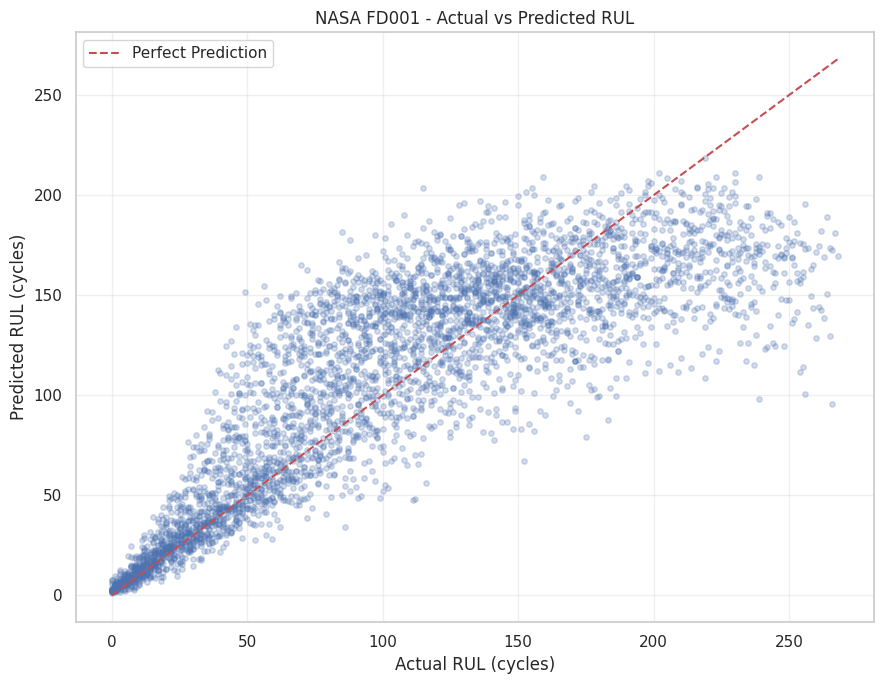

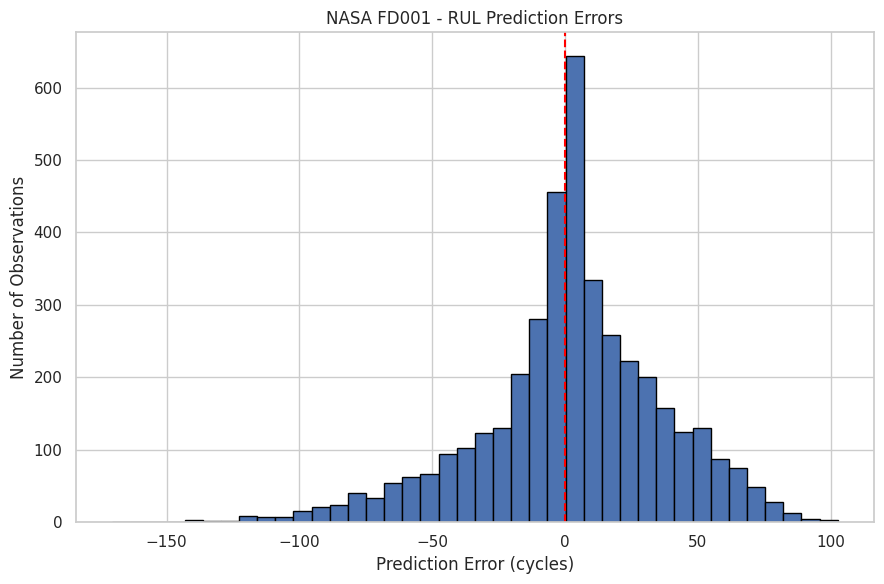


Model comparison and predictions saved.


In [39]:

# STEP 6 - CELL 3
# Model Accuracy and Baseline Evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Baseline: predict training-set average RUL
baseline_value = y_train.mean()

baseline_pred = np.full(
    shape=len(y_val),
    fill_value=baseline_value
)

# Evaluate baseline
baseline_mae = mean_absolute_error(
    y_val, baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_val, baseline_pred)
)

baseline_r2 = r2_score(
    y_val, baseline_pred
)

# Evaluate trained Random Forest
rf_mae = mean_absolute_error(y_val, y_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_val, y_pred)
)

rf_r2 = r2_score(y_val, y_pred)

# Calculate improvements
mae_improvement = (
    (baseline_mae - rf_mae)
    / baseline_mae * 100
)

rmse_improvement = (
    (baseline_rmse - rf_rmse)
    / baseline_rmse * 100
)

# Display comparison
comparison_df = pd.DataFrame({
    "Model": [
        "Mean RUL Baseline",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        rf_rmse
    ],
    "R2": [
        baseline_r2,
        rf_r2
    ]
})

print("MODEL ACCURACY COMPARISON")
print("-------------------------")

display(comparison_df.round(4))

print(
    f"MAE improvement: {mae_improvement:.2f}%"
)

print(
    f"RMSE improvement: {rmse_improvement:.2f}%"
)

# Create prediction results table
prediction_results = pd.DataFrame({
    "engine_id": ml_df.iloc[
        val_idx
    ]["engine_id"].to_numpy(),
    "cycle": ml_df.iloc[
        val_idx
    ]["cycle"].to_numpy(),
    "Actual_RUL": y_val.to_numpy(),
    "Predicted_RUL": y_pred
})

prediction_results["Error"] = (
    prediction_results["Predicted_RUL"]
    - prediction_results["Actual_RUL"]
)

prediction_results["Absolute_Error"] = (
    prediction_results["Error"].abs()
)

# Actual vs predicted plot
plt.figure(figsize=(9, 7))

plt.scatter(
    prediction_results["Actual_RUL"],
    prediction_results["Predicted_RUL"],
    alpha=0.25,
    s=15
)

max_rul = max(
    prediction_results["Actual_RUL"].max(),
    prediction_results["Predicted_RUL"].max()
)

plt.plot(
    [0, max_rul],
    [0, max_rul],
    "r--",
    label="Perfect Prediction"
)

plt.title("NASA FD001 - Actual vs Predicted RUL")
plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Prediction error histogram
plt.figure(figsize=(9, 6))

plt.hist(
    prediction_results["Error"],
    bins=40,
    edgecolor="black"
)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.title("NASA FD001 - RUL Prediction Errors")
plt.xlabel("Prediction Error (cycles)")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

# Save comparison and predictions
output_folder = Path("/content/LM2500_Project")
output_folder.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    output_folder / "rul_model_comparison.csv",
    index=False
)

prediction_results.to_csv(
    output_folder / "rul_validation_predictions.csv",
    index=False
)

print("\nModel comparison and predictions saved.")


TOP 10 IMPORTANT FEATURES
--------------------------


,Feature,Importance
0,sensor_11,0.49349
1,sensor_9,0.13431
2,sensor_4,0.07781
3,sensor_12,0.04143
4,sensor_14,0.03572
5,sensor_7,0.03291
6,sensor_15,0.02779
7,sensor_21,0.02586
8,sensor_3,0.02281
9,sensor_2,0.02199


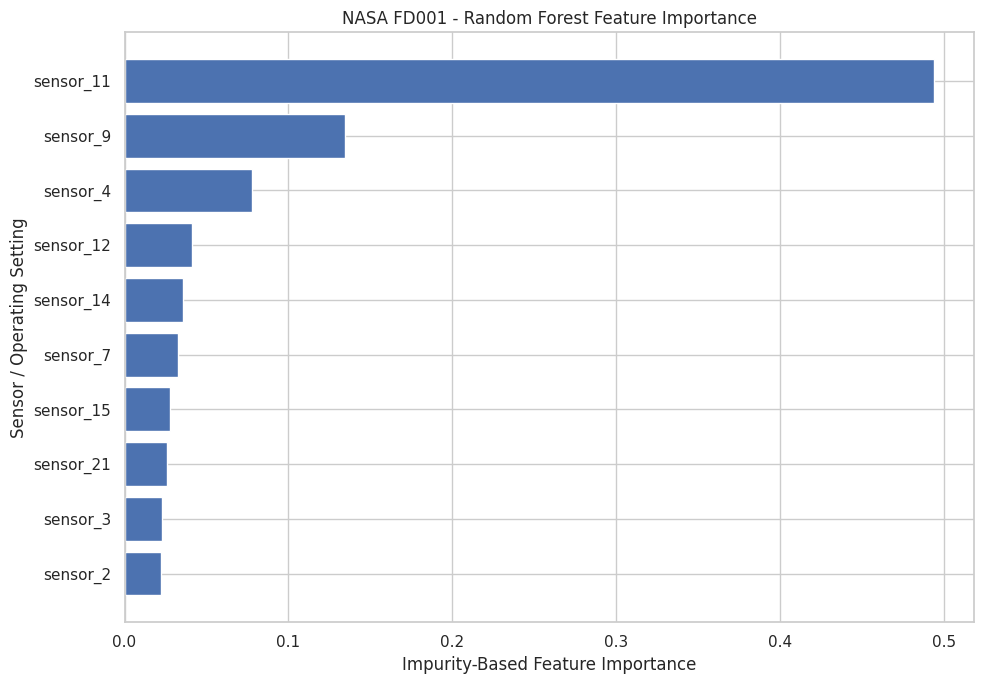


PREDICTION ERROR BY RUL CATEGORY
--------------------------------


,RUL_Category,Observations,MAE,RMSE,Mean_Error,Maximum_Absolute_Error
0,Near Failure (0-30),620,6.05,9.08,4.33,48.87
1,Intermediate (31-100),1400,26.83,35.41,21.37,102.64
2,Longer Life (101+),2050,30.89,39.73,-11.20,170.52


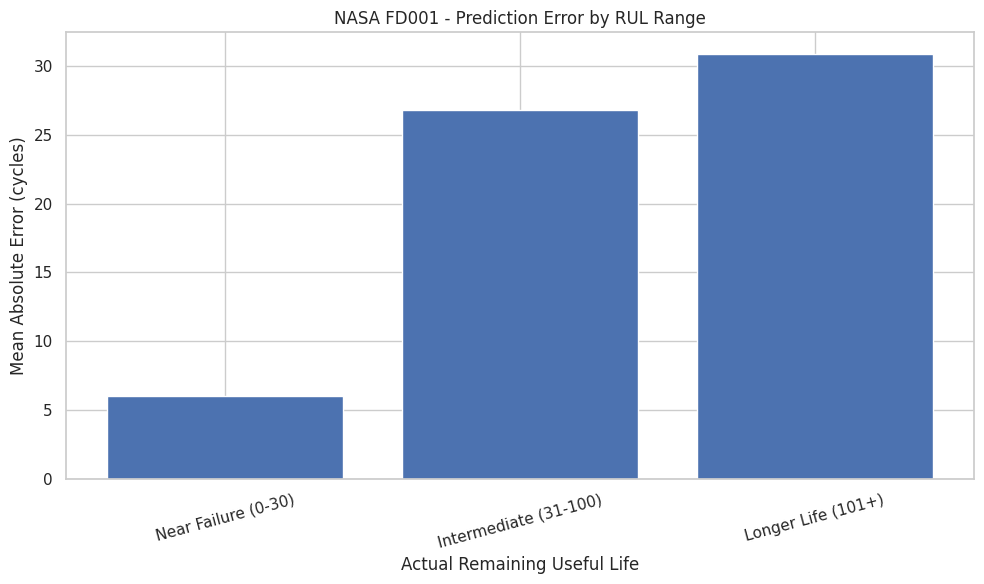


NEAR-FAILURE PREDICTION ANALYSIS
--------------------------------
Near-failure observations: 620
Overestimation frequency: 75.16%
Mean signed prediction error: 4.33 cycles

Feature importance and error analysis saved.


In [40]:

# STEP 6 - CELL 4
# Feature Importance and RUL Prediction Error Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------------------
# 1. Random Forest Feature Importance
# ---------------------------------------

importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("TOP 10 IMPORTANT FEATURES")
print("--------------------------")

display(importance_df.head(10).round(5))

# Plot top 10 features
top_features = importance_df.head(10)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("NASA FD001 - Random Forest Feature Importance")
plt.xlabel("Impurity-Based Feature Importance")
plt.ylabel("Sensor / Operating Setting")
plt.tight_layout()
plt.show()

# ---------------------------------------
# 2. Prediction Error by RUL Range
# ---------------------------------------

error_df = prediction_results.copy()

error_df["RUL_Category"] = pd.cut(
    error_df["Actual_RUL"],
    bins=[-1, 30, 100, np.inf],
    labels=[
        "Near Failure (0-30)",
        "Intermediate (31-100)",
        "Longer Life (101+)"
    ]
)

# Calculate MAE, RMSE, and signed bias
error_summary = (
    error_df.groupby(
        "RUL_Category",
        observed=True
    )
    .agg(
        Observations=("Absolute_Error", "count"),
        MAE=("Absolute_Error", "mean"),
        RMSE=("Error", lambda x: np.sqrt(np.mean(x**2))),
        Mean_Error=("Error", "mean"),
        Maximum_Absolute_Error=("Absolute_Error", "max")
    )
    .reset_index()
)

print("\nPREDICTION ERROR BY RUL CATEGORY")
print("--------------------------------")

display(error_summary.round(2))

# ---------------------------------------
# 3. Compare MAE Across RUL Categories
# ---------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    error_summary["RUL_Category"].astype(str),
    error_summary["MAE"]
)

plt.title("NASA FD001 - Prediction Error by RUL Range")
plt.xlabel("Actual Remaining Useful Life")
plt.ylabel("Mean Absolute Error (cycles)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# ---------------------------------------
# 4. Near-Failure Overestimation
# ---------------------------------------

near_failure = error_df[
    error_df["Actual_RUL"] <= 30
].copy()

near_failure_overestimate = (
    near_failure["Error"] > 0
).mean() * 100

near_failure_mean_error = (
    near_failure["Error"].mean()
)

print("\nNEAR-FAILURE PREDICTION ANALYSIS")
print("--------------------------------")

print(
    f"Near-failure observations: {len(near_failure)}"
)

print(
    f"Overestimation frequency: "
    f"{near_failure_overestimate:.2f}%"
)

print(
    f"Mean signed prediction error: "
    f"{near_failure_mean_error:.2f} cycles"
)

# ---------------------------------------
# 5. Save Results
# ---------------------------------------

output_folder = Path("/content/LM2500_Project")
output_folder.mkdir(parents=True, exist_ok=True)

importance_df.to_csv(
    output_folder / "rul_feature_importance.csv",
    index=False
)

error_summary.to_csv(
    output_folder / "rul_error_by_category.csv",
    index=False
)

print("\nFeature importance and error analysis saved.")


TWIN-ENGINE RUL PREDICTION COMPARISON
--------------------------------------


,engine_label,engine_id,Model_Split,Operating_Cycles,MAE,Mean_Signed_Error,Maximum_Absolute_Error
0,Engine A,15,Training (in-sample),207,25.33,22.75,71.67
1,Engine B,39,Training (in-sample),128,18.11,17.92,51.41


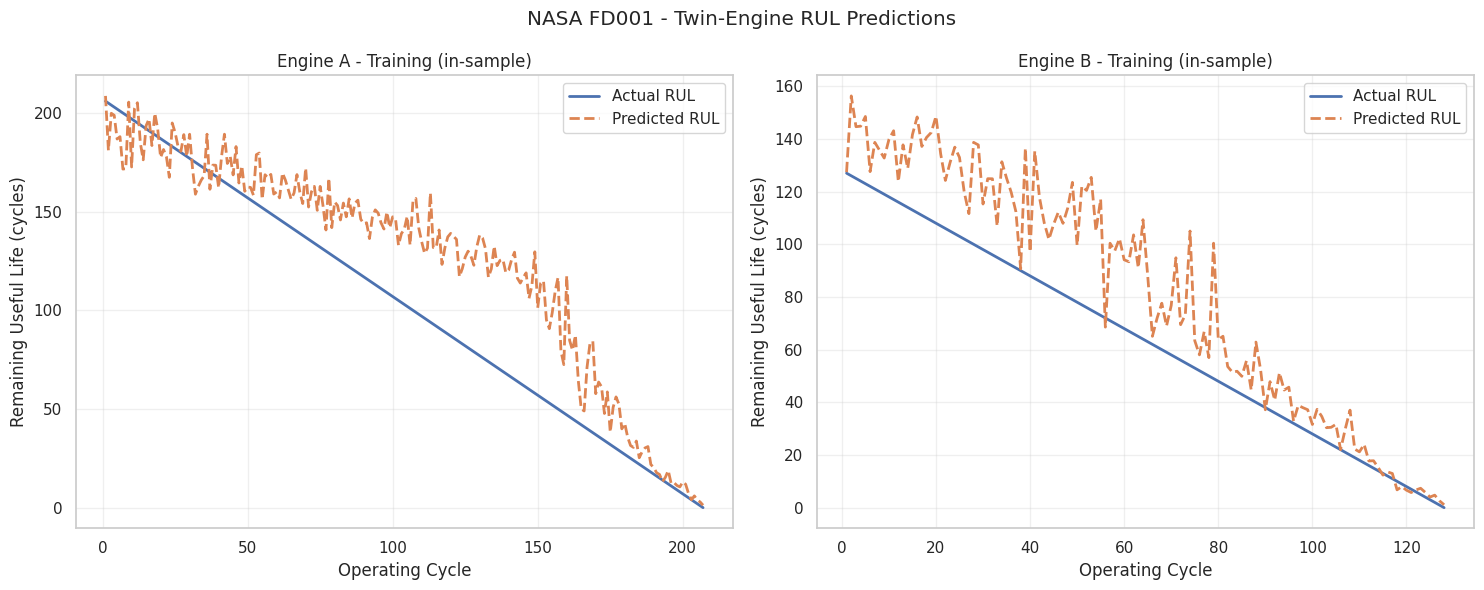


NEAR-FAILURE COMPARISON
------------------------


,engine_label,Observations,Near_Failure_MAE,Mean_Signed_Error,Overestimation_Rate
0,Engine A,31,6.30,6.24,96.77
1,Engine B,31,4.09,3.61,83.87



Twin-engine RUL prediction files saved.


In [41]:

# STEP 6 - CELL 5
# Compare RUL Predictions for Engines A and B

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error

# Use the two engine histories from Step 5
comparison_df = twin_engine_df.copy()

# Determine whether each engine was used in training
def identify_split(engine_id):
    if engine_id in train_engine_ids:
        return "Training (in-sample)"
    elif engine_id in val_engine_ids:
        return "Validation (unseen)"
    else:
        return "Not in split"

comparison_df["Model_Split"] = (
    comparison_df["engine_id"].apply(identify_split)
)

# Predict RUL using the same features as training
comparison_df["Predicted_RUL"] = np.maximum(
    rf_model.predict(comparison_df[feature_cols]),
    0
)

# Calculate actual RUL independently
comparison_df["Actual_RUL"] = (
    comparison_df.groupby("engine_id")["cycle"]
    .transform("max")
    - comparison_df["cycle"]
)

# Calculate errors
comparison_df["Prediction_Error"] = (
    comparison_df["Predicted_RUL"]
    - comparison_df["Actual_RUL"]
)

comparison_df["Absolute_Error"] = (
    comparison_df["Prediction_Error"].abs()
)

# Summarize results for each engine
engine_results = (
    comparison_df.groupby(
        ["engine_label", "engine_id", "Model_Split"]
    )
    .agg(
        Operating_Cycles=("cycle", "max"),
        MAE=("Absolute_Error", "mean"),
        Mean_Signed_Error=("Prediction_Error", "mean"),
        Maximum_Absolute_Error=("Absolute_Error", "max")
    )
    .reset_index()
)

print("TWIN-ENGINE RUL PREDICTION COMPARISON")
print("--------------------------------------")
display(engine_results.round(2))

# Plot actual vs predicted RUL
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

for ax, engine in zip(
    axes,
    ["Engine A", "Engine B"]
):
    engine_data = comparison_df[
        comparison_df["engine_label"] == engine
    ].sort_values("cycle")

    split_name = engine_data["Model_Split"].iloc[0]

    ax.plot(
        engine_data["cycle"],
        engine_data["Actual_RUL"],
        label="Actual RUL",
        linewidth=2
    )

    ax.plot(
        engine_data["cycle"],
        engine_data["Predicted_RUL"],
        label="Predicted RUL",
        linewidth=2,
        linestyle="--"
    )

    ax.set_title(f"{engine} - {split_name}")
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Remaining Useful Life (cycles)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "NASA FD001 - Twin-Engine RUL Predictions"
)
plt.tight_layout()
plt.show()

# Compare prediction errors near failure
near_failure = comparison_df[
    comparison_df["Actual_RUL"] <= 30
].copy()

near_failure_summary = (
    near_failure.groupby("engine_label")
    .agg(
        Observations=("Absolute_Error", "count"),
        Near_Failure_MAE=("Absolute_Error", "mean"),
        Mean_Signed_Error=("Prediction_Error", "mean"),
        Overestimation_Rate=(
            "Prediction_Error",
            lambda x: (x > 0).mean() * 100
        )
    )
    .reset_index()
)

print("\nNEAR-FAILURE COMPARISON")
print("------------------------")
display(near_failure_summary.round(2))

# Save results
output_folder = Path("/content/LM2500_Project")
output_folder.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    output_folder / "twin_engine_rul_predictions.csv",
    index=False
)

engine_results.to_csv(
    output_folder / "twin_engine_rul_model_summary.csv",
    index=False
)

near_failure_summary.to_csv(
    output_folder / "twin_engine_near_failure_summary.csv",
    index=False
)

print("\nTwin-engine RUL prediction files saved.")


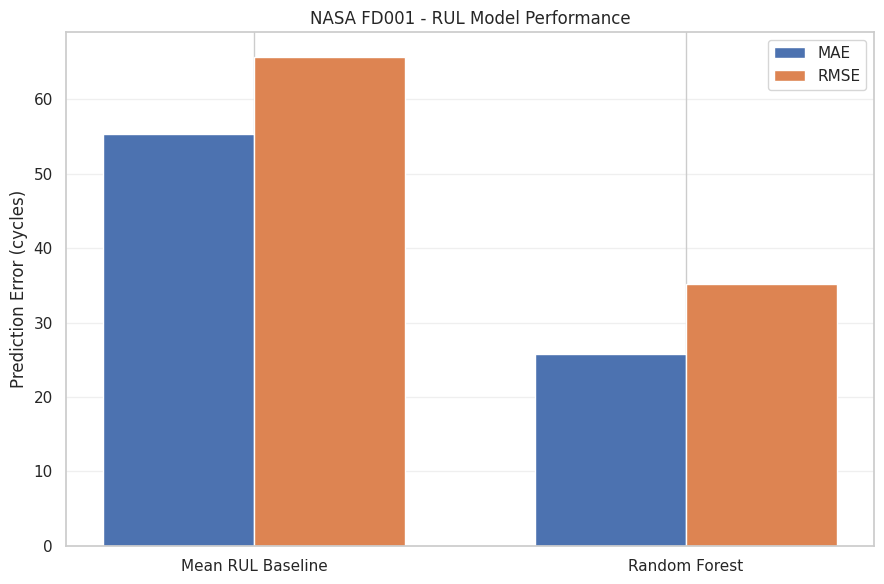

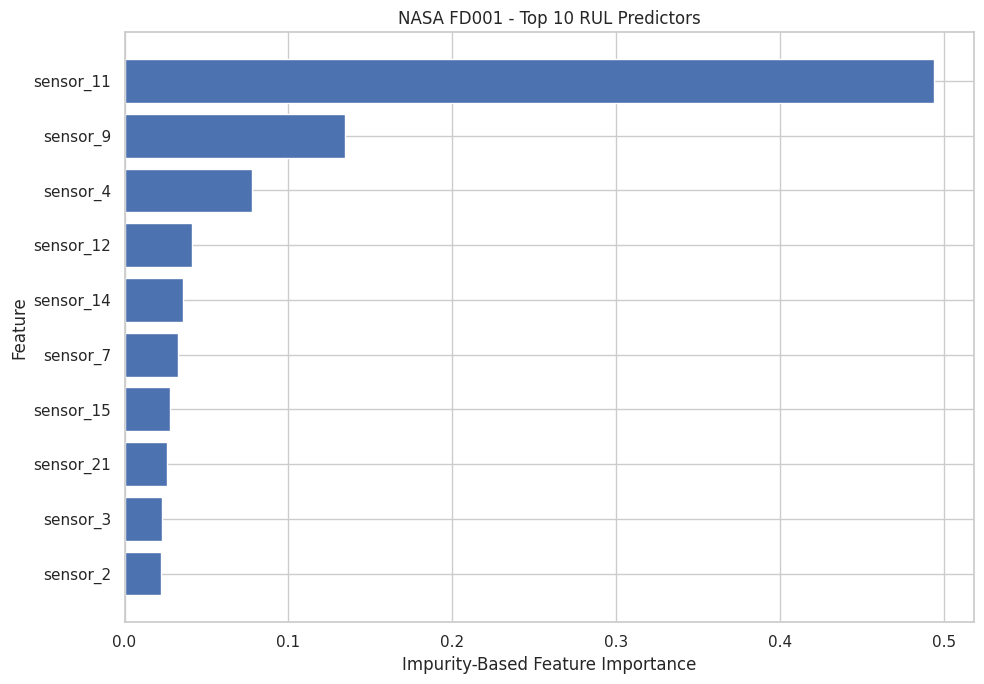

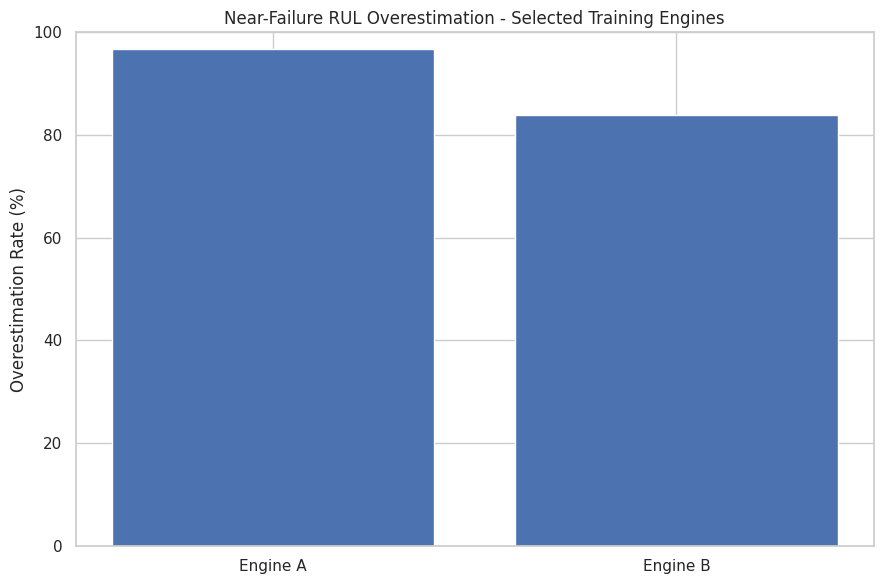

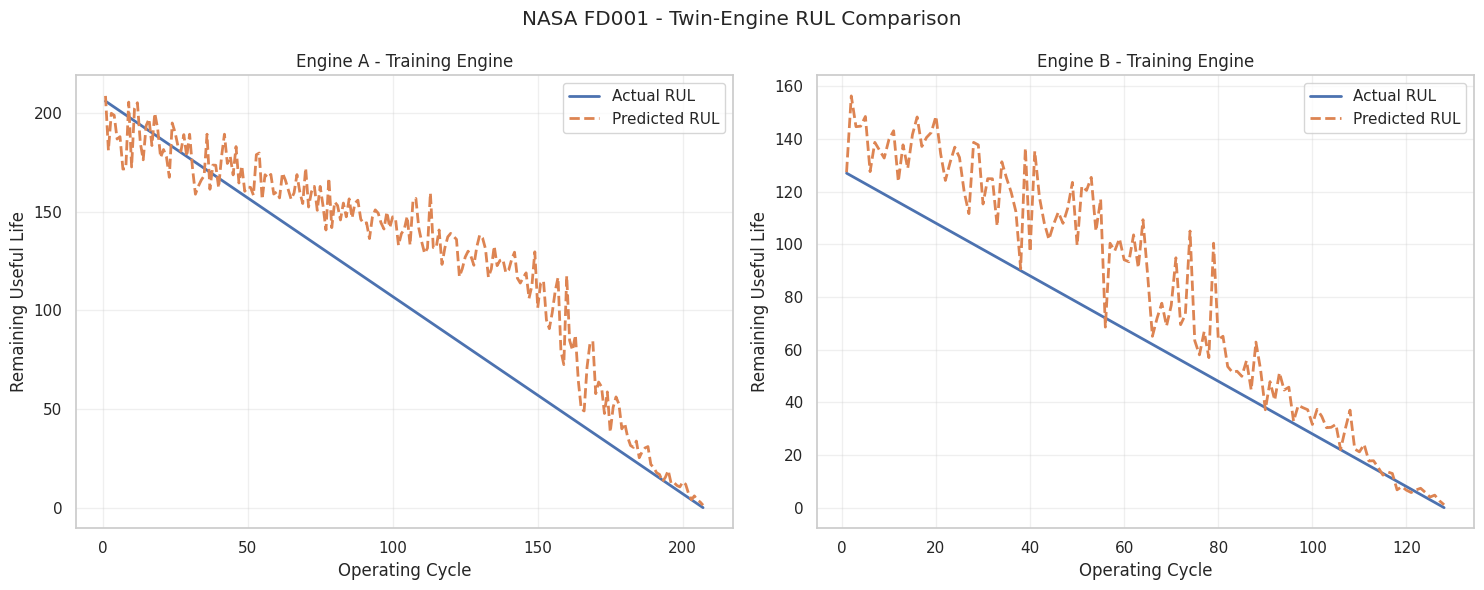


STEP 6 EXPORT COMPLETE
----------------------

Saved visualizations:
rul_feature_importance.png
rul_model_performance.png
rul_near_failure_overestimation.png
sensor_rul_correlations.png
twin_engine_rul_comparison.png

Saved engineering report:
predictive_maintenance_engineering_report.md

Saved summary:
predictive_maintenance_summary.csv

Final model summary:


,Metric,Value
0,Training Engines,80
1,Validation Engines,20
2,Training Observations,16561
3,Validation Observations,4070
4,Random Forest MAE,25.7124
5,Random Forest RMSE,35.1956
6,Random Forest R2,0.7126
7,Baseline MAE,55.3633
8,Baseline RMSE,65.7154
9,MAE Improvement (%),53.56


In [42]:

# STEP 6 - CELL 6
# Final Predictive Maintenance Report and Exports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------------------
# 1. Create Output Directories
# ---------------------------------------

output_folder = Path("/content/LM2500_Project")
visual_folder = output_folder / "Visualizations"

output_folder.mkdir(parents=True, exist_ok=True)
visual_folder.mkdir(parents=True, exist_ok=True)

# ---------------------------------------
# 2. Model Performance Comparison Chart
# ---------------------------------------

metrics_chart = (
    globals()["comparison_df"]
    if False else None
)

# Reload the model comparison to avoid
# conflict with the twin-engine dataframe
model_metrics = pd.read_csv(
    output_folder / "rul_model_comparison.csv"
)

x = np.arange(len(model_metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(
    x - width / 2,
    model_metrics["MAE"],
    width,
    label="MAE"
)

ax.bar(
    x + width / 2,
    model_metrics["RMSE"],
    width,
    label="RMSE"
)

ax.set_xticks(x)
ax.set_xticklabels(model_metrics["Model"])
ax.set_ylabel("Prediction Error (cycles)")
ax.set_title("NASA FD001 - RUL Model Performance")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    visual_folder / "rul_model_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------
# 3. Feature Importance Chart
# ---------------------------------------

top_features = importance_df.head(10)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Impurity-Based Feature Importance")
plt.ylabel("Feature")
plt.title("NASA FD001 - Top 10 RUL Predictors")

plt.tight_layout()

plt.savefig(
    visual_folder / "rul_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------
# 4. Near-Failure Error Comparison
# ---------------------------------------

plt.figure(figsize=(9, 6))

plt.bar(
    near_failure_summary["engine_label"],
    near_failure_summary["Overestimation_Rate"]
)

plt.ylabel("Overestimation Rate (%)")
plt.ylim(0, 100)

plt.title(
    "Near-Failure RUL Overestimation - "
    "Selected Training Engines"
)

plt.tight_layout()

plt.savefig(
    visual_folder / "rul_near_failure_overestimation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------
# 5. Twin-Engine Prediction Chart
# ---------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

for ax, engine in zip(
    axes,
    ["Engine A", "Engine B"]
):
    data = comparison_df[
        comparison_df["engine_label"] == engine
    ].sort_values("cycle")

    ax.plot(
        data["cycle"],
        data["Actual_RUL"],
        label="Actual RUL",
        linewidth=2
    )

    ax.plot(
        data["cycle"],
        data["Predicted_RUL"],
        label="Predicted RUL",
        linestyle="--",
        linewidth=2
    )

    ax.set_title(
        f"{engine} - Training Engine"
    )

    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Remaining Useful Life")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "NASA FD001 - Twin-Engine RUL Comparison"
)

plt.tight_layout()

plt.savefig(
    visual_folder / "twin_engine_rul_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ---------------------------------------
# 6. Consolidated Summary
# ---------------------------------------

summary = pd.DataFrame({
    "Metric": [
        "Training Engines",
        "Validation Engines",
        "Training Observations",
        "Validation Observations",
        "Random Forest MAE",
        "Random Forest RMSE",
        "Random Forest R2",
        "Baseline MAE",
        "Baseline RMSE",
        "MAE Improvement (%)",
        "RMSE Improvement (%)",
        "Top Predictive Feature",
        "Top Feature Importance"
    ],
    "Value": [
        len(train_engine_ids),
        len(val_engine_ids),
        len(X_train),
        len(X_val),
        round(rf_mae, 4),
        round(rf_rmse, 4),
        round(rf_r2, 4),
        round(baseline_mae, 4),
        round(baseline_rmse, 4),
        round(mae_improvement, 2),
        round(rmse_improvement, 2),
        importance_df.iloc[0]["Feature"],
        round(
            importance_df.iloc[0]["Importance"],
            5
        )
    ]
})

summary.to_csv(
    output_folder / "predictive_maintenance_summary.csv",
    index=False
)

# ---------------------------------------
# 7. Engineering Report
# ---------------------------------------

report = f"""# Predictive Maintenance and RUL Analysis

## Project
LM2500 Marine Gas Turbine Performance &
Predictive Maintenance Analytics

## Data Provenance
NASA C-MAPSS FD001 simulated aircraft turbofan
run-to-failure dataset.

The analysis is an educational marine gas turbine
analytics case study. The data does not represent
actual LM2500 marine engine measurements.

## Dataset
- Total engines: {ml_df['engine_id'].nunique()}
- Total observations: {len(ml_df)}
- Training engines: {len(train_engine_ids)}
- Validation engines: {len(val_engine_ids)}
- Input features: {len(feature_cols)}

## Predictive Model
Random Forest Regressor, 200 trees,
maximum depth 15, minimum leaf size 3.

## Independent Engine-Level Validation
- MAE: {rf_mae:.2f} cycles
- RMSE: {rf_rmse:.2f} cycles
- R-squared: {rf_r2:.4f}

## Mean RUL Baseline
- MAE: {baseline_mae:.2f} cycles
- RMSE: {baseline_rmse:.2f} cycles
- MAE improvement: {mae_improvement:.2f}%
- RMSE improvement: {rmse_improvement:.2f}%

## Most Important Model Feature
- Feature: {importance_df.iloc[0]['Feature']}
- Impurity-based importance:
  {importance_df.iloc[0]['Importance']:.5f}

Importance is model-specific and does not
establish physical causation.

## Twin-Engine Case Study
Engine A: NASA engine 15, 207 cycles.
Engine B: NASA engine 39, 128 cycles.

Both selected engines were included in training.
Their prediction errors are in-sample results,
not independent validation results.

### Engine A
- Overall MAE: 25.33 cycles
- Mean signed error: +22.75 cycles
- Near-failure MAE: 6.30 cycles
- Near-failure overestimation: 96.77%

### Engine B
- Overall MAE: 18.11 cycles
- Mean signed error: +17.92 cycles
- Near-failure MAE: 4.09 cycles
- Near-failure overestimation: 83.87%

## Engineering Findings
1. Sensor measurements contain useful information
   for estimating simulated remaining engine life.
2. The Random Forest outperformed a constant
   mean-RUL prediction baseline.
3. HPC outlet static pressure (Sensor 11)
   was the most important model feature.
4. Prediction bias varies with actual RUL.
5. Overestimation near simulated failure warrants
   further evaluation before any maintenance use.

## Recommendations
1. Evaluate prediction errors on additional
   unseen engine histories.
2. Investigate RUL calibration and uncertainty.
3. Test rolling sensor trends and temporal features.
4. Compare Random Forest with other RUL models.
5. Evaluate conservative maintenance-alert
   strategies on independent validation data.
6. Obtain representative LM2500 operational data
   before considering marine field deployment.

## Limitations
- NASA FD001 is simulated aircraft engine data.
- Dataset cycles are not LM2500 operating hours.
- The model is not validated for LM2500 service.
- The selected twin-engine results are in-sample.
- Feature importance is not a causal measure.
- RUL predictions are not maintenance approvals.
"""

report_path = (
    output_folder /
    "predictive_maintenance_engineering_report.md"
)

report_path.write_text(
    report,
    encoding="utf-8"
)

# ---------------------------------------
# 8. Verify Saved Deliverables
# ---------------------------------------

print("\nSTEP 6 EXPORT COMPLETE")
print("----------------------")

print("\nSaved visualizations:")

for file in sorted(
    visual_folder.glob("*rul*.png")
):
    print(file.name)

print("\nSaved engineering report:")
print(report_path.name)

print("\nSaved summary:")
print("predictive_maintenance_summary.csv")

print("\nFinal model summary:")
display(summary)


In [43]:

# STEP 7 - CELL 1
# Create SQLite Operational Database

import sqlite3
import pandas as pd
from pathlib import Path

# ---------------------------------------
# 1. Set project paths
# ---------------------------------------

project_folder = Path("/content/LM2500_Project")
project_folder.mkdir(parents=True, exist_ok=True)

db_path = project_folder / "lm2500_engine_analytics.db"

# ---------------------------------------
# 2. Prepare engine operations table
# ---------------------------------------

operations_df = ml_df[
    ["engine_id", "cycle"]
    + feature_cols
    + ["RUL"]
].copy()

# Validate unique engine-cycle records
assert not operations_df.duplicated(
    subset=["engine_id", "cycle"]
).any()

assert operations_df["RUL"].ge(0).all()

# ---------------------------------------
# 3. Load validation predictions
# ---------------------------------------

predictions_df = pd.read_csv(
    project_folder / "rul_validation_predictions.csv"
)

required_columns = [
    "engine_id",
    "cycle",
    "Actual_RUL",
    "Predicted_RUL",
    "Error",
    "Absolute_Error"
]

assert all(
    col in predictions_df.columns
    for col in required_columns
)

assert not predictions_df.duplicated(
    subset=["engine_id", "cycle"]
).any()

# ---------------------------------------
# 4. Create SQLite database
# ---------------------------------------

conn = sqlite3.connect(db_path)

operations_df.to_sql(
    "engine_operations",
    conn,
    if_exists="replace",
    index=False
)

predictions_df[required_columns].to_sql(
    "rul_predictions",
    conn,
    if_exists="replace",
    index=False
)

# ---------------------------------------
# 5. Add indexes for SQL queries
# ---------------------------------------

conn.execute("""
CREATE UNIQUE INDEX IF NOT EXISTS
idx_engine_operations_id_cycle
ON engine_operations(engine_id, cycle)
""")

conn.execute("""
CREATE UNIQUE INDEX IF NOT EXISTS
idx_rul_predictions_id_cycle
ON rul_predictions(engine_id, cycle)
""")

conn.commit()

# ---------------------------------------
# 6. Verify database tables
# ---------------------------------------

table_check = pd.read_sql_query("""
SELECT
    name AS Table_Name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name
""", conn)

row_check = pd.read_sql_query("""
SELECT
    'engine_operations' AS Table_Name,
    COUNT(*) AS Records,
    COUNT(DISTINCT engine_id) AS Engines
FROM engine_operations

UNION ALL

SELECT
    'rul_predictions' AS Table_Name,
    COUNT(*) AS Records,
    COUNT(DISTINCT engine_id) AS Engines
FROM rul_predictions
""", conn)

print("SQLITE OPERATIONAL DATABASE CREATED")
print("-----------------------------------")

print(f"Database: {db_path.name}")

print("\nDatabase tables:")
display(table_check)

print("\nDatabase record verification:")
display(row_check)

# ---------------------------------------
# 7. Verify prediction records match
#    the original engine observations
# ---------------------------------------

join_check = pd.read_sql_query("""
SELECT
    COUNT(*) AS Prediction_Records,
    SUM(
        CASE WHEN o.engine_id IS NULL
        THEN 1 ELSE 0 END
    ) AS Unmatched_Records,
    SUM(
        CASE
            WHEN o.engine_id IS NOT NULL
             AND o.RUL != p.Actual_RUL
            THEN 1 ELSE 0
        END
    ) AS RUL_Mismatches
FROM rul_predictions p
LEFT JOIN engine_operations o
    ON p.engine_id = o.engine_id
   AND p.cycle = o.cycle
""", conn)

print("\nSQL data integrity check:")
display(join_check)

assert join_check.loc[0, "Unmatched_Records"] == 0
assert join_check.loc[0, "RUL_Mismatches"] == 0

print("\nDatabase validation successful.")

conn.close()


SQLITE OPERATIONAL DATABASE CREATED
-----------------------------------
Database: lm2500_engine_analytics.db

Database tables:


,Table_Name
0,engine_operations
1,rul_predictions



Database record verification:


,Table_Name,Records,Engines
0,engine_operations,20631,100
1,rul_predictions,4070,20



SQL data integrity check:


,Prediction_Records,Unmatched_Records,RUL_Mismatches
0,4070,0,0



Database validation successful.


In [44]:

# STEP 7 - CELL 2
# SQL Engine Operating Life and Performance Analysis

import sqlite3
import pandas as pd
from pathlib import Path

project_folder = Path("/content/LM2500_Project")
db_path = project_folder / "lm2500_engine_analytics.db"

assert db_path.exists(), "SQLite database not found."

conn = sqlite3.connect(db_path)

# ---------------------------------------
# 1. Fleet-wide operating life statistics
# ---------------------------------------

fleet_query = """
WITH engine_life AS (
    SELECT
        engine_id,
        MAX(cycle) AS operating_cycles
    FROM engine_operations
    GROUP BY engine_id
)
SELECT
    COUNT(*) AS Total_Engines,
    ROUND(AVG(operating_cycles), 2)
        AS Average_Operating_Cycles,
    MIN(operating_cycles)
        AS Minimum_Operating_Cycles,
    MAX(operating_cycles)
        AS Maximum_Operating_Cycles
FROM engine_life
"""

fleet_stats = pd.read_sql_query(
    fleet_query, conn
)

print("FLEET OPERATING LIFE STATISTICS")
print("--------------------------------")
display(fleet_stats)

# ---------------------------------------
# 2. Five longest-lived engines
# ---------------------------------------

longest_query = """
SELECT
    engine_id,
    MAX(cycle) AS operating_cycles
FROM engine_operations
GROUP BY engine_id
ORDER BY operating_cycles DESC, engine_id
LIMIT 5
"""

longest_engines = pd.read_sql_query(
    longest_query, conn
)

print("\nTOP 5 LONGEST-LIVED ENGINES")
print("---------------------------")
display(longest_engines)

# ---------------------------------------
# 3. Five shortest-lived engines
# ---------------------------------------

shortest_query = """
SELECT
    engine_id,
    MAX(cycle) AS operating_cycles
FROM engine_operations
GROUP BY engine_id
ORDER BY operating_cycles ASC, engine_id
LIMIT 5
"""

shortest_engines = pd.read_sql_query(
    shortest_query, conn
)

print("\nTOP 5 SHORTEST-LIVED ENGINES")
print("----------------------------")
display(shortest_engines)

# ---------------------------------------
# 4. Twin-engine operational comparison
# ---------------------------------------

twin_query = """
SELECT
    engine_id,
    MAX(cycle) AS operating_cycles,
    ROUND(AVG(sensor_2), 4)
        AS Avg_LPC_Outlet_Temp,
    ROUND(AVG(sensor_4), 4)
        AS Avg_LPT_Outlet_Temp,
    ROUND(AVG(sensor_11), 4)
        AS Avg_HPC_Outlet_Pressure,
    ROUND(AVG(sensor_12), 4)
        AS Avg_Fuel_Flow_Pressure_Ratio
FROM engine_operations
WHERE engine_id IN (15, 39)
GROUP BY engine_id
ORDER BY engine_id
"""

twin_sql = pd.read_sql_query(
    twin_query, conn
)

print("\nTWIN-ENGINE SQL COMPARISON")
print("--------------------------")
display(twin_sql)

# ---------------------------------------
# 5. Operating-life categories
# ---------------------------------------

life_category_query = """
WITH engine_summary AS (
    SELECT
        engine_id,
        MAX(cycle) AS operating_cycles,
        AVG(sensor_4) AS avg_sensor_4,
        AVG(sensor_11) AS avg_sensor_11,
        AVG(sensor_12) AS avg_sensor_12
    FROM engine_operations
    GROUP BY engine_id
),
classified AS (
    SELECT
        *,
        CASE
            WHEN operating_cycles < 175
                THEN 'Shorter Life'
            WHEN operating_cycles <= 250
                THEN 'Intermediate Life'
            ELSE 'Longer Life'
        END AS life_category
    FROM engine_summary
)
SELECT
    life_category,
    COUNT(*) AS Engines,
    ROUND(AVG(operating_cycles), 2)
        AS Avg_Operating_Cycles,
    ROUND(AVG(avg_sensor_4), 4)
        AS Avg_LPT_Outlet_Temp,
    ROUND(AVG(avg_sensor_11), 4)
        AS Avg_HPC_Outlet_Pressure,
    ROUND(AVG(avg_sensor_12), 4)
        AS Avg_Fuel_Flow_Pressure_Ratio
FROM classified
GROUP BY life_category
ORDER BY
    CASE life_category
        WHEN 'Shorter Life' THEN 1
        WHEN 'Intermediate Life' THEN 2
        ELSE 3
    END
"""

life_categories = pd.read_sql_query(
    life_category_query, conn
)

print("\nOPERATING LIFE CATEGORY ANALYSIS")
print("---------------------------------")
display(life_categories)

# ---------------------------------------
# 6. Save SQL analysis results
# ---------------------------------------

fleet_stats.to_csv(
    project_folder / "sql_fleet_life_statistics.csv",
    index=False
)

longest_engines.to_csv(
    project_folder / "sql_longest_lived_engines.csv",
    index=False
)

shortest_engines.to_csv(
    project_folder / "sql_shortest_lived_engines.csv",
    index=False
)

twin_sql.to_csv(
    project_folder / "sql_twin_engine_comparison.csv",
    index=False
)

life_categories.to_csv(
    project_folder / "sql_operating_life_categories.csv",
    index=False
)

# Save reproducible SQL queries
sql_folder = project_folder / "SQL"
sql_folder.mkdir(parents=True, exist_ok=True)

queries = {
    "01_fleet_operating_life.sql": fleet_query,
    "02_longest_lived_engines.sql": longest_query,
    "03_shortest_lived_engines.sql": shortest_query,
    "04_twin_engine_comparison.sql": twin_query,
    "05_operating_life_categories.sql": life_category_query
}

for filename, query in queries.items():
    (sql_folder / filename).write_text(
        query.strip() + "\n",
        encoding="utf-8"
    )

conn.close()

print("\nSTEP 7 CELL 2 COMPLETE")
print("Five SQL result CSVs saved.")
print("Five reproducible SQL query files saved.")


FLEET OPERATING LIFE STATISTICS
--------------------------------


,Total_Engines,Average_Operating_Cycles,Minimum_Operating_Cycles,Maximum_Operating_Cycles
0,100,206.31,128,362



TOP 5 LONGEST-LIVED ENGINES
---------------------------


,engine_id,operating_cycles
0,69,362
1,92,341
2,96,336
3,67,313
4,83,293



TOP 5 SHORTEST-LIVED ENGINES
----------------------------


,engine_id,operating_cycles
0,39,128
1,91,135
2,57,137
3,70,137
4,24,147



TWIN-ENGINE SQL COMPARISON
--------------------------


,engine_id,operating_cycles,Avg_LPC_Outlet_Temp,Avg_LPT_Outlet_Temp,Avg_HPC_Outlet_Pressure,Avg_Fuel_Flow_Pressure_Ratio
0,15,207,642.4866,1404.0257,47.4173,521.7797
1,39,128,642.9580,1414.0262,47.6914,520.9535



OPERATING LIFE CATEGORY ANALYSIS
---------------------------------


,life_category,Engines,Avg_Operating_Cycles,Avg_LPT_Outlet_Temp,Avg_HPC_Outlet_Pressure,Avg_Fuel_Flow_Pressure_Ratio
0,Shorter Life,25,155.76,1410.0862,47.5812,521.2979
1,Intermediate Life,58,204.21,1408.9666,47.5420,521.4135
2,Longer Life,17,287.82,1408.1003,47.5123,521.4924



STEP 7 CELL 2 COMPLETE
Five SQL result CSVs saved.
Five reproducible SQL query files saved.


In [45]:

# STEP 7 - CELL 3
# SQL Sensor Degradation and Performance Trend Analysis

import sqlite3
import pandas as pd
from pathlib import Path

project_folder = Path("/content/LM2500_Project")
db_path = project_folder / "lm2500_engine_analytics.db"

conn = sqlite3.connect(db_path)

# ---------------------------------------
# 1. Calculate early and late sensor means
#    for every engine
# ---------------------------------------

degradation_query = """
WITH engine_life AS (
    SELECT
        engine_id,
        MAX(cycle) AS max_cycle
    FROM engine_operations
    GROUP BY engine_id
),
life_windows AS (
    SELECT
        o.engine_id,
        o.cycle,
        o.sensor_2,
        o.sensor_4,
        o.sensor_11,
        o.sensor_12,
        l.max_cycle,
        CASE
            WHEN o.cycle <=
                CAST(l.max_cycle * 0.10 AS INTEGER)
            THEN 'Early'
            WHEN o.cycle >
                l.max_cycle -
                CAST(l.max_cycle * 0.10 AS INTEGER)
            THEN 'Late'
            ELSE 'Middle'
        END AS life_stage
    FROM engine_operations o
    JOIN engine_life l
        ON o.engine_id = l.engine_id
),
sensor_means AS (
    SELECT
        engine_id,
        MAX(max_cycle) AS operating_cycles,

        AVG(CASE WHEN life_stage = 'Early'
            THEN sensor_2 END) AS early_s2,
        AVG(CASE WHEN life_stage = 'Late'
            THEN sensor_2 END) AS late_s2,

        AVG(CASE WHEN life_stage = 'Early'
            THEN sensor_4 END) AS early_s4,
        AVG(CASE WHEN life_stage = 'Late'
            THEN sensor_4 END) AS late_s4,

        AVG(CASE WHEN life_stage = 'Early'
            THEN sensor_11 END) AS early_s11,
        AVG(CASE WHEN life_stage = 'Late'
            THEN sensor_11 END) AS late_s11,

        AVG(CASE WHEN life_stage = 'Early'
            THEN sensor_12 END) AS early_s12,
        AVG(CASE WHEN life_stage = 'Late'
            THEN sensor_12 END) AS late_s12

    FROM life_windows
    GROUP BY engine_id
)
SELECT
    engine_id,
    operating_cycles,

    ROUND(late_s2 - early_s2, 4)
        AS Sensor_2_Change,

    ROUND(late_s4 - early_s4, 4)
        AS Sensor_4_Change,

    ROUND(late_s11 - early_s11, 4)
        AS Sensor_11_Change,

    ROUND(late_s12 - early_s12, 4)
        AS Sensor_12_Change

FROM sensor_means
ORDER BY engine_id
"""

degradation_sql = pd.read_sql_query(
    degradation_query, conn
)

print("SQL SENSOR DEGRADATION ANALYSIS")
print("--------------------------------")
print(f"Engines analyzed: {len(degradation_sql)}")

display(degradation_sql.head(10))

# ---------------------------------------
# 2. Fleet-wide average sensor changes
# ---------------------------------------

fleet_degradation_query = """
WITH changes AS (
""" + degradation_query.strip().rstrip(";") + """
)
SELECT
    COUNT(*) AS Engines,
    ROUND(AVG(Sensor_2_Change), 4)
        AS Avg_Sensor_2_Change,
    ROUND(AVG(Sensor_4_Change), 4)
        AS Avg_Sensor_4_Change,
    ROUND(AVG(Sensor_11_Change), 4)
        AS Avg_Sensor_11_Change,
    ROUND(AVG(Sensor_12_Change), 4)
        AS Avg_Sensor_12_Change
FROM changes
"""

fleet_degradation = pd.read_sql_query(
    fleet_degradation_query, conn
)

print("\nFLEET-WIDE AVERAGE SENSOR CHANGES")
print("----------------------------------")
display(fleet_degradation)

# ---------------------------------------
# 3. Twin-engine degradation comparison
# ---------------------------------------

twin_degradation = degradation_sql[
    degradation_sql["engine_id"].isin([15, 39])
].copy()

twin_degradation["Engine"] = (
    twin_degradation["engine_id"].map({
        15: "Engine A",
        39: "Engine B"
    })
)

print("\nTWIN-ENGINE DEGRADATION COMPARISON")
print("-----------------------------------")
display(twin_degradation)

# ---------------------------------------
# 4. Rank engines by temperature change
# ---------------------------------------

top_temperature_changes = (
    degradation_sql.sort_values(
        "Sensor_4_Change",
        ascending=False
    ).head(10)
)

print("\nTOP 10 LPT TEMPERATURE INCREASES")
print("--------------------------------")
display(
    top_temperature_changes[
        ["engine_id", "operating_cycles",
         "Sensor_4_Change"]
    ]
)

# ---------------------------------------
# 5. Validate results and save
# ---------------------------------------

assert len(degradation_sql) == 100
assert degradation_sql["engine_id"].nunique() == 100
assert degradation_sql.notna().all().all()

degradation_sql.to_csv(
    project_folder / "sql_sensor_degradation.csv",
    index=False
)

fleet_degradation.to_csv(
    project_folder / "sql_fleet_degradation_summary.csv",
    index=False
)

twin_degradation.to_csv(
    project_folder / "sql_twin_engine_degradation.csv",
    index=False
)

top_temperature_changes.to_csv(
    project_folder / "sql_top_temperature_changes.csv",
    index=False
)

# Save SQL query
sql_folder = project_folder / "SQL"
sql_folder.mkdir(parents=True, exist_ok=True)

(sql_folder / "06_sensor_degradation.sql").write_text(
    degradation_query.strip() + "\n",
    encoding="utf-8"
)

(sql_folder / "07_fleet_degradation.sql").write_text(
    fleet_degradation_query.strip() + "\n",
    encoding="utf-8"
)

conn.close()

print("\nSTEP 7 CELL 3 COMPLETE")
print("Four CSV analysis files saved.")
print("Two SQL query files saved.")


SQL SENSOR DEGRADATION ANALYSIS
--------------------------------
Engines analyzed: 100


,engine_id,operating_cycles,Sensor_2_Change,Sensor_4_Change,Sensor_11_Change,Sensor_12_Change
0,1,192,1.2337,24.0695,0.7868,-1.9711
1,2,287,1.5121,27.5507,0.8918,-2.3193
2,3,179,1.0024,24.4041,0.7376,-1.6318
3,4,189,1.0961,22.3350,0.6244,-1.5356
4,5,269,1.4469,29.1873,0.8531,-2.2962
5,6,188,1.0650,19.9011,0.5800,-1.7067
6,7,259,1.3172,27.6648,0.8092,-2.2420
7,8,150,0.7520,15.0267,0.5907,-1.4887
8,9,201,1.3465,24.4245,0.7010,-1.7935
9,10,222,1.4759,26.3068,0.8064,-2.1309



FLEET-WIDE AVERAGE SENSOR CHANGES
----------------------------------


,Engines,Avg_Sensor_2_Change,Avg_Sensor_4_Change,Avg_Sensor_11_Change,Avg_Sensor_12_Change
0,100,1.1021,22.3255,0.6811,-1.8089



TWIN-ENGINE DEGRADATION COMPARISON
-----------------------------------


,engine_id,operating_cycles,Sensor_2_Change,Sensor_4_Change,Sensor_11_Change,Sensor_12_Change,Engine
14,15,207,1.5035,28.9600,0.8605,-2.4455,Engine A
38,39,128,1.2033,20.7342,0.6200,-1.9875,Engine B



TOP 10 LPT TEMPERATURE INCREASES
--------------------------------


,engine_id,operating_cycles,Sensor_4_Change
94,95,283,30.3664
4,5,269,29.1873
14,15,207,28.9600
44,45,158,28.7540
42,43,207,28.4440
82,83,293,28.0645
32,33,200,27.9605
6,7,259,27.6648
92,93,155,27.6067
1,2,287,27.5507



STEP 7 CELL 3 COMPLETE
Four CSV analysis files saved.
Two SQL query files saved.


In [46]:

# STEP 7 - CELL 4
# SQL RUL Prediction and Error Analysis

import sqlite3
import pandas as pd
from pathlib import Path

project_folder = Path("/content/LM2500_Project")
db_path = project_folder / "lm2500_engine_analytics.db"

conn = sqlite3.connect(db_path)

# ---------------------------------------
# 1. Overall validation prediction errors
# ---------------------------------------

overall_query = """
SELECT
    COUNT(*) AS Observations,
    COUNT(DISTINCT engine_id) AS Engines,
    ROUND(AVG(Absolute_Error), 4) AS MAE,
    ROUND(
        SQRT(AVG(Error * Error)), 4
    ) AS RMSE,
    ROUND(AVG(Error), 4) AS Mean_Signed_Error,
    ROUND(
        100.0 * SUM(
            CASE WHEN Error > 0 THEN 1 ELSE 0 END
        ) / COUNT(*), 2
    ) AS Overestimation_Rate
FROM rul_predictions
"""

overall_errors = pd.read_sql_query(
    overall_query, conn
)

print("OVERALL SQL VALIDATION ERRORS")
print("-----------------------------")
display(overall_errors)

# ---------------------------------------
# 2. Prediction errors by RUL category
# ---------------------------------------

category_query = """
WITH categorized AS (
    SELECT
        *,
        CASE
            WHEN Actual_RUL <= 30
                THEN 'Near Failure (0-30)'
            WHEN Actual_RUL <= 100
                THEN 'Intermediate (31-100)'
            ELSE 'Longer Life (101+)'
        END AS RUL_Category
    FROM rul_predictions
)
SELECT
    RUL_Category,
    COUNT(*) AS Observations,
    ROUND(AVG(Absolute_Error), 2) AS MAE,
    ROUND(
        SQRT(AVG(Error * Error)), 2
    ) AS RMSE,
    ROUND(AVG(Error), 2) AS Mean_Signed_Error,
    ROUND(
        100.0 * SUM(
            CASE WHEN Error > 0 THEN 1 ELSE 0 END
        ) / COUNT(*), 2
    ) AS Overestimation_Rate
FROM categorized
GROUP BY RUL_Category
ORDER BY
    CASE RUL_Category
        WHEN 'Near Failure (0-30)' THEN 1
        WHEN 'Intermediate (31-100)' THEN 2
        ELSE 3
    END
"""

category_errors = pd.read_sql_query(
    category_query, conn
)

print("\nPREDICTION ERROR BY RUL CATEGORY")
print("--------------------------------")
display(category_errors)

# ---------------------------------------
# 3. Identify highest-error engines
# ---------------------------------------

engine_error_query = """
SELECT
    engine_id,
    COUNT(*) AS Observations,
    ROUND(AVG(Absolute_Error), 2) AS MAE,
    ROUND(
        SQRT(AVG(Error * Error)), 2
    ) AS RMSE,
    ROUND(AVG(Error), 2) AS Mean_Signed_Error,
    ROUND(MAX(Absolute_Error), 2)
        AS Maximum_Absolute_Error
FROM rul_predictions
GROUP BY engine_id
ORDER BY MAE DESC, engine_id
LIMIT 10
"""

high_error_engines = pd.read_sql_query(
    engine_error_query, conn
)

print("\nTOP 10 HIGHEST-ERROR VALIDATION ENGINES")
print("---------------------------------------")
display(high_error_engines)

# ---------------------------------------
# 4. Near-failure overestimation by engine
# ---------------------------------------

near_failure_query = """
SELECT
    engine_id,
    COUNT(*) AS Near_Failure_Observations,
    ROUND(AVG(Absolute_Error), 2)
        AS Near_Failure_MAE,
    ROUND(AVG(Error), 2)
        AS Mean_Signed_Error,
    ROUND(
        100.0 * SUM(
            CASE WHEN Error > 0 THEN 1 ELSE 0 END
        ) / COUNT(*), 2
    ) AS Overestimation_Rate,
    ROUND(MAX(Error), 2)
        AS Maximum_Overestimation
FROM rul_predictions
WHERE Actual_RUL <= 30
GROUP BY engine_id
ORDER BY Overestimation_Rate DESC,
         Near_Failure_MAE DESC
"""

near_failure_sql = pd.read_sql_query(
    near_failure_query, conn
)

print("\nNEAR-FAILURE ERROR BY ENGINE")
print("----------------------------")
display(near_failure_sql)

# ---------------------------------------
# 5. Check SQL results against Python
# ---------------------------------------

assert overall_errors.loc[0, "Observations"] == 4070
assert overall_errors.loc[0, "Engines"] == 20

sql_mae = overall_errors.loc[0, "MAE"]
sql_rmse = overall_errors.loc[0, "RMSE"]

assert abs(sql_mae - 25.7124) < 0.01
assert abs(sql_rmse - 35.1956) < 0.01

print("\nSQL / PYTHON VALIDATION")
print("-----------------------")
print("MAE matches Step 6: YES")
print("RMSE matches Step 6: YES")

# ---------------------------------------
# 6. Export results
# ---------------------------------------

exports = {
    "sql_overall_rul_errors.csv": overall_errors,
    "sql_rul_error_categories.csv": category_errors,
    "sql_high_error_engines.csv": high_error_engines,
    "sql_near_failure_errors.csv": near_failure_sql
}

for filename, dataframe in exports.items():
    dataframe.to_csv(
        project_folder / filename,
        index=False
    )

# Save reproducible SQL
sql_folder = project_folder / "SQL"
sql_folder.mkdir(parents=True, exist_ok=True)

queries = {
    "08_overall_rul_errors.sql": overall_query,
    "09_rul_error_categories.sql": category_query,
    "10_high_error_engines.sql": engine_error_query,
    "11_near_failure_errors.sql": near_failure_query
}

for filename, query in queries.items():
    (sql_folder / filename).write_text(
        query.strip() + "\n",
        encoding="utf-8"
    )

conn.close()

print("\nSTEP 7 CELL 4 COMPLETE")
print("Four CSV files saved.")
print("Four SQL query files saved.")


OVERALL SQL VALIDATION ERRORS
-----------------------------


,Observations,Engines,MAE,RMSE,Mean_Signed_Error,Overestimation_Rate
0,4070,20,25.7124,35.1956,2.3704,57.71



PREDICTION ERROR BY RUL CATEGORY
--------------------------------


,RUL_Category,Observations,MAE,RMSE,Mean_Signed_Error,Overestimation_Rate
0,Near Failure (0-30),620,6.05,9.08,4.33,75.16
1,Intermediate (31-100),1400,26.83,35.41,21.37,72.64
2,Longer Life (101+),2050,30.89,39.73,-11.20,42.24



TOP 10 HIGHEST-ERROR VALIDATION ENGINES
---------------------------------------


,engine_id,Observations,MAE,RMSE,Mean_Signed_Error,Maximum_Absolute_Error
0,84,267,46.05,60.33,-45.10,170.52
1,1,192,39.18,48.01,37.26,102.64
2,31,234,35.27,43.33,22.04,96.54
3,46,256,33.80,41.09,6.09,91.81
4,74,166,32.91,39.60,29.95,83.47
5,45,158,32.63,37.68,32.06,88.38
6,77,154,29.05,35.40,28.12,76.83
7,78,231,28.29,33.63,20.36,77.47
8,5,269,25.27,36.12,-21.65,98.40
9,81,240,25.00,35.55,-16.81,95.74



NEAR-FAILURE ERROR BY ENGINE
----------------------------


,engine_id,Near_Failure_Observations,Near_Failure_MAE,Mean_Signed_Error,Overestimation_Rate,Maximum_Overestimation
0,74,31,15.04,15.04,100.00,48.87
1,45,31,14.38,14.38,100.00,40.02
2,78,31,10.43,10.43,100.00,32.18
3,13,31,5.93,5.88,96.77,11.37
4,77,31,9.05,8.86,93.55,28.24
5,1,31,7.78,6.93,90.32,25.01
6,11,31,3.11,2.95,90.32,7.43
7,31,31,7.11,6.34,83.87,28.07
8,71,31,3.29,2.26,80.65,6.77
9,23,31,5.07,3.61,77.42,15.73



SQL / PYTHON VALIDATION
-----------------------
MAE matches Step 6: YES
RMSE matches Step 6: YES

STEP 7 CELL 4 COMPLETE
Four CSV files saved.
Four SQL query files saved.


In [47]:

# STEP 7 - CELL 5
# SQL Twin-Engine Operational Comparison

import sqlite3
import pandas as pd
from pathlib import Path

project_folder = Path("/content/LM2500_Project")
db_path = project_folder / "lm2500_engine_analytics.db"

conn = sqlite3.connect(db_path)

# ---------------------------------------
# 1. Import the in-sample twin-engine
#    prediction results into SQLite
# ---------------------------------------

twin_predictions = pd.read_csv(
    project_folder / "twin_engine_rul_predictions.csv"
)

required = [
    "engine_id", "cycle", "Actual_RUL",
    "Predicted_RUL", "Prediction_Error",
    "Absolute_Error"
]

assert all(
    col in twin_predictions.columns
    for col in required
)

assert set(twin_predictions["engine_id"]) == {15, 39}

twin_predictions[required].to_sql(
    "twin_engine_predictions",
    conn,
    if_exists="replace",
    index=False
)

conn.execute("""
CREATE UNIQUE INDEX IF NOT EXISTS
idx_twin_predictions_engine_cycle
ON twin_engine_predictions(engine_id, cycle)
""")

conn.commit()

# ---------------------------------------
# 2. Unified operational comparison
# ---------------------------------------

twin_query = """
WITH operational AS (
    SELECT
        engine_id,
        MAX(cycle) AS operating_cycles,
        ROUND(AVG(sensor_2), 4) AS avg_sensor_2,
        ROUND(AVG(sensor_4), 4) AS avg_sensor_4,
        ROUND(AVG(sensor_11), 4) AS avg_sensor_11,
        ROUND(AVG(sensor_12), 4) AS avg_sensor_12
    FROM engine_operations
    WHERE engine_id IN (15, 39)
    GROUP BY engine_id
),
predictions AS (
    SELECT
        engine_id,
        COUNT(*) AS prediction_records,
        ROUND(AVG(Absolute_Error), 2) AS MAE,
        ROUND(AVG(Prediction_Error), 2)
            AS mean_signed_error
    FROM twin_engine_predictions
    GROUP BY engine_id
)
SELECT
    CASE o.engine_id
        WHEN 15 THEN 'Engine A'
        WHEN 39 THEN 'Engine B'
    END AS engine_label,
    o.engine_id,
    o.operating_cycles,
    o.avg_sensor_2,
    o.avg_sensor_4,
    o.avg_sensor_11,
    o.avg_sensor_12,
    p.prediction_records,
    p.MAE,
    p.mean_signed_error
FROM operational o
JOIN predictions p
    ON o.engine_id = p.engine_id
ORDER BY o.engine_id
"""

twin_summary = pd.read_sql_query(
    twin_query, conn
)

print("UNIFIED TWIN-ENGINE SQL COMPARISON")
print("----------------------------------")
display(twin_summary)

# ---------------------------------------
# 3. Compare early-to-late sensor changes
#    normalized per 100 operating cycles
# ---------------------------------------

degradation = pd.read_csv(
    project_folder / "sql_twin_engine_degradation.csv"
)

degradation.to_sql(
    "twin_engine_degradation",
    conn,
    if_exists="replace",
    index=False
)

normalized_query = """
SELECT
    engine_id,
    operating_cycles,

    ROUND(Sensor_2_Change, 4)
        AS Sensor_2_Total_Change,
    ROUND(
        100.0 * Sensor_2_Change /
        operating_cycles, 4
    ) AS Sensor_2_Per_100_Cycles,

    ROUND(Sensor_4_Change, 4)
        AS Sensor_4_Total_Change,
    ROUND(
        100.0 * Sensor_4_Change /
        operating_cycles, 4
    ) AS Sensor_4_Per_100_Cycles,

    ROUND(Sensor_11_Change, 4)
        AS Sensor_11_Total_Change,
    ROUND(
        100.0 * Sensor_11_Change /
        operating_cycles, 4
    ) AS Sensor_11_Per_100_Cycles,

    ROUND(Sensor_12_Change, 4)
        AS Sensor_12_Total_Change,
    ROUND(
        100.0 * Sensor_12_Change /
        operating_cycles, 4
    ) AS Sensor_12_Per_100_Cycles

FROM twin_engine_degradation
ORDER BY engine_id
"""

normalized_results = pd.read_sql_query(
    normalized_query, conn
)

print("\nNORMALIZED SENSOR CHANGE COMPARISON")
print("-----------------------------------")
display(normalized_results)

# ---------------------------------------
# 4. Near-failure prediction comparison
# ---------------------------------------

near_failure_query = """
SELECT
    engine_id,
    COUNT(*) AS observations,
    ROUND(AVG(Absolute_Error), 2)
        AS near_failure_MAE,
    ROUND(AVG(Prediction_Error), 2)
        AS mean_signed_error,
    ROUND(
        100.0 * SUM(
            CASE
                WHEN Prediction_Error > 0
                THEN 1 ELSE 0
            END
        ) / COUNT(*), 2
    ) AS overestimation_rate
FROM twin_engine_predictions
WHERE Actual_RUL <= 30
GROUP BY engine_id
ORDER BY engine_id
"""

twin_near_failure = pd.read_sql_query(
    near_failure_query, conn
)

print("\nTWIN-ENGINE NEAR-FAILURE ERRORS")
print("--------------------------------")
display(twin_near_failure)

# ---------------------------------------
# 5. Validate joined data
# ---------------------------------------

assert len(twin_summary) == 2

for row in twin_summary.itertuples():
    assert row.prediction_records == row.operating_cycles

assert set(twin_summary["engine_id"]) == {15, 39}

print("\nSQL DATA VALIDATION: PASSED")

# ---------------------------------------
# 6. Export results and SQL queries
# ---------------------------------------

exports = {
    "sql_twin_engine_unified_summary.csv":
        twin_summary,
    "sql_twin_engine_normalized_changes.csv":
        normalized_results,
    "sql_twin_engine_near_failure.csv":
        twin_near_failure
}

for filename, dataframe in exports.items():
    dataframe.to_csv(
        project_folder / filename,
        index=False
    )

sql_folder = project_folder / "SQL"
sql_folder.mkdir(parents=True, exist_ok=True)

queries = {
    "12_twin_engine_unified.sql": twin_query,
    "13_twin_engine_normalized.sql":
        normalized_query,
    "14_twin_engine_near_failure.sql":
        near_failure_query
}

for filename, query in queries.items():
    (sql_folder / filename).write_text(
        query.strip() + "\n",
        encoding="utf-8"
    )

conn.close()

print("\nSTEP 7 CELL 5 COMPLETE")
print("Three CSV analysis files saved.")
print("Three SQL query files saved.")


UNIFIED TWIN-ENGINE SQL COMPARISON
----------------------------------


,engine_label,engine_id,operating_cycles,avg_sensor_2,avg_sensor_4,avg_sensor_11,avg_sensor_12,prediction_records,MAE,mean_signed_error
0,Engine A,15,207,642.4866,1404.0257,47.4173,521.7797,207,25.33,22.75
1,Engine B,39,128,642.9580,1414.0262,47.6914,520.9535,128,18.11,17.92



NORMALIZED SENSOR CHANGE COMPARISON
-----------------------------------


,engine_id,operating_cycles,Sensor_2_Total_Change,Sensor_2_Per_100_Cycles,Sensor_4_Total_Change,Sensor_4_Per_100_Cycles,Sensor_11_Total_Change,Sensor_11_Per_100_Cycles,Sensor_12_Total_Change,Sensor_12_Per_100_Cycles
0,15,207,1.5035,0.7263,28.9600,13.9903,0.8605,0.4157,-2.4455,-1.1814
1,39,128,1.2033,0.9401,20.7342,16.1986,0.6200,0.4844,-1.9875,-1.5527



TWIN-ENGINE NEAR-FAILURE ERRORS
--------------------------------


,engine_id,observations,near_failure_MAE,mean_signed_error,overestimation_rate
0,15,31,6.30,6.24,96.77
1,39,31,4.09,3.61,83.87



SQL DATA VALIDATION: PASSED

STEP 7 CELL 5 COMPLETE
Three CSV analysis files saved.
Three SQL query files saved.


In [48]:

# STEP 7 - CELL 6
# Final SQL Engineering Report and Validation

import sqlite3
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone

project_folder = Path("/content/LM2500_Project")
db_path = project_folder / "lm2500_engine_analytics.db"
sql_folder = project_folder / "SQL"

assert db_path.exists(), "SQL database missing."
assert sql_folder.exists(), "SQL query folder missing."

conn = sqlite3.connect(db_path)

# ---------------------------------------
# 1. Database integrity
# ---------------------------------------

integrity = conn.execute(
    "PRAGMA integrity_check"
).fetchone()[0]

assert integrity == "ok", (
    f"Database integrity failed: {integrity}"
)

tables = pd.read_sql_query("""
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name
""", conn)

operations_check = pd.read_sql_query("""
SELECT
    COUNT(*) AS records,
    COUNT(DISTINCT engine_id) AS engines
FROM engine_operations
""", conn)

predictions_check = pd.read_sql_query("""
SELECT
    COUNT(*) AS records,
    COUNT(DISTINCT engine_id) AS engines
FROM rul_predictions
""", conn)

twin_check = pd.read_sql_query("""
SELECT
    COUNT(*) AS records,
    COUNT(DISTINCT engine_id) AS engines
FROM twin_engine_predictions
""", conn)

assert operations_check.loc[0, "records"] == 20631
assert operations_check.loc[0, "engines"] == 100

assert predictions_check.loc[0, "records"] == 4070
assert predictions_check.loc[0, "engines"] == 20

assert twin_check.loc[0, "records"] == 335
assert twin_check.loc[0, "engines"] == 2

# ---------------------------------------
# 2. Recheck prediction integrity
# ---------------------------------------

prediction_integrity = pd.read_sql_query("""
SELECT
    COUNT(*) AS prediction_records,
    SUM(
        CASE WHEN o.engine_id IS NULL
        THEN 1 ELSE 0 END
    ) AS unmatched_records,
    SUM(
        CASE
            WHEN o.engine_id IS NOT NULL
             AND o.RUL != p.Actual_RUL
            THEN 1 ELSE 0
        END
    ) AS rul_mismatches
FROM rul_predictions p
LEFT JOIN engine_operations o
    ON p.engine_id = o.engine_id
   AND p.cycle = o.cycle
""", conn)

assert prediction_integrity.loc[
    0, "unmatched_records"
] == 0

assert prediction_integrity.loc[
    0, "rul_mismatches"
] == 0

# ---------------------------------------
# 3. Load consolidated SQL findings
# ---------------------------------------

fleet = pd.read_csv(
    project_folder / "sql_fleet_life_statistics.csv"
)

degradation = pd.read_csv(
    project_folder / "sql_fleet_degradation_summary.csv"
)

model_errors = pd.read_csv(
    project_folder / "sql_overall_rul_errors.csv"
)

categories = pd.read_csv(
    project_folder / "sql_rul_error_categories.csv"
)

twin = pd.read_csv(
    project_folder / "sql_twin_engine_unified_summary.csv"
)

normalized = pd.read_csv(
    project_folder / "sql_twin_engine_normalized_changes.csv"
)

near_failure = pd.read_csv(
    project_folder / "sql_twin_engine_near_failure.csv"
)

# ---------------------------------------
# 4. Consolidated results table
# ---------------------------------------

summary_rows = [
    ("Total simulated engines",
     fleet.loc[0, "Total_Engines"]),
    ("Average operating cycles",
     fleet.loc[0, "Average_Operating_Cycles"]),
    ("Minimum operating cycles",
     fleet.loc[0, "Minimum_Operating_Cycles"]),
    ("Maximum operating cycles",
     fleet.loc[0, "Maximum_Operating_Cycles"]),
    ("Validation observations",
     model_errors.loc[0, "Observations"]),
    ("Validation MAE",
     model_errors.loc[0, "MAE"]),
    ("Validation RMSE",
     model_errors.loc[0, "RMSE"]),
    ("Validation mean signed error",
     model_errors.loc[0, "Mean_Signed_Error"]),
    ("Overall overestimation rate (%)",
     model_errors.loc[0, "Overestimation_Rate"]),
    ("Fleet Sensor 4 change",
     degradation.loc[0, "Avg_Sensor_4_Change"]),
    ("Fleet Sensor 11 change",
     degradation.loc[0, "Avg_Sensor_11_Change"]),
    ("Fleet Sensor 12 change",
     degradation.loc[0, "Avg_Sensor_12_Change"])
]

summary_df = pd.DataFrame(
    summary_rows,
    columns=["Metric", "Value"]
)

summary_df.to_csv(
    project_folder / "sql_final_engineering_summary.csv",
    index=False
)

# ---------------------------------------
# 5. Validate SQL query files
# ---------------------------------------

sql_files = sorted(sql_folder.glob("*.sql"))

expected_queries = [
    f"{i:02d}_" for i in range(1, 15)
]

for prefix in expected_queries:
    assert any(
        p.name.startswith(prefix)
        for p in sql_files
    ), f"Missing SQL query: {prefix}"

for sql_file in sql_files:
    assert sql_file.read_text(
        encoding="utf-8"
    ).strip(), f"Empty SQL file: {sql_file.name}"

# ---------------------------------------
# 6. Create engineering report
# ---------------------------------------

near_row = categories[
    categories["RUL_Category"]
    == "Near Failure (0-30)"
].iloc[0]

a = twin[twin["engine_id"] == 15].iloc[0]
b = twin[twin["engine_id"] == 39].iloc[0]

na = normalized[
    normalized["engine_id"] == 15
].iloc[0]

nb = normalized[
    normalized["engine_id"] == 39
].iloc[0]

report = f"""# SQL Operational Analytics Engineering Report

## Project
LM2500 Marine Gas Turbine Performance &
Predictive Maintenance Analytics

## Data Source and Scope
NASA C-MAPSS FD001 simulated turbofan dataset.

This project uses simulated aircraft engine data as an
educational proxy for marine gas turbine analytics.
It does not contain actual GE LM2500 operating data.

## Database Validation
- SQLite integrity: {integrity}
- Engine observations: {operations_check.loc[0, 'records']}
- Simulated engines: {operations_check.loc[0, 'engines']}
- Validation predictions: {predictions_check.loc[0, 'records']}
- Validation engines: {predictions_check.loc[0, 'engines']}
- Twin-engine prediction rows: {twin_check.loc[0, 'records']}
- Unmatched validation rows: {prediction_integrity.loc[0, 'unmatched_records']}
- RUL mismatches: {prediction_integrity.loc[0, 'rul_mismatches']}

## Fleet Operating Life
- Average life: {fleet.loc[0, 'Average_Operating_Cycles']} cycles
- Minimum life: {fleet.loc[0, 'Minimum_Operating_Cycles']} cycles
- Maximum life: {fleet.loc[0, 'Maximum_Operating_Cycles']} cycles

## Fleet Sensor Degradation
Average early-to-late changes across 100 engines:

- Sensor 2: {degradation.loc[0, 'Avg_Sensor_2_Change']}
- Sensor 4: {degradation.loc[0, 'Avg_Sensor_4_Change']}
- Sensor 11: {degradation.loc[0, 'Avg_Sensor_11_Change']}
- Sensor 12: {degradation.loc[0, 'Avg_Sensor_12_Change']}

These are retrospective changes between the first
and last 10% of each engine's observed life.

## Independent Validation Performance
- MAE: {model_errors.loc[0, 'MAE']} cycles
- RMSE: {model_errors.loc[0, 'RMSE']} cycles
- Mean signed error: {model_errors.loc[0, 'Mean_Signed_Error']} cycles
- Overestimation rate: {model_errors.loc[0, 'Overestimation_Rate']}%

### Near-Failure Performance
- MAE: {near_row['MAE']} cycles
- Mean signed error: {near_row['Mean_Signed_Error']} cycles
- Overestimation rate: {near_row['Overestimation_Rate']}%

Overestimation near failure is a critical model
limitation for maintenance decision-making.

## Twin-Engine Case Study
Engine A: NASA engine 15
Engine B: NASA engine 39

These are independent simulated engine histories,
not paired marine gas turbine modules.

### Operating Life
- Engine A: {a['operating_cycles']} cycles
- Engine B: {b['operating_cycles']} cycles

### LPT Outlet Temperature
- Engine A average: {a['avg_sensor_4']}
- Engine B average: {b['avg_sensor_4']}

### Normalized Sensor 4 Change
Per 100 total operating cycles:

- Engine A: {na['Sensor_4_Per_100_Cycles']}
- Engine B: {nb['Sensor_4_Per_100_Cycles']}

This is a descriptive normalized change, not
a fitted degradation slope.

### In-Sample Prediction Errors
- Engine A MAE: {a['MAE']} cycles
- Engine B MAE: {b['MAE']} cycles

Both engines were included in model training.
Their prediction results are not independent
validation performance.

## Engineering Conclusions
1. SQL successfully reproduces fleet operating-life
   and sensor degradation findings.
2. Sensor measurements exhibit systematic average
   changes over simulated engine life.
3. Normalized sensor changes help compare engines
   with different operating lifespans.
4. Model prediction errors vary substantially
   by engine and remaining-life category.
5. Near-failure RUL overestimation requires
   further model development and validation.

## Limitations
- Simulated aircraft turbofan data, not LM2500 data.
- No verified marine operating conditions.
- No actual shipboard maintenance records.
- No established LM2500 alarm thresholds.
- No validated real-world maintenance decision system.
- Retrospective analysis uses complete engine histories.

## Reproducibility
- Database: lm2500_engine_analytics.db
- SQL queries: SQL/
- CSV outputs: project root
- Python environment: Google Colab

Generated: {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')}
"""

report_path = (
    project_folder / "sql_engineering_report.md"
)

report_path.write_text(
    report,
    encoding="utf-8"
)

# ---------------------------------------
# 7. Create validation report
# ---------------------------------------

validation_report = f"""# SQL Validation Report

## Database
{db_path.name}

## Integrity Checks
- SQLite integrity: {integrity}
- Engine records: PASS
- Engine count: PASS
- Validation prediction count: PASS
- Validation engine count: PASS
- Twin-engine record count: PASS
- Prediction joins: PASS
- Actual RUL consistency: PASS

## SQL Query Files
Expected numbered queries: 14
Numbered query files found: {len(sql_files)}

## Validation Results
- Unmatched predictions: 0
- Actual RUL mismatches: 0
- Validation MAE: {model_errors.loc[0, 'MAE']}
- Validation RMSE: {model_errors.loc[0, 'RMSE']}

## Status
PASS

Note: These checks validate database structure,
record consistency, and saved analysis results.
They do not establish real-world model validity.
"""

(
    project_folder / "sql_validation_report.md"
).write_text(
    validation_report,
    encoding="utf-8"
)

conn.close()

# ---------------------------------------
# 8. Display final output
# ---------------------------------------

print("STEP 7 SQL ANALYSIS COMPLETE")
print("----------------------------")
print(f"SQLite integrity: {integrity}")
print(f"SQL query files: {len(sql_files)}")
print("Database validation: PASSED")

print("\nFinal SQL engineering summary:")
display(summary_df)

print("\nSaved deliverables:")
print("- sql_engineering_report.md")
print("- sql_validation_report.md")
print("- sql_final_engineering_summary.csv")
print("- lm2500_engine_analytics.db")
print("- SQL/ (reproducible queries)")


STEP 7 SQL ANALYSIS COMPLETE
----------------------------
SQLite integrity: ok
SQL query files: 14
Database validation: PASSED

Final SQL engineering summary:


,Metric,Value
0,Total simulated engines,100.0000
1,Average operating cycles,206.3100
2,Minimum operating cycles,128.0000
3,Maximum operating cycles,362.0000
4,Validation observations,4070.0000
5,Validation MAE,25.7124
6,Validation RMSE,35.1956
7,Validation mean signed error,2.3704
8,Overall overestimation rate (%),57.7100
9,Fleet Sensor 4 change,22.3255



Saved deliverables:
- sql_engineering_report.md
- sql_validation_report.md
- sql_final_engineering_summary.csv
- lm2500_engine_analytics.db
- SQL/ (reproducible queries)


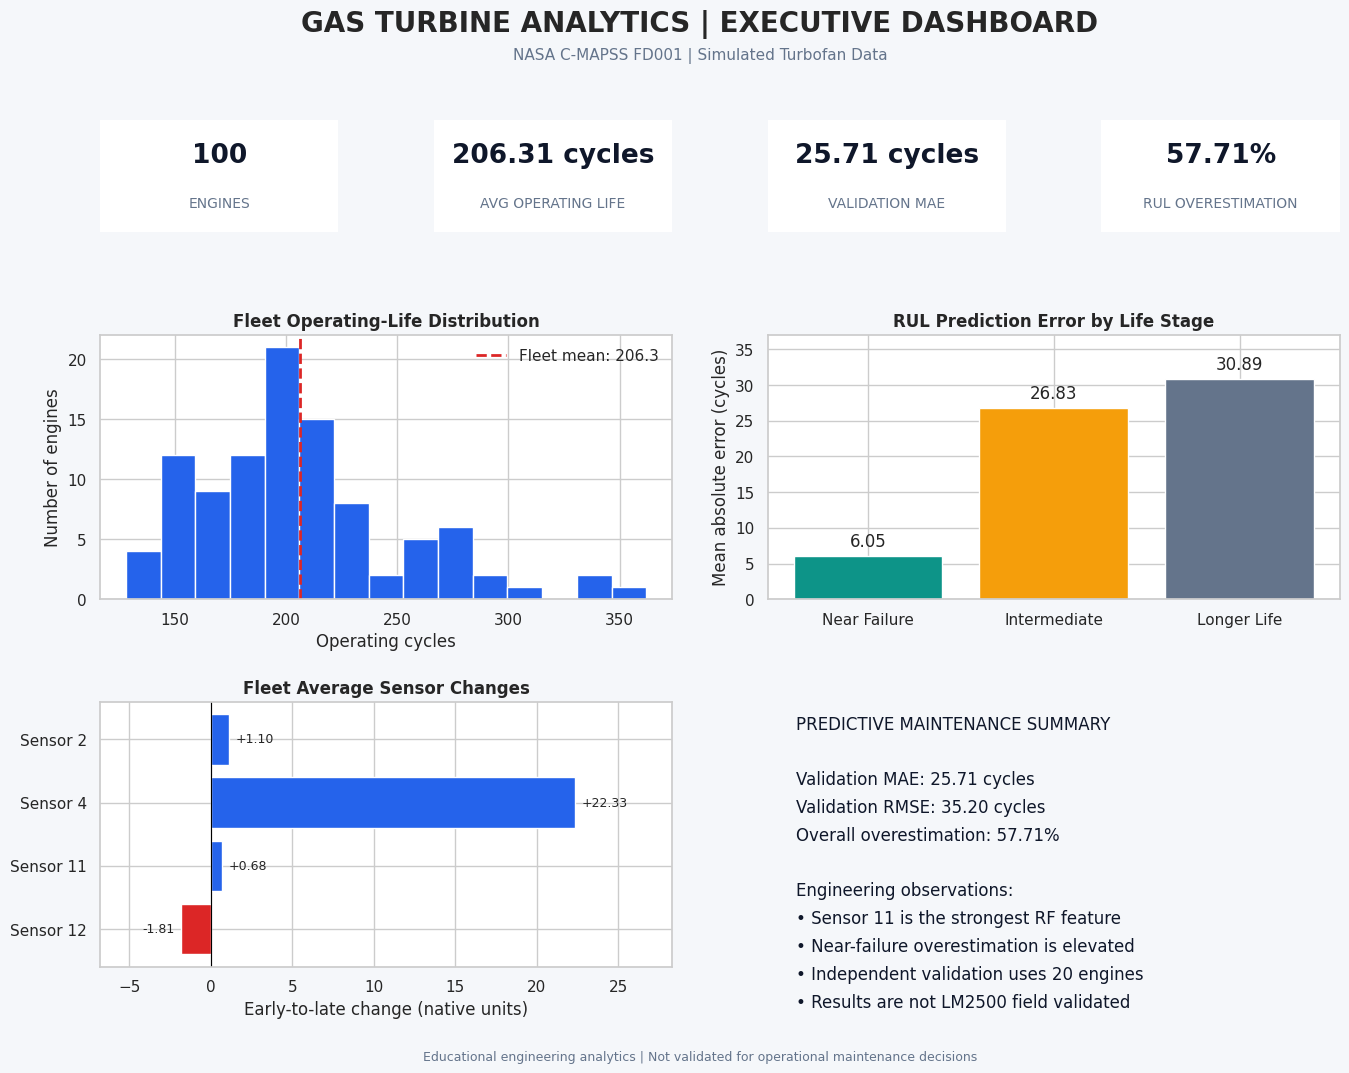

STEP 8 CELL 1 COMPLETE
----------------------
Dashboard saved:
/content/LM2500_Project/Visualizations/executive_fleet_dashboard.png
Resolution: 300 DPI
Data validation: PASSED


In [49]:

# STEP 8 - CELL 1
# Executive Fleet Performance Dashboard

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

project_folder = Path("/content/LM2500_Project")
visual_folder = project_folder / "Visualizations"
visual_folder.mkdir(parents=True, exist_ok=True)

# Load validated SQL outputs
fleet = pd.read_csv(
    project_folder / "sql_fleet_life_statistics.csv"
)

model = pd.read_csv(
    project_folder / "sql_overall_rul_errors.csv"
)

degradation = pd.read_csv(
    project_folder / "sql_fleet_degradation_summary.csv"
)

operations = pd.read_csv(
    project_folder / "sql_sensor_degradation.csv"
)

categories = pd.read_csv(
    project_folder / "sql_rul_error_categories.csv"
)

# Read key performance metrics
engine_count = int(fleet.loc[0, "Total_Engines"])
avg_life = float(
    fleet.loc[0, "Average_Operating_Cycles"]
)
mae = float(model.loc[0, "MAE"])
rmse = float(model.loc[0, "RMSE"])
overestimate = float(
    model.loc[0, "Overestimation_Rate"]
)

# Validate source data
assert engine_count == 100
assert len(operations) == 100
assert abs(mae - 25.7124) < 0.01
assert categories["Observations"].sum() == 4070

# Dashboard layout
fig = plt.figure(figsize=(16, 11))
fig.patch.set_facecolor("#F5F7FA")

gs = fig.add_gridspec(
    3, 4,
    height_ratios=[0.85, 2, 2],
    hspace=0.48,
    wspace=0.40
)

fig.suptitle(
    "GAS TURBINE ANALYTICS | EXECUTIVE DASHBOARD",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5, 0.935,
    "NASA C-MAPSS FD001 | Simulated Turbofan Data",
    ha="center",
    fontsize=11,
    color="#64748B"
)

# ---------------------------------------
# 1. KPI cards
# ---------------------------------------

kpis = [
    ("ENGINES", f"{engine_count:,}"),
    ("AVG OPERATING LIFE", f"{avg_life:.2f} cycles"),
    ("VALIDATION MAE", f"{mae:.2f} cycles"),
    ("RUL OVERESTIMATION", f"{overestimate:.2f}%")
]

for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i])
    ax.set_facecolor("white")

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.set_xticks([])
    ax.set_yticks([])

    ax.text(
        0.5, 0.68, value,
        ha="center", va="center",
        fontsize=19,
        fontweight="bold",
        color="#0F172A",
        transform=ax.transAxes
    )

    ax.text(
        0.5, 0.25, label,
        ha="center", va="center",
        fontsize=10,
        color="#64748B",
        transform=ax.transAxes
    )

# ---------------------------------------
# 2. Fleet operating-life distribution
# ---------------------------------------

ax1 = fig.add_subplot(gs[1, :2])
ax1.set_facecolor("white")

ax1.hist(
    operations["operating_cycles"],
    bins=15,
    color="#2563EB",
    edgecolor="white"
)

ax1.axvline(
    avg_life,
    color="#DC2626",
    linestyle="--",
    linewidth=2,
    label=f"Fleet mean: {avg_life:.1f}"
)

ax1.set_title(
    "Fleet Operating-Life Distribution",
    fontweight="bold"
)
ax1.set_xlabel("Operating cycles")
ax1.set_ylabel("Number of engines")
ax1.legend(frameon=False)

# ---------------------------------------
# 3. Model error by RUL category
# ---------------------------------------

ax2 = fig.add_subplot(gs[1, 2:])
ax2.set_facecolor("white")

labels = [
    "Near Failure",
    "Intermediate",
    "Longer Life"
]

error_values = [
    float(categories.loc[
        categories["RUL_Category"]
        == "Near Failure (0-30)", "MAE"
    ].iloc[0]),
    float(categories.loc[
        categories["RUL_Category"]
        == "Intermediate (31-100)", "MAE"
    ].iloc[0]),
    float(categories.loc[
        categories["RUL_Category"]
        == "Longer Life (101+)", "MAE"
    ].iloc[0])
]

bars = ax2.bar(
    labels,
    error_values,
    color=["#0D9488", "#F59E0B", "#64748B"]
)

ax2.bar_label(bars, fmt="%.2f", padding=4)
ax2.set_ylim(0, max(error_values) * 1.2)
ax2.set_ylabel("Mean absolute error (cycles)")
ax2.set_title(
    "RUL Prediction Error by Life Stage",
    fontweight="bold"
)

# ---------------------------------------
# 4. Sensor degradation indicators
# ---------------------------------------

ax3 = fig.add_subplot(gs[2, :2])
ax3.set_facecolor("white")

sensor_labels = [
    "Sensor 2",
    "Sensor 4",
    "Sensor 11",
    "Sensor 12"
]

sensor_changes = [
    float(degradation.loc[
        0, "Avg_Sensor_2_Change"
    ]),
    float(degradation.loc[
        0, "Avg_Sensor_4_Change"
    ]),
    float(degradation.loc[
        0, "Avg_Sensor_11_Change"
    ]),
    float(degradation.loc[
        0, "Avg_Sensor_12_Change"
    ])
]

colors = [
    "#2563EB" if v >= 0 else "#DC2626"
    for v in sensor_changes
]

bars = ax3.barh(
    sensor_labels,
    sensor_changes,
    color=colors
)

ax3.axvline(0, color="black", linewidth=0.8)
ax3.invert_yaxis()
ax3.set_title(
    "Fleet Average Sensor Changes",
    fontweight="bold"
)
ax3.set_xlabel("Early-to-late change (native units)")

for bar, value in zip(bars, sensor_changes):
    ax3.annotate(
        f"{value:+.2f}",
        xy=(value, bar.get_y() + bar.get_height()/2),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=9
    )

ax3.set_xlim(
    min(sensor_changes) - 5,
    max(sensor_changes) + 6
)

# ---------------------------------------
# 5. Model performance summary
# ---------------------------------------

ax4 = fig.add_subplot(gs[2, 2:])
ax4.set_facecolor("white")
ax4.axis("off")

summary_text = (
    "PREDICTIVE MAINTENANCE SUMMARY\n\n"
    f"Validation MAE: {mae:.2f} cycles\n"
    f"Validation RMSE: {rmse:.2f} cycles\n"
    f"Overall overestimation: {overestimate:.2f}%\n\n"
    "Engineering observations:\n"
    "• Sensor 11 is the strongest RF feature\n"
    "• Near-failure overestimation is elevated\n"
    "• Independent validation uses 20 engines\n"
    "• Results are not LM2500 field validated"
)

ax4.text(
    0.05, 0.95,
    summary_text,
    transform=ax4.transAxes,
    va="top",
    fontsize=12,
    linespacing=1.7,
    color="#0F172A"
)

# Footer
fig.text(
    0.5, 0.025,
    "Educational engineering analytics | "
    "Not validated for operational maintenance decisions",
    ha="center",
    fontsize=9,
    color="#64748B"
)

# Save dashboard
dashboard_path = (
    visual_folder / "executive_fleet_dashboard.png"
)

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()
plt.close(fig)

print("STEP 8 CELL 1 COMPLETE")
print("----------------------")
print("Dashboard saved:")
print(dashboard_path)
print("Resolution: 300 DPI")
print("Data validation: PASSED")


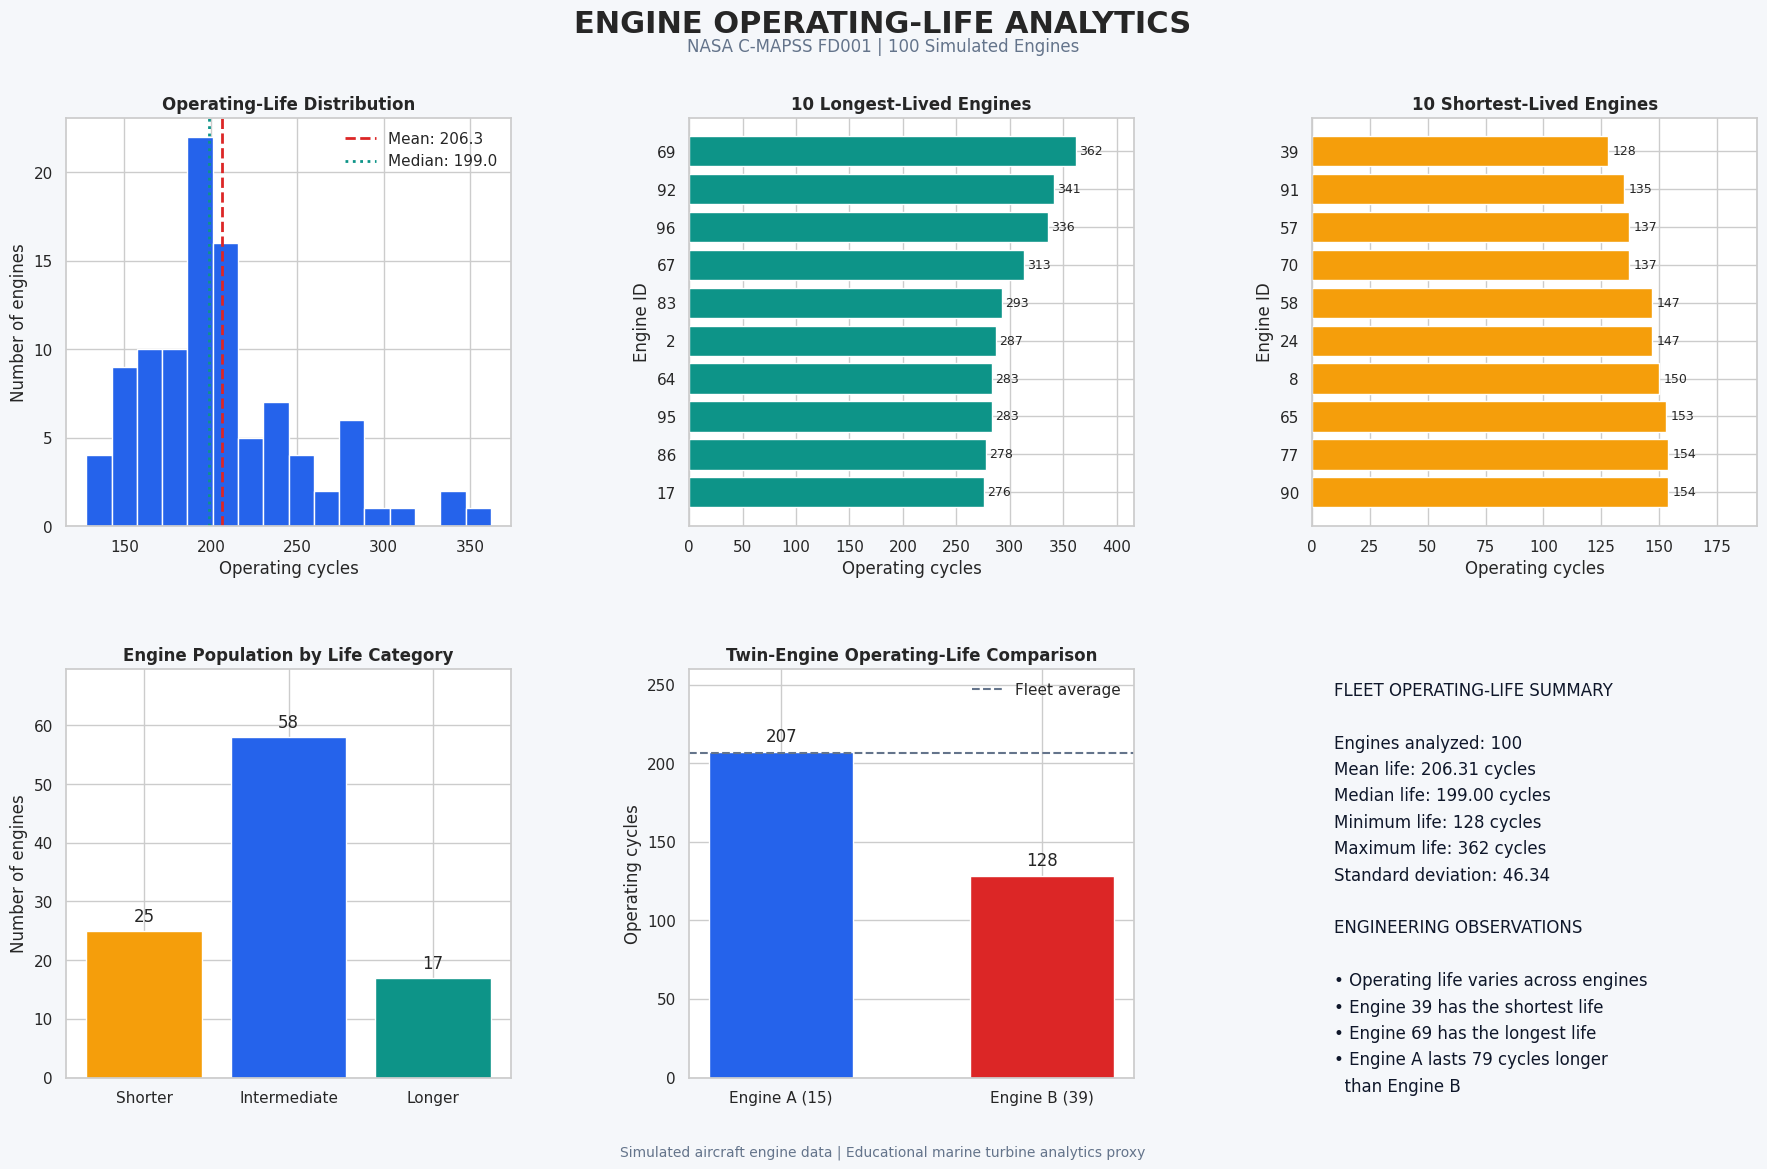

STEP 8 CELL 2 COMPLETE
----------------------
Dashboard saved:
/content/LM2500_Project/Visualizations/engine_operating_life_dashboard.png
Resolution: 300 DPI
Summary CSV saved.
Data validation: PASSED


,Metric,Value
0,Total Engines,100.000000
1,Average Operating Cycles,206.310000
2,Median Operating Cycles,199.000000
3,Minimum Operating Cycles,128.000000
4,Maximum Operating Cycles,362.000000
5,Standard Deviation,46.342749
6,Engine A Operating Cycles,207.000000
7,Engine B Operating Cycles,128.000000


In [50]:

# STEP 8 - CELL 2
# Engine Operating-Life Dashboard

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

project_folder = Path("/content/LM2500_Project")
visual_folder = project_folder / "Visualizations"
visual_folder.mkdir(parents=True, exist_ok=True)

# ---------------------------------------
# 1. Load validated SQL results
# ---------------------------------------

fleet = pd.read_csv(
    project_folder / "sql_fleet_life_statistics.csv"
)

operations = pd.read_csv(
    project_folder / "sql_sensor_degradation.csv"
)

categories = pd.read_csv(
    project_folder / "sql_operating_life_categories.csv"
)

# Sort by operating life
operations = operations.sort_values(
    "operating_cycles"
).reset_index(drop=True)

assert len(operations) == 100
assert operations["engine_id"].nunique() == 100

avg_life = float(
    fleet.loc[0, "Average_Operating_Cycles"]
)

min_life = int(
    fleet.loc[0, "Minimum_Operating_Cycles"]
)

max_life = int(
    fleet.loc[0, "Maximum_Operating_Cycles"]
)

median_life = operations[
    "operating_cycles"
].median()

std_life = operations[
    "operating_cycles"
].std()

# ---------------------------------------
# 2. Create dashboard layout
# ---------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(19, 12)
)

fig.patch.set_facecolor("#F5F7FA")

fig.suptitle(
    "ENGINE OPERATING-LIFE ANALYTICS",
    fontsize=22,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5, 0.945,
    "NASA C-MAPSS FD001 | 100 Simulated Engines",
    ha="center",
    fontsize=12,
    color="#64748B"
)

for ax in axes.flat:
    ax.set_facecolor("white")

# ---------------------------------------
# 3. Fleet operating-life distribution
# ---------------------------------------

ax = axes[0, 0]

ax.hist(
    operations["operating_cycles"],
    bins=16,
    color="#2563EB",
    edgecolor="white"
)

ax.axvline(
    avg_life,
    color="#DC2626",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {avg_life:.1f}"
)

ax.axvline(
    median_life,
    color="#0D9488",
    linestyle=":",
    linewidth=2,
    label=f"Median: {median_life:.1f}"
)

ax.set_title(
    "Operating-Life Distribution",
    fontweight="bold"
)
ax.set_xlabel("Operating cycles")
ax.set_ylabel("Number of engines")
ax.legend(frameon=False)

# ---------------------------------------
# 4. Ten longest-lived engines
# ---------------------------------------

ax = axes[0, 1]

longest = operations.nlargest(
    10, "operating_cycles"
).sort_values("operating_cycles")

ax.barh(
    longest["engine_id"].astype(str),
    longest["operating_cycles"],
    color="#0D9488"
)

ax.set_title(
    "10 Longest-Lived Engines",
    fontweight="bold"
)
ax.set_xlabel("Operating cycles")
ax.set_ylabel("Engine ID")

for i, value in enumerate(
    longest["operating_cycles"]
):
    ax.text(
        value + 3,
        i,
        str(int(value)),
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    longest["operating_cycles"].max() * 1.15
)

# ---------------------------------------
# 5. Ten shortest-lived engines
# ---------------------------------------

ax = axes[0, 2]

shortest = operations.nsmallest(
    10, "operating_cycles"
).sort_values(
    "operating_cycles",
    ascending=False
)

ax.barh(
    shortest["engine_id"].astype(str),
    shortest["operating_cycles"],
    color="#F59E0B"
)

ax.set_title(
    "10 Shortest-Lived Engines",
    fontweight="bold"
)
ax.set_xlabel("Operating cycles")
ax.set_ylabel("Engine ID")

for i, value in enumerate(
    shortest["operating_cycles"]
):
    ax.text(
        value + 2,
        i,
        str(int(value)),
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    shortest["operating_cycles"].max() * 1.25
)

# ---------------------------------------
# 6. Operating-life categories
# ---------------------------------------

ax = axes[1, 0]

category_order = [
    "Shorter Life",
    "Intermediate Life",
    "Longer Life"
]

category_data = categories.set_index(
    "life_category"
).loc[category_order]

bars = ax.bar(
    ["Shorter", "Intermediate", "Longer"],
    category_data["Engines"],
    color=["#F59E0B", "#2563EB", "#0D9488"]
)

ax.bar_label(
    bars,
    labels=[
        str(int(v))
        for v in category_data["Engines"]
    ],
    padding=4
)

ax.set_title(
    "Engine Population by Life Category",
    fontweight="bold"
)
ax.set_ylabel("Number of engines")
ax.set_ylim(
    0,
    category_data["Engines"].max() * 1.2
)

# ---------------------------------------
# 7. Engine A versus Engine B
# ---------------------------------------

ax = axes[1, 1]

engine_a_life = int(
    operations.loc[
        operations["engine_id"] == 15,
        "operating_cycles"
    ].iloc[0]
)

engine_b_life = int(
    operations.loc[
        operations["engine_id"] == 39,
        "operating_cycles"
    ].iloc[0]
)

bars = ax.bar(
    ["Engine A (15)", "Engine B (39)"],
    [engine_a_life, engine_b_life],
    color=["#2563EB", "#DC2626"],
    width=0.55
)

ax.bar_label(
    bars,
    labels=[
        str(engine_a_life),
        str(engine_b_life)
    ],
    padding=5
)

ax.axhline(
    avg_life,
    linestyle="--",
    color="#64748B",
    label="Fleet average"
)

ax.set_ylim(0, 260)
ax.set_ylabel("Operating cycles")
ax.set_title(
    "Twin-Engine Operating-Life Comparison",
    fontweight="bold"
)
ax.legend(frameon=False)

# ---------------------------------------
# 8. Fleet statistics and observations
# ---------------------------------------

ax = axes[1, 2]
ax.axis("off")

stats_text = (
    "FLEET OPERATING-LIFE SUMMARY\n\n"
    f"Engines analyzed: 100\n"
    f"Mean life: {avg_life:.2f} cycles\n"
    f"Median life: {median_life:.2f} cycles\n"
    f"Minimum life: {min_life} cycles\n"
    f"Maximum life: {max_life} cycles\n"
    f"Standard deviation: {std_life:.2f}\n\n"
    "ENGINEERING OBSERVATIONS\n\n"
    "• Operating life varies across engines\n"
    "• Engine 39 has the shortest life\n"
    "• Engine 69 has the longest life\n"
    "• Engine A lasts 79 cycles longer\n"
    "  than Engine B"
)

ax.text(
    0.05,
    0.97,
    stats_text,
    transform=ax.transAxes,
    va="top",
    fontsize=12,
    linespacing=1.6,
    color="#0F172A"
)

# ---------------------------------------
# 9. Final formatting and export
# ---------------------------------------

fig.text(
    0.5,
    0.025,
    "Simulated aircraft engine data | "
    "Educational marine turbine analytics proxy",
    ha="center",
    fontsize=10,
    color="#64748B"
)

fig.subplots_adjust(
    left=0.07,
    right=0.96,
    top=0.89,
    bottom=0.09,
    hspace=0.35,
    wspace=0.40
)

dashboard_path = (
    visual_folder / "engine_operating_life_dashboard.png"
)

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()
plt.close(fig)

# ---------------------------------------
# 10. Export supporting summary
# ---------------------------------------

life_summary = pd.DataFrame({
    "Metric": [
        "Total Engines",
        "Average Operating Cycles",
        "Median Operating Cycles",
        "Minimum Operating Cycles",
        "Maximum Operating Cycles",
        "Standard Deviation",
        "Engine A Operating Cycles",
        "Engine B Operating Cycles"
    ],
    "Value": [
        100,
        avg_life,
        median_life,
        min_life,
        max_life,
        std_life,
        engine_a_life,
        engine_b_life
    ]
})

life_summary.to_csv(
    project_folder /
    "engine_operating_life_dashboard_summary.csv",
    index=False
)

print("STEP 8 CELL 2 COMPLETE")
print("----------------------")
print("Dashboard saved:")
print(dashboard_path)
print("Resolution: 300 DPI")
print("Summary CSV saved.")
print("Data validation: PASSED")

display(life_summary)


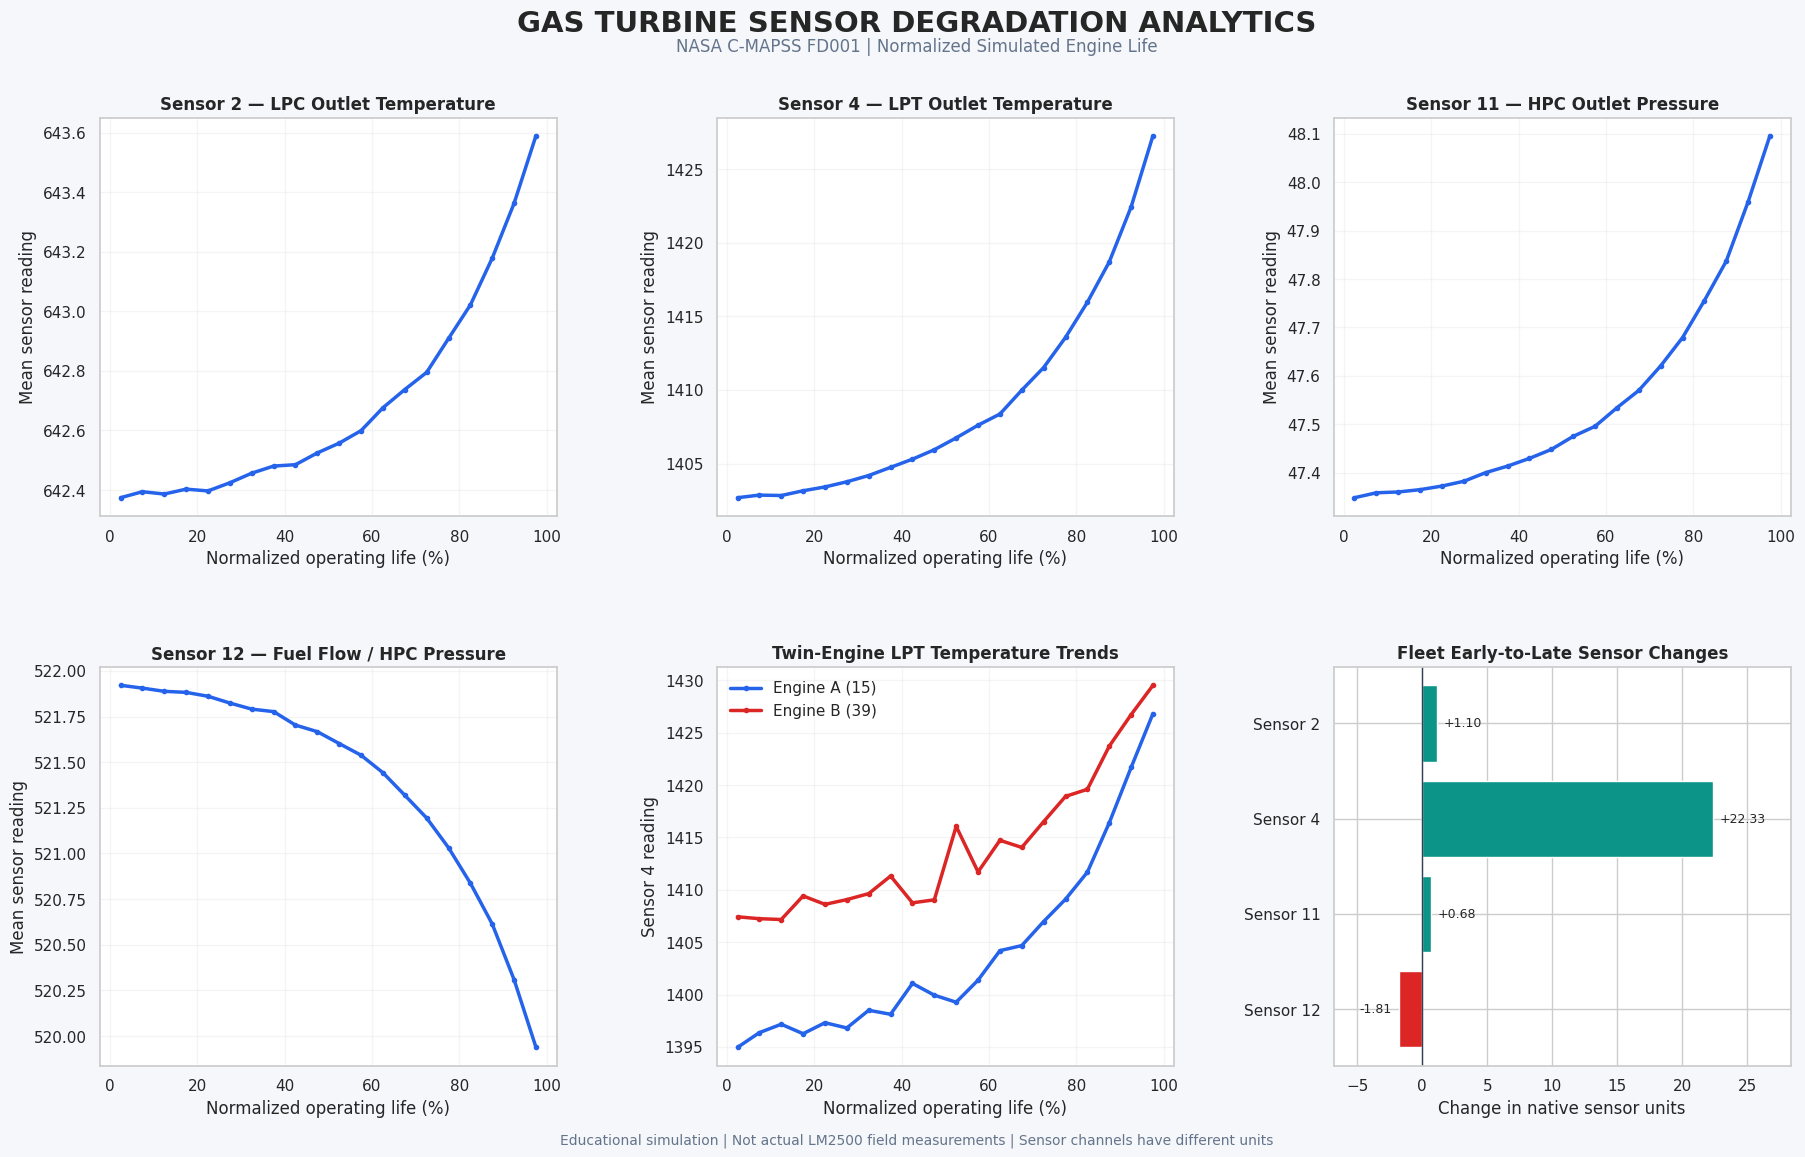

STEP 8 CELL 3 COMPLETE
----------------------
Dashboard saved:
/content/LM2500_Project/Visualizations/sensor_degradation_dashboard.png
Resolution: 300 DPI
Fleet normalized trends CSV saved.
Twin-engine normalized trends CSV saved.
Data validation: PASSED

FLEET EARLY-TO-LATE SENSOR CHANGES
Sensor 2: +1.1021
Sensor 4: +22.3255
Sensor 11: +0.6811
Sensor 12: -1.8089

NORMALIZED FLEET TREND SAMPLE


,life_bin,sensor_2,sensor_4,sensor_11,sensor_12,life_percent
0,0,642.374439,1402.677123,47.348636,521.920917,2.5
1,1,642.394579,1402.854714,47.358789,521.905408,7.5
2,2,642.386749,1402.826856,47.360508,521.887831,12.5
3,3,642.403214,1403.149019,47.365288,521.882074,17.5
4,4,642.397216,1403.408525,47.372691,521.860814,22.5


In [51]:

# STEP 8 - CELL 3
# Sensor Degradation Dashboard
# NASA C-MAPSS FD001 simulated turbofan data

import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project_folder = Path("/content/LM2500_Project")
visual_folder = project_folder / "Visualizations"
visual_folder.mkdir(parents=True, exist_ok=True)

db_path = project_folder / "lm2500_engine_analytics.db"

# ---------------------------------------
# 1. Load SQL sensor observations
# ---------------------------------------

conn = sqlite3.connect(db_path)

sensor_df = pd.read_sql_query("""
SELECT
    engine_id,
    cycle,
    sensor_2,
    sensor_4,
    sensor_11,
    sensor_12
FROM engine_operations
ORDER BY engine_id, cycle
""", conn)

conn.close()

degradation = pd.read_csv(
    project_folder / "sql_sensor_degradation.csv"
)

fleet_summary = pd.read_csv(
    project_folder / "sql_fleet_degradation_summary.csv"
)

assert len(sensor_df) == 20631
assert sensor_df["engine_id"].nunique() == 100
assert len(degradation) == 100

# ---------------------------------------
# 2. Normalize operating life
# ---------------------------------------

sensor_df["max_cycle"] = (
    sensor_df.groupby("engine_id")["cycle"]
    .transform("max")
)

sensor_df["life_percent"] = (
    100 * sensor_df["cycle"] /
    sensor_df["max_cycle"]
)

# Divide each engine's life into 20 bins.
# Average within engines first, then across
# engines to avoid favoring longer histories.

sensor_df["life_bin"] = np.minimum(
    ((sensor_df["life_percent"] - 1e-9) // 5)
    .astype(int),
    19
)

sensor_cols = [
    "sensor_2", "sensor_4",
    "sensor_11", "sensor_12"
]

engine_bins = (
    sensor_df.groupby(
        ["engine_id", "life_bin"]
    )[sensor_cols]
    .mean()
    .reset_index()
)

fleet_trends = (
    engine_bins.groupby("life_bin")[sensor_cols]
    .mean()
    .reset_index()
)

fleet_trends["life_percent"] = (
    fleet_trends["life_bin"] * 5 + 2.5
)

# ---------------------------------------
# 3. Prepare twin-engine trends
# ---------------------------------------

twin_df = sensor_df[
    sensor_df["engine_id"].isin([15, 39])
].copy()

twin_bins = (
    twin_df.groupby(
        ["engine_id", "life_bin"]
    )[sensor_cols]
    .mean()
    .reset_index()
)

twin_bins["life_percent"] = (
    twin_bins["life_bin"] * 5 + 2.5
)

# ---------------------------------------
# 4. Create dashboard
# ---------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(19, 12)
)

fig.patch.set_facecolor("#F5F7FA")

fig.suptitle(
    "GAS TURBINE SENSOR DEGRADATION ANALYTICS",
    fontsize=21,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5, 0.945,
    "NASA C-MAPSS FD001 | "
    "Normalized Simulated Engine Life",
    ha="center",
    fontsize=12,
    color="#64748B"
)

sensor_info = [
    ("sensor_2", "Sensor 2 — LPC Outlet Temperature"),
    ("sensor_4", "Sensor 4 — LPT Outlet Temperature"),
    ("sensor_11", "Sensor 11 — HPC Outlet Pressure"),
    ("sensor_12", "Sensor 12 — Fuel Flow / HPC Pressure")
]

# Four fleet sensor trends
for ax, (col, title) in zip(
    axes.flat[:4], sensor_info
):
    ax.set_facecolor("white")

    ax.plot(
        fleet_trends["life_percent"],
        fleet_trends[col],
        color="#2563EB",
        linewidth=2.5,
        marker="o",
        markersize=3
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Normalized operating life (%)")
    ax.set_ylabel("Mean sensor reading")
    ax.grid(alpha=0.2)

# ---------------------------------------
# 5. Twin-engine Sensor 4 comparison
# ---------------------------------------

ax = axes[1, 1]
ax.set_facecolor("white")

for engine_id, label, color in [
    (15, "Engine A (15)", "#2563EB"),
    (39, "Engine B (39)", "#DC2626")
]:
    data = twin_bins[
        twin_bins["engine_id"] == engine_id
    ]

    ax.plot(
        data["life_percent"],
        data["sensor_4"],
        linewidth=2.5,
        marker="o",
        markersize=3,
        label=label,
        color=color
    )

ax.set_title(
    "Twin-Engine LPT Temperature Trends",
    fontweight="bold"
)
ax.set_xlabel("Normalized operating life (%)")
ax.set_ylabel("Sensor 4 reading")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

# ---------------------------------------
# 6. Fleet average sensor changes
# ---------------------------------------

ax = axes[1, 2]
ax.set_facecolor("white")

labels = [
    "Sensor 2",
    "Sensor 4",
    "Sensor 11",
    "Sensor 12"
]

changes = [
    float(fleet_summary.loc[
        0, "Avg_Sensor_2_Change"
    ]),
    float(fleet_summary.loc[
        0, "Avg_Sensor_4_Change"
    ]),
    float(fleet_summary.loc[
        0, "Avg_Sensor_11_Change"
    ]),
    float(fleet_summary.loc[
        0, "Avg_Sensor_12_Change"
    ])
]

colors = [
    "#0D9488" if v >= 0 else "#DC2626"
    for v in changes
]

bars = ax.barh(
    labels,
    changes,
    color=colors
)

ax.axvline(0, color="#334155", linewidth=1)
ax.invert_yaxis()

ax.set_title(
    "Fleet Early-to-Late Sensor Changes",
    fontweight="bold"
)
ax.set_xlabel("Change in native sensor units")

for bar, value in zip(bars, changes):
    ax.annotate(
        f"{value:+.2f}",
        xy=(
            value,
            bar.get_y() + bar.get_height()/2
        ),
        xytext=(
            5 if value >= 0 else -5, 0
        ),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    min(changes) - 5,
    max(changes) + 6
)

# ---------------------------------------
# 7. Format and save
# ---------------------------------------

fig.subplots_adjust(
    left=0.07,
    right=0.96,
    top=0.89,
    bottom=0.10,
    hspace=0.38,
    wspace=0.35
)

fig.text(
    0.5, 0.035,
    "Educational simulation | "
    "Not actual LM2500 field measurements | "
    "Sensor channels have different units",
    ha="center",
    fontsize=10,
    color="#64748B"
)

dashboard_path = (
    visual_folder /
    "sensor_degradation_dashboard.png"
)

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()
plt.close(fig)

# ---------------------------------------
# 8. Export supporting data
# ---------------------------------------

fleet_trends.to_csv(
    project_folder /
    "sensor_fleet_normalized_trends.csv",
    index=False
)

twin_bins.to_csv(
    project_folder /
    "sensor_twin_normalized_trends.csv",
    index=False
)

print("STEP 8 CELL 3 COMPLETE")
print("----------------------")
print("Dashboard saved:")
print(dashboard_path)
print("Resolution: 300 DPI")
print("Fleet normalized trends CSV saved.")
print("Twin-engine normalized trends CSV saved.")
print("Data validation: PASSED")

print("\nFLEET EARLY-TO-LATE SENSOR CHANGES")
for label, value in zip(labels, changes):
    print(f"{label}: {value:+.4f}")

print("\nNORMALIZED FLEET TREND SAMPLE")
display(fleet_trends.head())


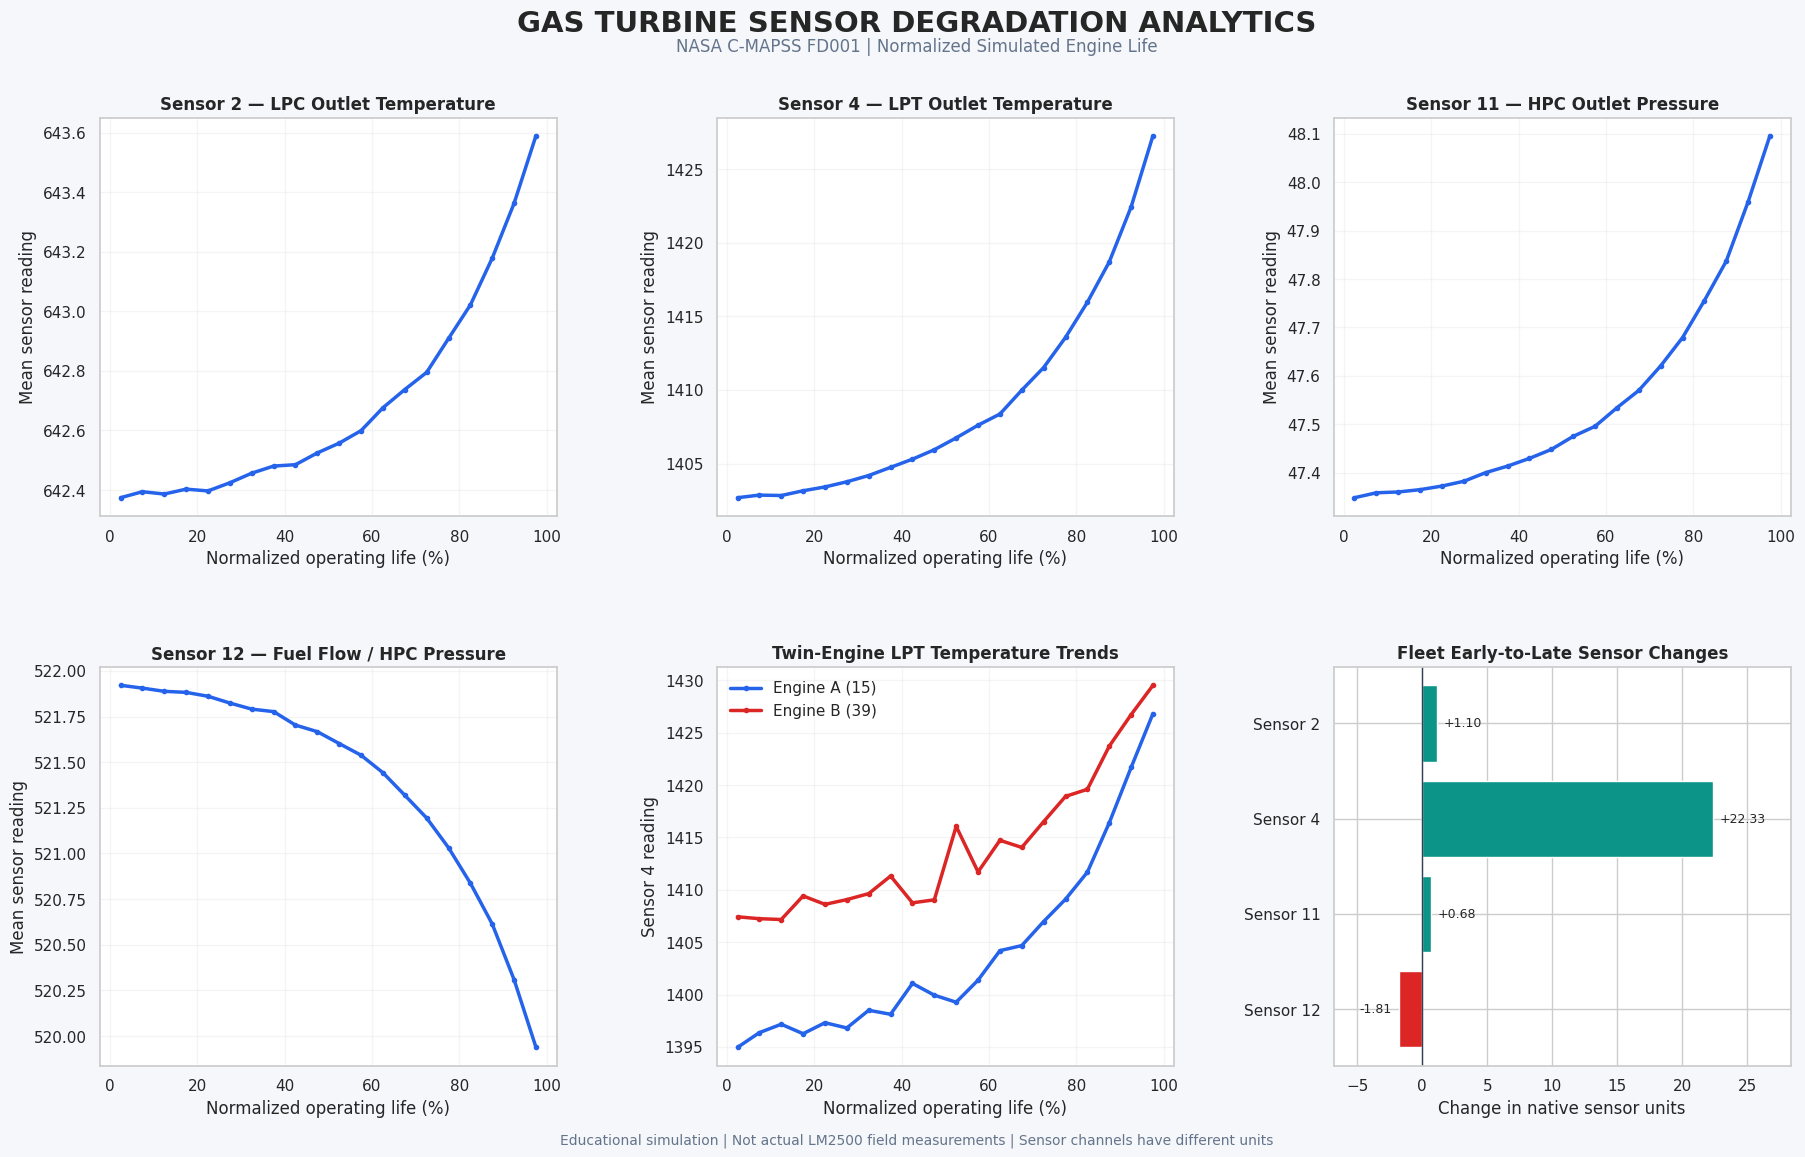

STEP 8 CELL 3 COMPLETE
----------------------
Dashboard saved:
/content/LM2500_Project/Visualizations/sensor_degradation_dashboard.png
Resolution: 300 DPI
Fleet normalized trends CSV saved.
Twin-engine normalized trends CSV saved.
Data validation: PASSED

FLEET EARLY-TO-LATE SENSOR CHANGES
Sensor 2: +1.1021
Sensor 4: +22.3255
Sensor 11: +0.6811
Sensor 12: -1.8089

NORMALIZED FLEET TREND SAMPLE


,life_bin,sensor_2,sensor_4,sensor_11,sensor_12,life_percent
0,0,642.374439,1402.677123,47.348636,521.920917,2.5
1,1,642.394579,1402.854714,47.358789,521.905408,7.5
2,2,642.386749,1402.826856,47.360508,521.887831,12.5
3,3,642.403214,1403.149019,47.365288,521.882074,17.5
4,4,642.397216,1403.408525,47.372691,521.860814,22.5


In [52]:

# STEP 8 - CELL 3
# Sensor Degradation Dashboard
# NASA C-MAPSS FD001 simulated turbofan data

import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project_folder = Path("/content/LM2500_Project")
visual_folder = project_folder / "Visualizations"
visual_folder.mkdir(parents=True, exist_ok=True)

db_path = project_folder / "lm2500_engine_analytics.db"

# ---------------------------------------
# 1. Load SQL sensor observations
# ---------------------------------------

conn = sqlite3.connect(db_path)

sensor_df = pd.read_sql_query("""
SELECT
    engine_id,
    cycle,
    sensor_2,
    sensor_4,
    sensor_11,
    sensor_12
FROM engine_operations
ORDER BY engine_id, cycle
""", conn)

conn.close()

degradation = pd.read_csv(
    project_folder / "sql_sensor_degradation.csv"
)

fleet_summary = pd.read_csv(
    project_folder / "sql_fleet_degradation_summary.csv"
)

assert len(sensor_df) == 20631
assert sensor_df["engine_id"].nunique() == 100
assert len(degradation) == 100

# ---------------------------------------
# 2. Normalize operating life
# ---------------------------------------

sensor_df["max_cycle"] = (
    sensor_df.groupby("engine_id")["cycle"]
    .transform("max")
)

sensor_df["life_percent"] = (
    100 * sensor_df["cycle"] /
    sensor_df["max_cycle"]
)

# Divide each engine's life into 20 bins.
# Average within engines first, then across
# engines to avoid favoring longer histories.

sensor_df["life_bin"] = np.minimum(
    ((sensor_df["life_percent"] - 1e-9) // 5)
    .astype(int),
    19
)

sensor_cols = [
    "sensor_2", "sensor_4",
    "sensor_11", "sensor_12"
]

engine_bins = (
    sensor_df.groupby(
        ["engine_id", "life_bin"]
    )[sensor_cols]
    .mean()
    .reset_index()
)

fleet_trends = (
    engine_bins.groupby("life_bin")[sensor_cols]
    .mean()
    .reset_index()
)

fleet_trends["life_percent"] = (
    fleet_trends["life_bin"] * 5 + 2.5
)

# ---------------------------------------
# 3. Prepare twin-engine trends
# ---------------------------------------

twin_df = sensor_df[
    sensor_df["engine_id"].isin([15, 39])
].copy()

twin_bins = (
    twin_df.groupby(
        ["engine_id", "life_bin"]
    )[sensor_cols]
    .mean()
    .reset_index()
)

twin_bins["life_percent"] = (
    twin_bins["life_bin"] * 5 + 2.5
)

# ---------------------------------------
# 4. Create dashboard
# ---------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(19, 12)
)

fig.patch.set_facecolor("#F5F7FA")

fig.suptitle(
    "GAS TURBINE SENSOR DEGRADATION ANALYTICS",
    fontsize=21,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5, 0.945,
    "NASA C-MAPSS FD001 | "
    "Normalized Simulated Engine Life",
    ha="center",
    fontsize=12,
    color="#64748B"
)

sensor_info = [
    ("sensor_2", "Sensor 2 — LPC Outlet Temperature"),
    ("sensor_4", "Sensor 4 — LPT Outlet Temperature"),
    ("sensor_11", "Sensor 11 — HPC Outlet Pressure"),
    ("sensor_12", "Sensor 12 — Fuel Flow / HPC Pressure")
]

# Four fleet sensor trends
for ax, (col, title) in zip(
    axes.flat[:4], sensor_info
):
    ax.set_facecolor("white")

    ax.plot(
        fleet_trends["life_percent"],
        fleet_trends[col],
        color="#2563EB",
        linewidth=2.5,
        marker="o",
        markersize=3
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Normalized operating life (%)")
    ax.set_ylabel("Mean sensor reading")
    ax.grid(alpha=0.2)

# ---------------------------------------
# 5. Twin-engine Sensor 4 comparison
# ---------------------------------------

ax = axes[1, 1]
ax.set_facecolor("white")

for engine_id, label, color in [
    (15, "Engine A (15)", "#2563EB"),
    (39, "Engine B (39)", "#DC2626")
]:
    data = twin_bins[
        twin_bins["engine_id"] == engine_id
    ]

    ax.plot(
        data["life_percent"],
        data["sensor_4"],
        linewidth=2.5,
        marker="o",
        markersize=3,
        label=label,
        color=color
    )

ax.set_title(
    "Twin-Engine LPT Temperature Trends",
    fontweight="bold"
)
ax.set_xlabel("Normalized operating life (%)")
ax.set_ylabel("Sensor 4 reading")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

# ---------------------------------------
# 6. Fleet average sensor changes
# ---------------------------------------

ax = axes[1, 2]
ax.set_facecolor("white")

labels = [
    "Sensor 2",
    "Sensor 4",
    "Sensor 11",
    "Sensor 12"
]

changes = [
    float(fleet_summary.loc[
        0, "Avg_Sensor_2_Change"
    ]),
    float(fleet_summary.loc[
        0, "Avg_Sensor_4_Change"
    ]),
    float(fleet_summary.loc[
        0, "Avg_Sensor_11_Change"
    ]),
    float(fleet_summary.loc[
        0, "Avg_Sensor_12_Change"
    ])
]

colors = [
    "#0D9488" if v >= 0 else "#DC2626"
    for v in changes
]

bars = ax.barh(
    labels,
    changes,
    color=colors
)

ax.axvline(0, color="#334155", linewidth=1)
ax.invert_yaxis()

ax.set_title(
    "Fleet Early-to-Late Sensor Changes",
    fontweight="bold"
)
ax.set_xlabel("Change in native sensor units")

for bar, value in zip(bars, changes):
    ax.annotate(
        f"{value:+.2f}",
        xy=(
            value,
            bar.get_y() + bar.get_height()/2
        ),
        xytext=(
            5 if value >= 0 else -5, 0
        ),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    min(changes) - 5,
    max(changes) + 6
)

# ---------------------------------------
# 7. Format and save
# ---------------------------------------

fig.subplots_adjust(
    left=0.07,
    right=0.96,
    top=0.89,
    bottom=0.10,
    hspace=0.38,
    wspace=0.35
)

fig.text(
    0.5, 0.035,
    "Educational simulation | "
    "Not actual LM2500 field measurements | "
    "Sensor channels have different units",
    ha="center",
    fontsize=10,
    color="#64748B"
)

dashboard_path = (
    visual_folder /
    "sensor_degradation_dashboard.png"
)

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()
plt.close(fig)

# ---------------------------------------
# 8. Export supporting data
# ---------------------------------------

fleet_trends.to_csv(
    project_folder /
    "sensor_fleet_normalized_trends.csv",
    index=False
)

twin_bins.to_csv(
    project_folder /
    "sensor_twin_normalized_trends.csv",
    index=False
)

print("STEP 8 CELL 3 COMPLETE")
print("----------------------")
print("Dashboard saved:")
print(dashboard_path)
print("Resolution: 300 DPI")
print("Fleet normalized trends CSV saved.")
print("Twin-engine normalized trends CSV saved.")
print("Data validation: PASSED")

print("\nFLEET EARLY-TO-LATE SENSOR CHANGES")
for label, value in zip(labels, changes):
    print(f"{label}: {value:+.4f}")

print("\nNORMALIZED FLEET TREND SAMPLE")
display(fleet_trends.head())


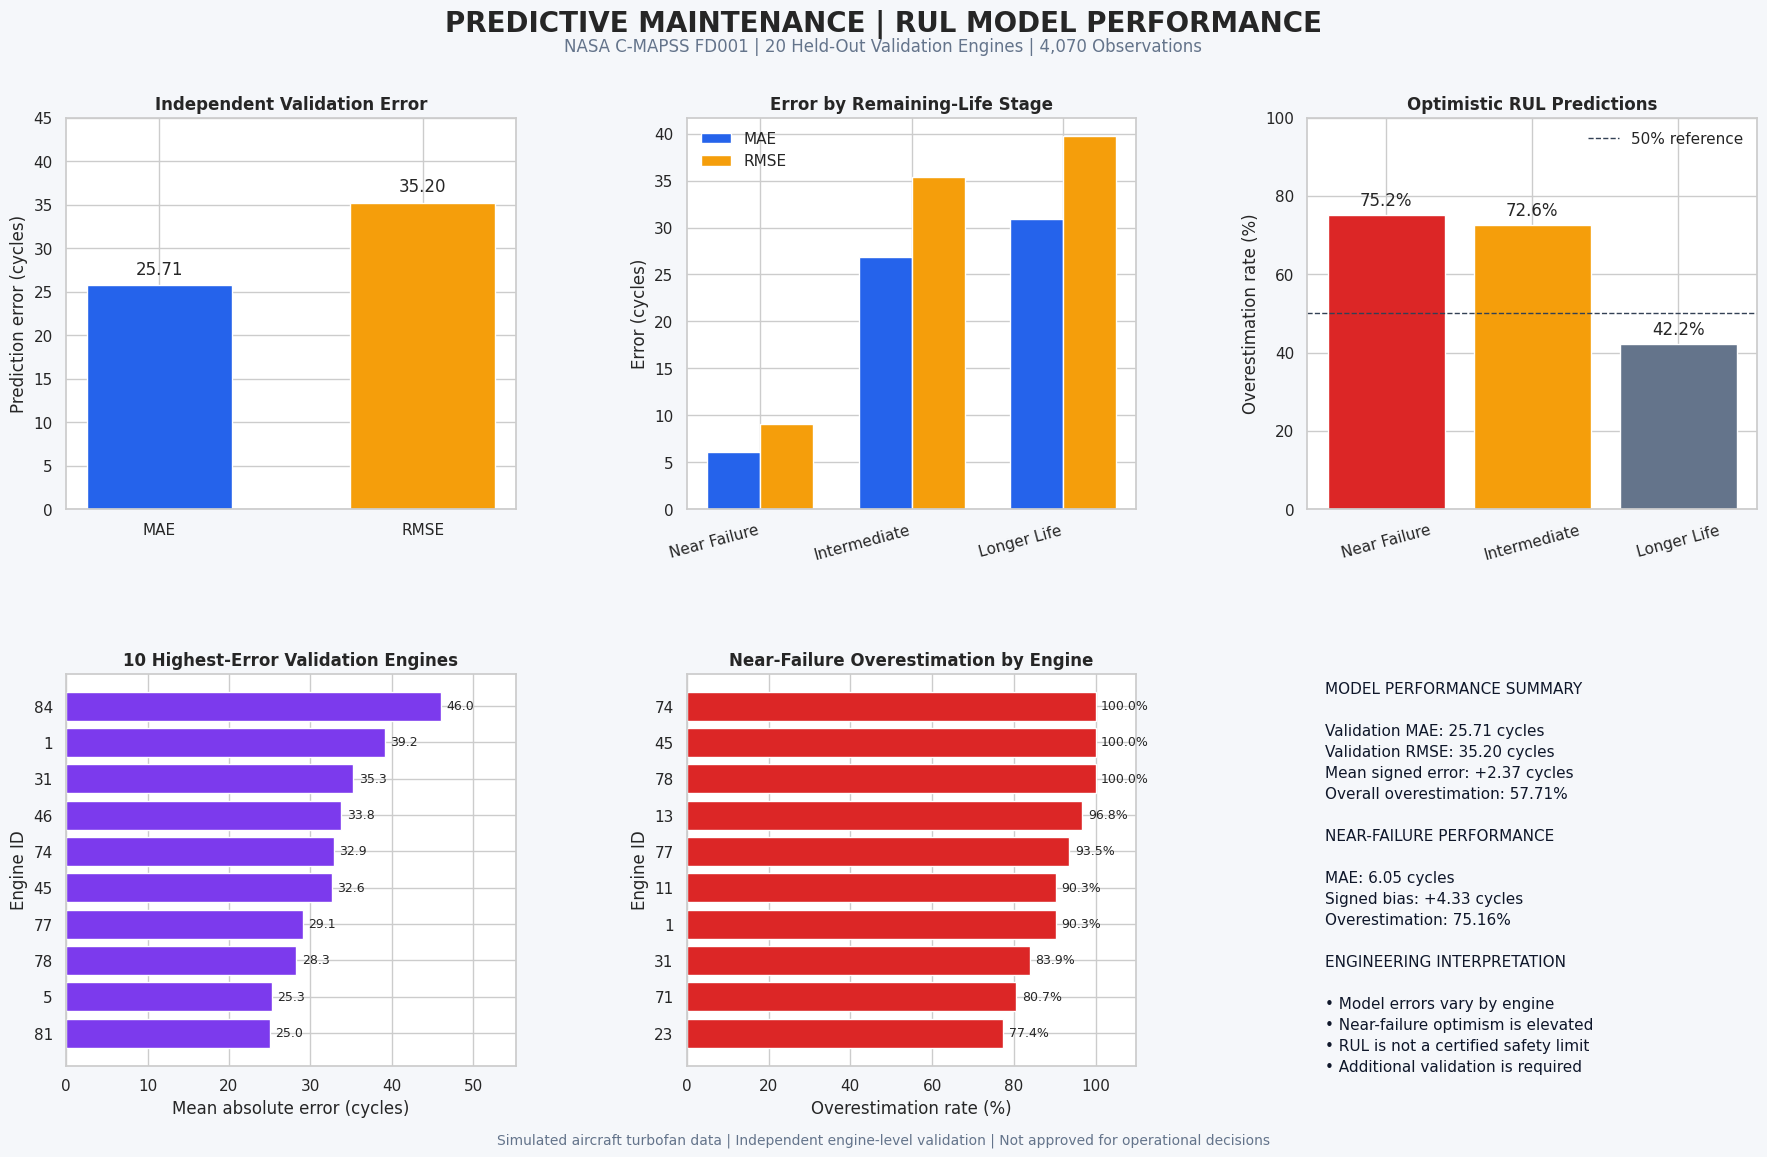

STEP 8 CELL 4 COMPLETE
----------------------
Dashboard saved:
/content/LM2500_Project/Visualizations/predictive_maintenance_dashboard.png
Resolution: 300 DPI
Summary CSV saved.
Data validation: PASSED

PREDICTIVE MAINTENANCE METRICS


,Metric,Value
0,Validation Engines,20.0000
1,Validation Observations,4070.0000
2,Validation MAE,25.7124
3,Validation RMSE,35.1956
4,Mean Signed Error,2.3704
5,Overall Overestimation Rate,57.7100
6,Near Failure MAE,6.0500
7,Near Failure Signed Bias,4.3300
8,Near Failure Overestimation Rate,75.1600


In [53]:

# STEP 8 - CELL 4
# Predictive Maintenance Dashboard
# Independent validation results only

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project_folder = Path("/content/LM2500_Project")
visual_folder = project_folder / "Visualizations"
visual_folder.mkdir(parents=True, exist_ok=True)

# ---------------------------------------
# 1. Load validated SQL analysis files
# ---------------------------------------

overall = pd.read_csv(
    project_folder / "sql_overall_rul_errors.csv"
)

categories = pd.read_csv(
    project_folder / "sql_rul_error_categories.csv"
)

high_error = pd.read_csv(
    project_folder / "sql_high_error_engines.csv"
)

near_failure = pd.read_csv(
    project_folder / "sql_near_failure_errors.csv"
)

# ---------------------------------------
# 2. Validate input data
# ---------------------------------------

assert int(overall.loc[0, "Observations"]) == 4070
assert int(overall.loc[0, "Engines"]) == 20
assert categories["Observations"].sum() == 4070
assert len(near_failure) == 20

mae = float(overall.loc[0, "MAE"])
rmse = float(overall.loc[0, "RMSE"])
bias = float(overall.loc[0, "Mean_Signed_Error"])
over_rate = float(
    overall.loc[0, "Overestimation_Rate"]
)

assert abs(mae - 25.7124) < 0.01
assert abs(rmse - 35.1956) < 0.01

category_order = [
    "Near Failure (0-30)",
    "Intermediate (31-100)",
    "Longer Life (101+)"
]

cat = categories.set_index(
    "RUL_Category"
).loc[category_order].reset_index()

short_labels = [
    "Near Failure",
    "Intermediate",
    "Longer Life"
]

# ---------------------------------------
# 3. Create six-panel dashboard
# ---------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(19, 12)
)

fig.patch.set_facecolor("#F5F7FA")

fig.suptitle(
    "PREDICTIVE MAINTENANCE | RUL MODEL PERFORMANCE",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5, 0.945,
    "NASA C-MAPSS FD001 | "
    "20 Held-Out Validation Engines | "
    "4,070 Observations",
    ha="center",
    fontsize=12,
    color="#64748B"
)

for ax in axes.flat:
    ax.set_facecolor("white")

# ---------------------------------------
# Panel 1 - Overall model error
# ---------------------------------------

ax = axes[0, 0]

bars = ax.bar(
    ["MAE", "RMSE"],
    [mae, rmse],
    color=["#2563EB", "#F59E0B"],
    width=0.55
)

ax.bar_label(bars, fmt="%.2f", padding=5)
ax.set_ylim(0, 45)
ax.set_ylabel("Prediction error (cycles)")
ax.set_title(
    "Independent Validation Error",
    fontweight="bold"
)

# ---------------------------------------
# Panel 2 - Error by RUL category
# ---------------------------------------

ax = axes[0, 1]

x = np.arange(len(cat))
width = 0.35

ax.bar(
    x - width / 2,
    cat["MAE"],
    width,
    label="MAE",
    color="#2563EB"
)

ax.bar(
    x + width / 2,
    cat["RMSE"],
    width,
    label="RMSE",
    color="#F59E0B"
)

ax.set_xticks(x)
ax.set_xticklabels(
    short_labels,
    rotation=15,
    ha="right"
)

ax.set_ylabel("Error (cycles)")
ax.set_title(
    "Error by Remaining-Life Stage",
    fontweight="bold"
)
ax.legend(frameon=False)

# ---------------------------------------
# Panel 3 - Overestimation by category
# ---------------------------------------

ax = axes[0, 2]

bars = ax.bar(
    short_labels,
    cat["Overestimation_Rate"],
    color=["#DC2626", "#F59E0B", "#64748B"]
)

ax.bar_label(
    bars,
    fmt="%.1f%%",
    padding=4
)

ax.axhline(
    50,
    color="#334155",
    linestyle="--",
    linewidth=1,
    label="50% reference"
)

ax.set_ylim(0, 100)
ax.set_ylabel("Overestimation rate (%)")
ax.set_title(
    "Optimistic RUL Predictions",
    fontweight="bold"
)
ax.tick_params(axis="x", rotation=15)
ax.legend(frameon=False)

# ---------------------------------------
# Panel 4 - Highest-error engines
# ---------------------------------------

ax = axes[1, 0]

worst = high_error.nlargest(
    10, "MAE"
).sort_values("MAE")

bars = ax.barh(
    worst["engine_id"].astype(str),
    worst["MAE"],
    color="#7C3AED"
)

ax.set_title(
    "10 Highest-Error Validation Engines",
    fontweight="bold"
)
ax.set_xlabel("Mean absolute error (cycles)")
ax.set_ylabel("Engine ID")

for bar, value in zip(bars, worst["MAE"]):
    ax.annotate(
        f"{value:.1f}",
        xy=(
            value,
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    worst["MAE"].max() * 1.2
)

# ---------------------------------------
# Panel 5 - Near-failure risk
# ---------------------------------------

ax = axes[1, 1]

highest_risk = near_failure.nlargest(
    10, "Overestimation_Rate"
).sort_values("Overestimation_Rate")

bars = ax.barh(
    highest_risk["engine_id"].astype(str),
    highest_risk["Overestimation_Rate"],
    color="#DC2626"
)

ax.set_xlim(0, 110)
ax.set_xlabel("Overestimation rate (%)")
ax.set_ylabel("Engine ID")
ax.set_title(
    "Near-Failure Overestimation by Engine",
    fontweight="bold"
)

for bar, value in zip(
    bars, highest_risk["Overestimation_Rate"]
):
    ax.annotate(
        f"{value:.1f}%",
        xy=(
            value,
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

# ---------------------------------------
# Panel 6 - Engineering summary
# ---------------------------------------

ax = axes[1, 2]
ax.axis("off")

near = cat.iloc[0]

summary = (
    "MODEL PERFORMANCE SUMMARY\n\n"
    f"Validation MAE: {mae:.2f} cycles\n"
    f"Validation RMSE: {rmse:.2f} cycles\n"
    f"Mean signed error: {bias:+.2f} cycles\n"
    f"Overall overestimation: {over_rate:.2f}%\n\n"
    "NEAR-FAILURE PERFORMANCE\n\n"
    f"MAE: {near['MAE']:.2f} cycles\n"
    f"Signed bias: {near['Mean_Signed_Error']:+.2f} cycles\n"
    f"Overestimation: "
    f"{near['Overestimation_Rate']:.2f}%\n\n"
    "ENGINEERING INTERPRETATION\n\n"
    "• Model errors vary by engine\n"
    "• Near-failure optimism is elevated\n"
    "• RUL is not a certified safety limit\n"
    "• Additional validation is required"
)

ax.text(
    0.04,
    0.98,
    summary,
    transform=ax.transAxes,
    va="top",
    fontsize=11,
    linespacing=1.5,
    color="#0F172A"
)

# ---------------------------------------
# 4. Formatting and export
# ---------------------------------------

fig.subplots_adjust(
    left=0.07,
    right=0.96,
    top=0.89,
    bottom=0.10,
    hspace=0.42,
    wspace=0.38
)

fig.text(
    0.5,
    0.035,
    "Simulated aircraft turbofan data | "
    "Independent engine-level validation | "
    "Not approved for operational decisions",
    ha="center",
    fontsize=10,
    color="#64748B"
)

dashboard_path = (
    visual_folder /
    "predictive_maintenance_dashboard.png"
)

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()
plt.close(fig)

# ---------------------------------------
# 5. Save executive metrics
# ---------------------------------------

summary_df = pd.DataFrame({
    "Metric": [
        "Validation Engines",
        "Validation Observations",
        "Validation MAE",
        "Validation RMSE",
        "Mean Signed Error",
        "Overall Overestimation Rate",
        "Near Failure MAE",
        "Near Failure Signed Bias",
        "Near Failure Overestimation Rate"
    ],
    "Value": [
        20,
        4070,
        mae,
        rmse,
        bias,
        over_rate,
        near["MAE"],
        near["Mean_Signed_Error"],
        near["Overestimation_Rate"]
    ]
})

summary_df.to_csv(
    project_folder /
    "predictive_maintenance_dashboard_summary.csv",
    index=False
)

print("STEP 8 CELL 4 COMPLETE")
print("----------------------")
print("Dashboard saved:")
print(dashboard_path)
print("Resolution: 300 DPI")
print("Summary CSV saved.")
print("Data validation: PASSED")

print("\nPREDICTIVE MAINTENANCE METRICS")
display(summary_df)


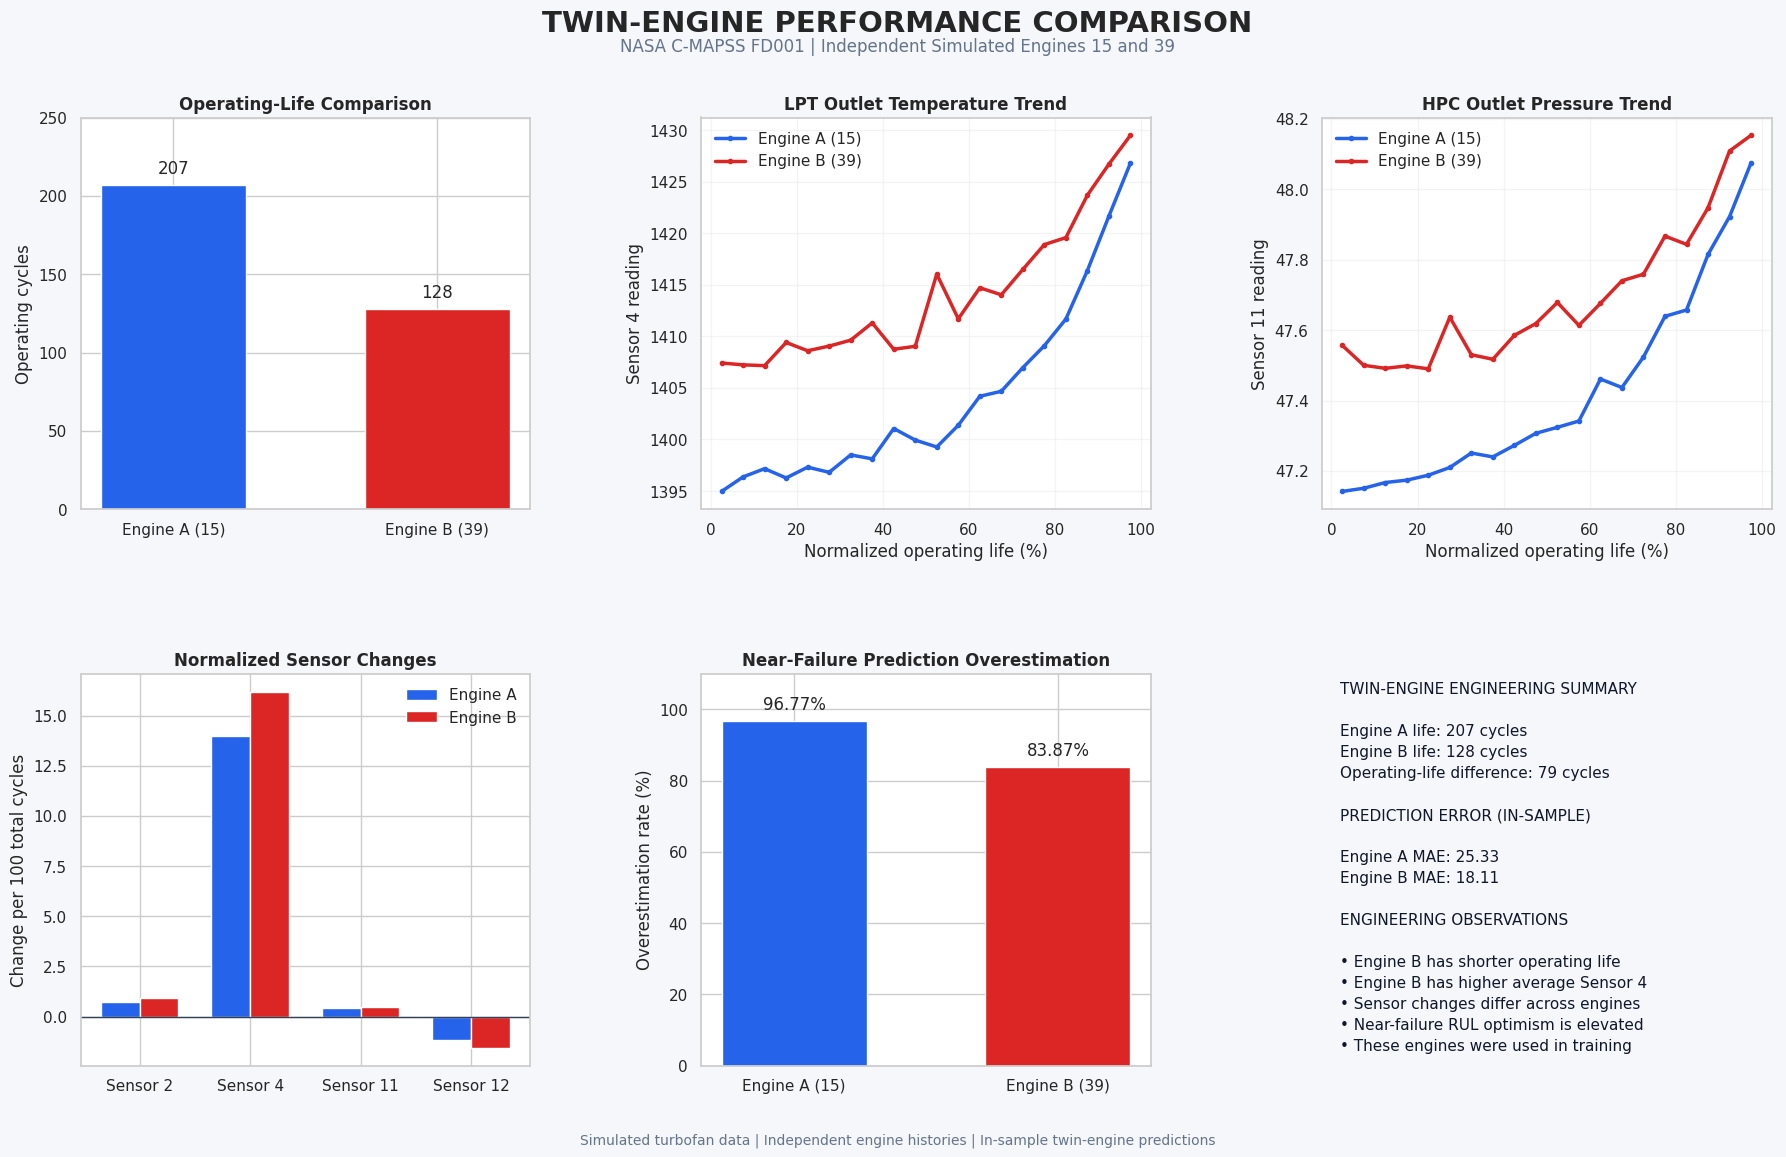

STEP 8 CELL 5 COMPLETE
----------------------
Dashboard saved:
/content/LM2500_Project/Visualizations/twin_engine_comparison_dashboard.png
Resolution: 300 DPI
Summary CSV saved.
Data validation: PASSED

TWIN-ENGINE DASHBOARD METRICS


,Metric,Value
0,Engine A Operating Cycles,207.0000
1,Engine B Operating Cycles,128.0000
2,Operating-Life Difference,79.0000
3,Engine A Sensor 4 Average,1404.0257
4,Engine B Sensor 4 Average,1414.0262
5,Engine A Prediction MAE,25.3300
6,Engine B Prediction MAE,18.1100
7,Engine A Near-Failure Overestimation,96.7700
8,Engine B Near-Failure Overestimation,83.8700


In [54]:

# STEP 8 - CELL 5
# Twin-Engine Performance Comparison Dashboard

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project_folder = Path("/content/LM2500_Project")
visual_folder = project_folder / "Visualizations"
visual_folder.mkdir(parents=True, exist_ok=True)

# ---------------------------------------
# 1. Load validated SQL outputs
# ---------------------------------------

twin = pd.read_csv(
    project_folder /
    "sql_twin_engine_unified_summary.csv"
)

normalized = pd.read_csv(
    project_folder /
    "sql_twin_engine_normalized_changes.csv"
)

near_failure = pd.read_csv(
    project_folder /
    "sql_twin_engine_near_failure.csv"
)

twin_trends = pd.read_csv(
    project_folder /
    "sensor_twin_normalized_trends.csv"
)

# ---------------------------------------
# 2. Validate data
# ---------------------------------------

assert set(twin["engine_id"]) == {15, 39}
assert set(normalized["engine_id"]) == {15, 39}
assert set(near_failure["engine_id"]) == {15, 39}
assert set(twin_trends["engine_id"]) == {15, 39}

twin = twin.set_index("engine_id").loc[[15, 39]]
normalized = normalized.set_index(
    "engine_id"
).loc[[15, 39]]
near_failure = near_failure.set_index(
    "engine_id"
).loc[[15, 39]]

engine_labels = [
    "Engine A (15)",
    "Engine B (39)"
]

colors = ["#2563EB", "#DC2626"]

# ---------------------------------------
# 3. Create six-panel dashboard
# ---------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(19, 12)
)

fig.patch.set_facecolor("#F5F7FA")

fig.suptitle(
    "TWIN-ENGINE PERFORMANCE COMPARISON",
    fontsize=21,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5, 0.945,
    "NASA C-MAPSS FD001 | "
    "Independent Simulated Engines 15 and 39",
    ha="center",
    fontsize=12,
    color="#64748B"
)

for ax in axes.flat:
    ax.set_facecolor("white")

# ---------------------------------------
# Panel 1 - Operating life
# ---------------------------------------

ax = axes[0, 0]

life = twin["operating_cycles"].values

bars = ax.bar(
    engine_labels,
    life,
    color=colors,
    width=0.55
)

ax.bar_label(bars, fmt="%.0f", padding=5)
ax.set_ylim(0, 250)
ax.set_ylabel("Operating cycles")
ax.set_title(
    "Operating-Life Comparison",
    fontweight="bold"
)

# ---------------------------------------
# Panel 2 - Sensor 4 trend
# ---------------------------------------

ax = axes[0, 1]

for engine_id, label, color in [
    (15, engine_labels[0], colors[0]),
    (39, engine_labels[1], colors[1])
]:
    data = twin_trends[
        twin_trends["engine_id"] == engine_id
    ].sort_values("life_percent")

    ax.plot(
        data["life_percent"],
        data["sensor_4"],
        color=color,
        linewidth=2.5,
        marker="o",
        markersize=3,
        label=label
    )

ax.set_title(
    "LPT Outlet Temperature Trend",
    fontweight="bold"
)
ax.set_xlabel("Normalized operating life (%)")
ax.set_ylabel("Sensor 4 reading")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

# ---------------------------------------
# Panel 3 - Sensor 11 trend
# ---------------------------------------

ax = axes[0, 2]

for engine_id, label, color in [
    (15, engine_labels[0], colors[0]),
    (39, engine_labels[1], colors[1])
]:
    data = twin_trends[
        twin_trends["engine_id"] == engine_id
    ].sort_values("life_percent")

    ax.plot(
        data["life_percent"],
        data["sensor_11"],
        color=color,
        linewidth=2.5,
        marker="o",
        markersize=3,
        label=label
    )

ax.set_title(
    "HPC Outlet Pressure Trend",
    fontweight="bold"
)
ax.set_xlabel("Normalized operating life (%)")
ax.set_ylabel("Sensor 11 reading")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

# ---------------------------------------
# Panel 4 - Normalized sensor changes
# ---------------------------------------

ax = axes[1, 0]

sensor_labels = [
    "Sensor 2",
    "Sensor 4",
    "Sensor 11",
    "Sensor 12"
]

columns = [
    "Sensor_2_Per_100_Cycles",
    "Sensor_4_Per_100_Cycles",
    "Sensor_11_Per_100_Cycles",
    "Sensor_12_Per_100_Cycles"
]

a_changes = normalized.loc[15, columns].astype(
    float
).values

b_changes = normalized.loc[39, columns].astype(
    float
).values

x = np.arange(len(sensor_labels))
width = 0.35

ax.bar(
    x - width/2,
    a_changes,
    width,
    label="Engine A",
    color=colors[0]
)

ax.bar(
    x + width/2,
    b_changes,
    width,
    label="Engine B",
    color=colors[1]
)

ax.axhline(0, color="#334155", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(sensor_labels)
ax.set_title(
    "Normalized Sensor Changes",
    fontweight="bold"
)
ax.set_ylabel("Change per 100 total cycles")
ax.legend(frameon=False)

# ---------------------------------------
# Panel 5 - Near-failure overestimation
# ---------------------------------------

ax = axes[1, 1]

over_rates = near_failure[
    "overestimation_rate"
].astype(float).values

bars = ax.bar(
    engine_labels,
    over_rates,
    color=colors,
    width=0.55
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=5
)

ax.set_ylim(0, 110)
ax.set_ylabel("Overestimation rate (%)")
ax.set_title(
    "Near-Failure Prediction Overestimation",
    fontweight="bold"
)

# ---------------------------------------
# Panel 6 - Engineering summary
# ---------------------------------------

ax = axes[1, 2]
ax.axis("off")

life_difference = int(
    twin.loc[15, "operating_cycles"]
    - twin.loc[39, "operating_cycles"]
)

summary = (
    "TWIN-ENGINE ENGINEERING SUMMARY\n\n"
    f"Engine A life: {int(life[0])} cycles\n"
    f"Engine B life: {int(life[1])} cycles\n"
    f"Operating-life difference: "
    f"{life_difference} cycles\n\n"
    "PREDICTION ERROR (IN-SAMPLE)\n\n"
    f"Engine A MAE: {twin.loc[15, 'MAE']:.2f}\n"
    f"Engine B MAE: {twin.loc[39, 'MAE']:.2f}\n\n"
    "ENGINEERING OBSERVATIONS\n\n"
    "• Engine B has shorter operating life\n"
    "• Engine B has higher average Sensor 4\n"
    "• Sensor changes differ across engines\n"
    "• Near-failure RUL optimism is elevated\n"
    "• These engines were used in training"
)

ax.text(
    0.04,
    0.98,
    summary,
    transform=ax.transAxes,
    va="top",
    fontsize=11,
    linespacing=1.5,
    color="#0F172A"
)

# ---------------------------------------
# 4. Formatting and export
# ---------------------------------------

fig.subplots_adjust(
    left=0.07,
    right=0.96,
    top=0.89,
    bottom=0.10,
    hspace=0.42,
    wspace=0.38
)

fig.text(
    0.5,
    0.035,
    "Simulated turbofan data | "
    "Independent engine histories | "
    "In-sample twin-engine predictions",
    ha="center",
    fontsize=10,
    color="#64748B"
)

dashboard_path = (
    visual_folder /
    "twin_engine_comparison_dashboard.png"
)

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()
plt.close(fig)

# ---------------------------------------
# 5. Save supporting summary
# ---------------------------------------

summary_df = pd.DataFrame({
    "Metric": [
        "Engine A Operating Cycles",
        "Engine B Operating Cycles",
        "Operating-Life Difference",
        "Engine A Sensor 4 Average",
        "Engine B Sensor 4 Average",
        "Engine A Prediction MAE",
        "Engine B Prediction MAE",
        "Engine A Near-Failure Overestimation",
        "Engine B Near-Failure Overestimation"
    ],
    "Value": [
        life[0],
        life[1],
        life_difference,
        twin.loc[15, "avg_sensor_4"],
        twin.loc[39, "avg_sensor_4"],
        twin.loc[15, "MAE"],
        twin.loc[39, "MAE"],
        over_rates[0],
        over_rates[1]
    ]
})

summary_df.to_csv(
    project_folder /
    "twin_engine_dashboard_summary.csv",
    index=False
)

print("STEP 8 CELL 5 COMPLETE")
print("----------------------")
print("Dashboard saved:")
print(dashboard_path)
print("Resolution: 300 DPI")
print("Summary CSV saved.")
print("Data validation: PASSED")

print("\nTWIN-ENGINE DASHBOARD METRICS")
display(summary_df)


In [55]:

# STEP 8 - CELL 6
# Final Dashboard Export and Validation

from pathlib import Path
from PIL import Image
import pandas as pd
import zipfile
import json
import hashlib

project_folder = Path("/content/LM2500_Project")
visual_folder = project_folder / "Visualizations"

# ---------------------------------------
# 1. Define expected dashboards
# ---------------------------------------

dashboards = {
    "Executive Fleet":
        "executive_fleet_dashboard.png",
    "Engine Operating Life":
        "engine_operating_life_dashboard.png",
    "Sensor Degradation":
        "sensor_degradation_dashboard.png",
    "Predictive Maintenance":
        "predictive_maintenance_dashboard.png",
    "Twin-Engine Comparison":
        "twin_engine_comparison_dashboard.png"
}

supporting_files = [
    "engine_operating_life_dashboard_summary.csv",
    "sensor_fleet_normalized_trends.csv",
    "sensor_twin_normalized_trends.csv",
    "predictive_maintenance_dashboard_summary.csv",
    "twin_engine_dashboard_summary.csv"
]

# ---------------------------------------
# 2. Validate dashboard files
# ---------------------------------------

records = []

for title, filename in dashboards.items():

    path = visual_folder / filename

    if not path.exists():
        raise FileNotFoundError(
            f"Missing dashboard: {path}"
        )

    with Image.open(path) as img:
        img.verify()

    with Image.open(path) as img:
        width, height = img.size
        dpi = img.info.get("dpi", (0, 0))

    file_size_mb = path.stat().st_size / (
        1024 ** 2
    )

    dpi_x = float(dpi[0])
    dpi_y = float(dpi[1])

    if dpi_x < 295 or dpi_y < 295:
        raise ValueError(
            f"Dashboard DPI below expected range: "
            f"{filename}: {dpi}"
        )

    if width < 1500 or height < 900:
        raise ValueError(
            f"Dashboard dimensions too small: "
            f"{filename}"
        )

    records.append({
        "Dashboard": title,
        "Filename": filename,
        "Width_Pixels": width,
        "Height_Pixels": height,
        "DPI_X": round(dpi_x, 2),
        "DPI_Y": round(dpi_y, 2),
        "File_Size_MB": round(file_size_mb, 2),
        "Status": "PASSED"
    })

dashboard_inventory = pd.DataFrame(records)

# ---------------------------------------
# 3. Validate supporting CSV files
# ---------------------------------------

csv_records = []

for filename in supporting_files:

    path = project_folder / filename

    if not path.exists():
        raise FileNotFoundError(
            f"Missing supporting CSV: {filename}"
        )

    df = pd.read_csv(path)

    if df.empty:
        raise ValueError(
            f"Supporting CSV is empty: {filename}"
        )

    csv_records.append({
        "Filename": filename,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Status": "PASSED"
    })

csv_inventory = pd.DataFrame(csv_records)

# ---------------------------------------
# 4. Save inventory files
# ---------------------------------------

dashboard_inventory.to_csv(
    project_folder /
    "dashboard_inventory.csv",
    index=False
)

csv_inventory.to_csv(
    project_folder /
    "dashboard_supporting_files_inventory.csv",
    index=False
)

# ---------------------------------------
# 5. Create visualization report
# ---------------------------------------

report_lines = [
    "# LM2500 Marine Gas Turbine Analytics",
    "",
    "## Step 8 - Dashboard Validation Report",
    "",
    "### Data source",
    "",
    "NASA C-MAPSS FD001 simulated aircraft "
    "turbofan engine data.",
    "",
    "This project uses the dataset as an "
    "educational proxy for marine gas turbine "
    "analytics. It does not contain actual "
    "LM2500 operational measurements.",
    "",
    "## Completed Dashboards",
    ""
]

for row in records:
    report_lines.extend([
        f"### {row['Dashboard']}",
        "",
        f"- File: `{row['Filename']}`",
        f"- Dimensions: "
        f"{row['Width_Pixels']} x "
        f"{row['Height_Pixels']} pixels",
        f"- DPI: {row['DPI_X']:.1f}",
        f"- Validation: {row['Status']}",
        ""
    ])

report_lines.extend([
    "## Engineering Findings",
    "",
    "- Fleet: 100 simulated engines.",
    "- Mean operating life: 206.31 cycles.",
    "- Median operating life: 199 cycles.",
    "- Operating-life range: 128-362 cycles.",
    "- Validation: 20 held-out engines and "
    "4,070 observations.",
    "- RUL model MAE: 25.7124 cycles.",
    "- RUL model RMSE: 35.1956 cycles.",
    "- Near-failure RUL overestimation: 75.16%.",
    "- Engine A: 207 operating cycles.",
    "- Engine B: 128 operating cycles.",
    "",
    "## Model Limitations",
    "",
    "- The dataset represents simulated "
    "aircraft turbofan engines, not marine LM2500s.",
    "- The two selected engines are independent "
    "histories, not a physically coupled pair.",
    "- Twin-engine RUL predictions are in-sample.",
    "- Normalized operating life is retrospective.",
    "- Sensor differences do not prove causation.",
    "- The model is not validated for real-world "
    "maintenance or safety decisions.",
    "",
    "## Validation",
    "",
    f"- Dashboards verified: {len(records)}",
    f"- Supporting CSV files verified: "
    f"{len(csv_records)}",
    "- Image integrity: PASSED",
    "- Image resolution: PASSED",
    "- CSV readability: PASSED",
    "",
    "## Next Step",
    "",
    "Step 9: Engineering Findings and "
    "Maintenance Recommendations.",
    ""
])

report_path = (
    project_folder /
    "dashboard_validation_report.md"
)

report_path.write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)

# ---------------------------------------
# 6. Create manifest with SHA256 hashes
# ---------------------------------------

files_to_package = [
    visual_folder / filename
    for filename in dashboards.values()
]

files_to_package += [
    project_folder / filename
    for filename in supporting_files
]

files_to_package += [
    project_folder / "dashboard_inventory.csv",
    project_folder /
    "dashboard_supporting_files_inventory.csv",
    report_path
]

manifest = []

for path in files_to_package:

    sha256 = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    manifest.append({
        "file": str(
            path.relative_to(project_folder)
        ),
        "sha256": sha256
    })

manifest_path = (
    project_folder / "dashboard_manifest.json"
)

manifest_path.write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

# ---------------------------------------
# 7. Package dashboards
# ---------------------------------------

zip_path = (
    project_folder /
    "LM2500_Step8_Dashboard_Package.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for path in files_to_package + [manifest_path]:
        archive.write(
            path,
            arcname=str(
                path.relative_to(project_folder)
            )
        )

# Verify ZIP integrity
with zipfile.ZipFile(zip_path) as archive:
    corrupt_file = archive.testzip()

    if corrupt_file is not None:
        raise ValueError(
            f"ZIP integrity failure: {corrupt_file}"
        )

# ---------------------------------------
# 8. Final output
# ---------------------------------------

print("STEP 8 CELL 6 COMPLETE")
print("----------------------")
print("Dashboards verified:", len(records))
print(
    "Supporting CSV files verified:",
    len(csv_records)
)
print("Image integrity: PASSED")
print("Resolution validation: PASSED")
print("ZIP integrity: PASSED")

print("\nDashboard package:")
print(zip_path)

print("\nValidation report:")
print(report_path)

print("\nDASHBOARD INVENTORY")
display(dashboard_inventory)

print("\nSUPPORTING CSV INVENTORY")
display(csv_inventory)

print("\nSTEP 8 STATUS: COMPLETE")


STEP 8 CELL 6 COMPLETE
----------------------
Dashboards verified: 5
Supporting CSV files verified: 5
Image integrity: PASSED
Resolution validation: PASSED
ZIP integrity: PASSED

Dashboard package:
/content/LM2500_Project/LM2500_Step8_Dashboard_Package.zip

Validation report:
/content/LM2500_Project/dashboard_validation_report.md

DASHBOARD INVENTORY


,Dashboard,Filename,Width_Pixels,Height_Pixels,DPI_X,DPI_Y,File_Size_MB,Status
0,Executive Fleet,executive_fleet_dashboard.png,4049,3221,300.0,300.0,0.54,PASSED
1,Engine Operating Life,engine_operating_life_dashboard.png,5295,3508,300.0,300.0,0.64,PASSED
2,Sensor Degradation,sensor_degradation_dashboard.png,5412,3472,300.0,300.0,0.69,PASSED
3,Predictive Maintenance,predictive_maintenance_dashboard.png,5295,3472,300.0,300.0,0.74,PASSED
4,Twin-Engine Comparison,twin_engine_comparison_dashboard.png,5354,3472,300.0,300.0,0.77,PASSED



SUPPORTING CSV INVENTORY


,Filename,Rows,Columns,Status
0,engine_operating_life_dashboard_summary.csv,8,2,PASSED
1,sensor_fleet_normalized_trends.csv,20,6,PASSED
2,sensor_twin_normalized_trends.csv,40,7,PASSED
3,predictive_maintenance_dashboard_summary.csv,9,2,PASSED
4,twin_engine_dashboard_summary.csv,9,2,PASSED



STEP 8 STATUS: COMPLETE


In [57]:

# STEP 9 - CELL 1
# Engineering Findings and Evidence Summary

from pathlib import Path
import pandas as pd

project = Path("/content/LM2500_Project")

# Load validated project outputs
fleet = pd.read_csv(
    project / "sql_final_engineering_summary.csv"
)

model = pd.read_csv(
    project / "predictive_maintenance_dashboard_summary.csv"
)

twin = pd.read_csv(
    project / "twin_engine_dashboard_summary.csv"
)

sensor = pd.read_csv(
    project / "sql_fleet_degradation_summary.csv"
)

def metric(df, name):
    return float(
        df.loc[df["Metric"] == name, "Value"].iloc[0]
    )

mae = metric(model, "Validation MAE")
rmse = metric(model, "Validation RMSE")
bias = metric(model, "Mean Signed Error")
near_mae = metric(model, "Near Failure MAE")
near_bias = metric(
    model, "Near Failure Signed Bias"
)
near_over = metric(
    model, "Near Failure Overestimation Rate"
)

a_life = metric(twin, "Engine A Operating Cycles")
b_life = metric(twin, "Engine B Operating Cycles")
a_temp = metric(twin, "Engine A Sensor 4 Average")
b_temp = metric(twin, "Engine B Sensor 4 Average")

s2 = float(sensor.loc[0, "Avg_Sensor_2_Change"])
s4 = float(sensor.loc[0, "Avg_Sensor_4_Change"])
s11 = float(sensor.loc[0, "Avg_Sensor_11_Change"])
s12 = float(sensor.loc[0, "Avg_Sensor_12_Change"])

# Validate known results
assert abs(mae - 25.7124) < 0.01
assert abs(rmse - 35.1956) < 0.01
assert abs(a_life - 207) < 0.01
assert abs(b_life - 128) < 0.01
assert abs(s4 - 22.3255) < 0.01

report = f"""# Engineering Findings and Evidence Summary

## Project
LM2500 Marine Gas Turbine Performance &
Predictive Maintenance Analytics

## Data Source and Scope

NASA C-MAPSS FD001 simulated aircraft turbofan
engine data, used as an educational proxy for
marine gas turbine condition-monitoring analysis.

These are not actual LM2500 operating records.

## Finding 1: Operating-Life Variability

- Engines analyzed: 100
- Average operating life: 206.31 cycles
- Median operating life: 199 cycles
- Minimum operating life: 128 cycles
- Maximum operating life: 362 cycles
- Standard deviation: 46.34 cycles

Interpretation:
Operating life varies substantially across the
simulated fleet. This supports investigating
condition indicators and variation between
engine histories.

## Finding 2: Sensor Behavior

Fleet average early-to-late changes:

- Sensor 2: {s2:+.4f}
- Sensor 4: {s4:+.4f}
- Sensor 11: {s11:+.4f}
- Sensor 12: {s12:+.4f}

Interpretation:
The selected sensor channels exhibit systematic
average changes over completed engine histories.

These measurements have different physical units.
They cannot be directly compared as equivalent
degradation magnitudes.

Sensor associations do not establish causation.

## Finding 3: Predictive Model Performance

Independent validation:

- Held-out engines: 20
- Validation observations: 4,070
- MAE: {mae:.4f} cycles
- RMSE: {rmse:.4f} cycles
- Mean signed error: {bias:+.4f} cycles

Interpretation:
The Random Forest model predicts remaining
useful life with meaningful accuracy on the
held-out simulated engines.

Its error magnitude and bias require additional
evaluation before any operational application.

## Finding 4: Near-Failure Prediction Risk

For actual remaining life of 0-30 cycles:

- MAE: {near_mae:.2f} cycles
- Mean signed error: {near_bias:+.2f} cycles
- Overestimation rate: {near_over:.2f}%

Interpretation:
The model frequently overestimates remaining
life near failure. This is a potential concern
for maintenance planning because optimistic
predictions could delay inspection or intervention.

No operational maintenance threshold has been
validated by this project.

## Finding 5: Twin-Engine Comparison

Engine A (NASA ID 15):
- Operating life: {a_life:.0f} cycles
- Mean Sensor 4: {a_temp:.4f}

Engine B (NASA ID 39):
- Operating life: {b_life:.0f} cycles
- Mean Sensor 4: {b_temp:.4f}

Operating-life difference:
{a_life - b_life:.0f} cycles

Mean Sensor 4 difference (B minus A):
{b_temp - a_temp:+.4f}

Interpretation:
Engine B has a shorter operating life and
higher average Sensor 4 readings.

These engines are independent simulated
histories, not a physically coupled marine
twin-engine installation.

Their previously calculated prediction errors
are in-sample and are not independent
validation results.

## Preliminary Engineering Implications

1. Investigate temperature and pressure trends
   as candidate condition-monitoring features.

2. Evaluate prediction uncertainty and the
   consequences of remaining-life overestimation.

3. Compare model behavior across individual
   engines and operating-life stages.

4. Validate any proposed maintenance thresholds
   using representative operational data and
   qualified engineering review.

## Limitations

- Simulated aircraft turbofan dataset.
- No actual LM2500 marine operating records.
- Retrospective degradation measurements.
- No demonstrated sensor-to-failure causation.
- No validated operational alarm thresholds.
- No approval for real maintenance decisions.

## Next Task

Step 9, Cell 2:
Maintenance Recommendations and Proposed
Condition-Monitoring Strategies.
"""

output = project / "engineering_findings_report.md"
output.write_text(report, encoding="utf-8")

assert output.exists()
assert output.stat().st_size > 1000

print("STEP 9 CELL 1 COMPLETE")
print("----------------------")
print("Engineering findings report saved:")
print(output)
print("Evidence validation: PASSED")
print("Report size:", output.stat().st_size, "bytes")

print("\nKEY ENGINEERING FINDINGS")
print(f"Validation MAE: {mae:.2f} cycles")
print(f"Validation RMSE: {rmse:.2f} cycles")
print(f"Near-failure overestimation: {near_over:.2f}%")
print(f"Engine operating-life difference: {a_life-b_life:.0f} cycles")
print(f"Fleet Sensor 4 change: {s4:+.4f}")


STEP 9 CELL 1 COMPLETE
----------------------
Engineering findings report saved:
/content/LM2500_Project/engineering_findings_report.md
Evidence validation: PASSED
Report size: 3510 bytes

KEY ENGINEERING FINDINGS
Validation MAE: 25.71 cycles
Validation RMSE: 35.20 cycles
Near-failure overestimation: 75.16%
Engine operating-life difference: 79 cycles
Fleet Sensor 4 change: +22.3255


In [58]:

# STEP 9 - CELL 2
# Maintenance Recommendations and Action Plan

from pathlib import Path
import pandas as pd

project = Path("/content/LM2500_Project")

# ---------------------------------------
# 1. Verify engineering findings
# ---------------------------------------

findings_path = (
    project / "engineering_findings_report.md"
)

assert findings_path.exists(), (
    "Step 9 Cell 1 report is missing."
)

model = pd.read_csv(
    project /
    "predictive_maintenance_dashboard_summary.csv"
)

def get_metric(name):
    return float(
        model.loc[
            model["Metric"] == name, "Value"
        ].iloc[0]
    )

mae = get_metric("Validation MAE")
rmse = get_metric("Validation RMSE")
near_over = get_metric(
    "Near Failure Overestimation Rate"
)

assert abs(mae - 25.7124) < 0.01
assert abs(rmse - 35.1956) < 0.01
assert abs(near_over - 75.16) < 0.01

# ---------------------------------------
# 2. Define proposed recommendations
# ---------------------------------------

recommendations = [
    {
        "Priority": 1,
        "Area": "Sensor Condition Monitoring",
        "Evidence": (
            "Fleet Sensor 4 increased by 22.3255 "
            "native units and Sensor 11 by 0.6811 "
            "between early and late observations."
        ),
        "Proposed_Action": (
            "Develop trend monitoring for selected "
            "temperature and pressure channels. "
            "Evaluate baseline-relative changes, "
            "sensor quality, and operating context."
        ),
        "Expected_Benefit": (
            "Improved visibility into developing "
            "equipment-condition changes."
        ),
        "Validation_Requirement": (
            "Confirm sensor definitions, calibration, "
            "normal operating ranges, and behavior "
            "using representative equipment data."
        )
    },
    {
        "Priority": 2,
        "Area": "RUL Prediction Risk",
        "Evidence": (
            f"Near-failure predictions overestimated "
            f"remaining life {near_over:.2f}% of the "
            "time on held-out validation engines."
        ),
        "Proposed_Action": (
            "Investigate calibrated prediction "
            "intervals, conservative lower-bound "
            "estimates, and explicit uncertainty "
            "reporting rather than relying on "
            "point predictions alone."
        ),
        "Expected_Benefit": (
            "Better understanding of prediction "
            "uncertainty and optimistic model errors."
        ),
        "Validation_Requirement": (
            "Evaluate calibration, coverage, false "
            "alarms, missed detections, and maintenance "
            "consequences on independent datasets."
        )
    },
    {
        "Priority": 3,
        "Area": "Equipment Reliability Analysis",
        "Evidence": (
            "The simulated fleet ranged from "
            "128 to 362 operating cycles, with "
            "a standard deviation of 46.34 cycles."
        ),
        "Proposed_Action": (
            "Compare engine-level histories and "
            "investigate variation in sensor behavior, "
            "operating conditions, and failure timing."
        ),
        "Expected_Benefit": (
            "Identification of unusual histories "
            "for further engineering investigation."
        ),
        "Validation_Requirement": (
            "Account for operating regimes, exposure, "
            "maintenance history, and differences "
            "between engine populations."
        )
    },
    {
        "Priority": 4,
        "Area": "Inspection Prioritization",
        "Evidence": (
            "Model errors differ across remaining-life "
            "stages and individual validation engines."
        ),
        "Proposed_Action": (
            "Design a prototype review queue combining "
            "sensor anomalies, data quality flags, "
            "model uncertainty, and engineer assessment. "
            "Do not use unvalidated RUL predictions "
            "as automatic inspection triggers."
        ),
        "Expected_Benefit": (
            "A structured approach to reviewing "
            "potential equipment concerns."
        ),
        "Validation_Requirement": (
            "Have qualified maintenance engineers "
            "evaluate proposed rules against approved "
            "procedures and actual failure outcomes."
        )
    },
    {
        "Priority": 5,
        "Area": "Predictive Model Improvement",
        "Evidence": (
            f"Held-out validation MAE was "
            f"{mae:.2f} cycles and RMSE was "
            f"{rmse:.2f} cycles."
        ),
        "Proposed_Action": (
            "Compare additional models, assess "
            "feature stability, test prediction "
            "calibration, and evaluate generalization "
            "across operating conditions."
        ),
        "Expected_Benefit": (
            "More reliable characterization of "
            "model accuracy and limitations."
        ),
        "Validation_Requirement": (
            "Use engine-level separation, untouched "
            "test data, and documented evaluation "
            "criteria. Avoid test-data leakage."
        )
    }
]

df = pd.DataFrame(recommendations)

assert len(df) == 5
assert df["Priority"].is_unique

# ---------------------------------------
# 3. Export structured action plan
# ---------------------------------------

csv_path = (
    project /
    "maintenance_recommendations_action_plan.csv"
)

df.to_csv(csv_path, index=False)

# ---------------------------------------
# 4. Generate engineering report
# ---------------------------------------

lines = [
    "# Maintenance Recommendations",
    "",
    "## LM2500 Marine Gas Turbine Analytics",
    "",
    "### Scope",
    "",
    "These recommendations are research and "
    "engineering-development proposals based on "
    "NASA C-MAPSS FD001 simulated aircraft "
    "turbofan data.",
    "",
    "They are not approved LM2500 maintenance "
    "instructions, inspection intervals, "
    "alarm limits, or operating procedures.",
    "",
    "## Evidence-Based Recommendations",
    ""
]

for rec in recommendations:

    lines.extend([
        f"### Priority {rec['Priority']}: "
        f"{rec['Area']}",
        "",
        "**Supporting Evidence**",
        "",
        rec["Evidence"],
        "",
        "**Proposed Engineering Action**",
        "",
        rec["Proposed_Action"],
        "",
        "**Expected Benefit**",
        "",
        rec["Expected_Benefit"],
        "",
        "**Required Validation**",
        "",
        rec["Validation_Requirement"],
        ""
    ])

lines.extend([
    "## Suggested Development Sequence",
    "",
    "1. Verify source data and sensor definitions.",
    "2. Build baseline-relative condition trends.",
    "3. Evaluate model uncertainty and error bias.",
    "4. Prototype an engineer-reviewed alert queue.",
    "5. Test with independent representative data.",
    "6. Obtain appropriate engineering approval "
    "before any operational use.",
    "",
    "## Engineering Safety Boundary",
    "",
    "Continue using approved OEM and site-specific "
    "maintenance procedures for actual equipment. "
    "No simulated-data threshold or model output "
    "should replace qualified engineering judgment.",
    "",
    "## Next Task",
    "",
    "Step 9 Cell 3: Model Limitations, "
    "Risk Controls, and Implementation Requirements.",
    ""
])

report_path = (
    project /
    "maintenance_recommendations_report.md"
)

report_path.write_text(
    "\n".join(lines),
    encoding="utf-8"
)

# ---------------------------------------
# 5. Validate exports
# ---------------------------------------

saved = pd.read_csv(csv_path)

assert len(saved) == 5
assert saved["Priority"].tolist() == [
    1, 2, 3, 4, 5
]
assert report_path.stat().st_size > 2000

print("STEP 9 CELL 2 COMPLETE")
print("----------------------")
print("Recommendations generated:", len(saved))
print("Action plan CSV saved:")
print(csv_path)
print("Engineering report saved:")
print(report_path)
print("Data validation: PASSED")

print("\nMAINTENANCE RECOMMENDATION PRIORITIES")
display(saved[["Priority", "Area", "Expected_Benefit"]])


STEP 9 CELL 2 COMPLETE
----------------------
Recommendations generated: 5
Action plan CSV saved:
/content/LM2500_Project/maintenance_recommendations_action_plan.csv
Engineering report saved:
/content/LM2500_Project/maintenance_recommendations_report.md
Data validation: PASSED

MAINTENANCE RECOMMENDATION PRIORITIES


,Priority,Area,Expected_Benefit
0,1,Sensor Condition Monitoring,Improved visibility into developing equipment-...
1,2,RUL Prediction Risk,Better understanding of prediction uncertainty...
2,3,Equipment Reliability Analysis,Identification of unusual histories for furthe...
3,4,Inspection Prioritization,A structured approach to reviewing potential e...
4,5,Predictive Model Improvement,More reliable characterization of model accura...


In [59]:

# STEP 9 - CELL 3
# Model Limitations, Risk Controls,
# and Implementation Requirements

from pathlib import Path
import pandas as pd

project = Path("/content/LM2500_Project")

# ---------------------------------------
# 1. Verify previous reports
# ---------------------------------------

required = [
    "engineering_findings_report.md",
    "maintenance_recommendations_report.md",
    "maintenance_recommendations_action_plan.csv"
]

for filename in required:
    assert (project / filename).exists(), (
        f"Missing required file: {filename}"
    )

# ---------------------------------------
# 2. Define preliminary risk register
# ---------------------------------------

risks = [
    {
        "Risk_ID": "R01",
        "Risk": "Dataset representativeness",
        "Likelihood": 5,
        "Impact": 5,
        "Evidence": (
            "NASA C-MAPSS FD001 represents simulated "
            "aircraft turbofans, not operational "
            "LM2500 marine gas turbines."
        ),
        "Mitigation": (
            "Obtain authorized representative marine "
            "turbine data and verify equipment, sensor, "
            "operating-regime, and failure-mode mapping."
        ),
        "Validation": (
            "Document data provenance, applicability, "
            "and engineering approval of the dataset."
        )
    },
    {
        "Risk_ID": "R02",
        "Risk": "Optimistic RUL predictions",
        "Likelihood": 5,
        "Impact": 5,
        "Evidence": (
            "75.16% of held-out near-failure "
            "predictions overestimated actual RUL."
        ),
        "Mitigation": (
            "Investigate calibrated uncertainty "
            "intervals, conservative lower bounds, "
            "and human-reviewed decision rules."
        ),
        "Validation": (
            "Test interval coverage, error direction, "
            "missed detections, and false alarms on "
            "independent engine histories."
        )
    },
    {
        "Risk_ID": "R03",
        "Risk": "Sensor data quality",
        "Likelihood": 3,
        "Impact": 4,
        "Evidence": (
            "Sensor-based predictions depend on "
            "measurement quality; actual marine "
            "sensor calibration and reliability "
            "were not evaluated."
        ),
        "Mitigation": (
            "Implement missing-data checks, "
            "range validation, calibration review, "
            "and sensor fault detection."
        ),
        "Validation": (
            "Test representative missing, noisy, "
            "stuck, and out-of-range sensor scenarios."
        )
    },
    {
        "Risk_ID": "R04",
        "Risk": "Generalization and leakage",
        "Likelihood": 4,
        "Impact": 4,
        "Evidence": (
            "The model was validated on 20 held-out "
            "engines. Twin-engine prediction results "
            "were calculated on training engines."
        ),
        "Mitigation": (
            "Preserve engine-level separation, "
            "document preprocessing boundaries, "
            "and evaluate additional untouched "
            "engine populations."
        ),
        "Validation": (
            "Audit train/test separation and repeat "
            "evaluation across independent datasets."
        )
    },
    {
        "Risk_ID": "R05",
        "Risk": "Unvalidated maintenance decisions",
        "Likelihood": 4,
        "Impact": 5,
        "Evidence": (
            "No OEM-approved inspection thresholds "
            "or maintenance decision rules were "
            "established by this project."
        ),
        "Mitigation": (
            "Keep analytics advisory-only. Require "
            "qualified engineering review and "
            "continue following approved OEM "
            "maintenance procedures."
        ),
        "Validation": (
            "Complete operational hazard assessment, "
            "procedure review, and formal authorization "
            "before any maintenance integration."
        )
    },
    {
        "Risk_ID": "R06",
        "Risk": "Model drift and monitoring",
        "Likelihood": 3,
        "Impact": 4,
        "Evidence": (
            "The project does not include a deployed "
            "model or longitudinal operational "
            "performance monitoring."
        ),
        "Mitigation": (
            "Design monitoring for data distributions, "
            "prediction quality, uncertainty, and "
            "model version changes."
        ),
        "Validation": (
            "Establish baseline metrics and test "
            "monitoring procedures before deployment."
        )
    }
]

risk_df = pd.DataFrame(risks)

risk_df["Risk_Score"] = (
    risk_df["Likelihood"] * risk_df["Impact"]
)

def risk_level(score):
    if score >= 20:
        return "Critical"
    elif score >= 12:
        return "High"
    elif score >= 6:
        return "Moderate"
    return "Low"

risk_df["Preliminary_Risk_Level"] = (
    risk_df["Risk_Score"].apply(risk_level)
)

risk_df = risk_df.sort_values(
    ["Risk_Score", "Risk_ID"],
    ascending=[False, True]
).reset_index(drop=True)

# ---------------------------------------
# 3. Define implementation requirements
# ---------------------------------------

requirements = [
    {
        "Phase": 1,
        "Stage": "Data Qualification",
        "Requirement": (
            "Obtain representative operational data "
            "with documented sensor definitions, "
            "failure labels, and equipment history."
        ),
        "Exit_Criterion": (
            "Qualified engineers approve data "
            "provenance and intended analytical use."
        )
    },
    {
        "Phase": 2,
        "Stage": "Sensor and Feature Validation",
        "Requirement": (
            "Validate sensor calibration, missing-data "
            "handling, feature engineering, and "
            "operating-condition normalization."
        ),
        "Exit_Criterion": (
            "Documented data-quality tests and "
            "repeatable feature-generation results."
        )
    },
    {
        "Phase": 3,
        "Stage": "Independent Model Evaluation",
        "Requirement": (
            "Test unseen engine histories, prediction "
            "bias, uncertainty calibration, and "
            "failure-stage performance."
        ),
        "Exit_Criterion": (
            "Predefined performance and safety-related "
            "acceptance criteria are satisfied."
        )
    },
    {
        "Phase": 4,
        "Stage": "Engineering Review",
        "Requirement": (
            "Evaluate model limitations, proposed "
            "alert rules, failure consequences, "
            "and approved maintenance procedures."
        ),
        "Exit_Criterion": (
            "Qualified engineering and maintenance "
            "stakeholders approve the proposed scope."
        )
    },
    {
        "Phase": 5,
        "Stage": "Advisory Pilot",
        "Requirement": (
            "Run a monitored shadow-mode pilot "
            "without changing actual maintenance "
            "decisions or approved intervals."
        ),
        "Exit_Criterion": (
            "Pilot performance, false alarms, "
            "missed detections, and drift are reviewed."
        )
    },
    {
        "Phase": 6,
        "Stage": "Operational Authorization",
        "Requirement": (
            "Complete applicable safety, cybersecurity, "
            "configuration, training, and maintenance "
            "approval processes."
        ),
        "Exit_Criterion": (
            "Formal authorization is documented "
            "before any operational integration."
        )
    }
]

req_df = pd.DataFrame(requirements)

# ---------------------------------------
# 4. Export CSV files
# ---------------------------------------

risk_path = project / "engineering_risk_register.csv"
req_path = project / "implementation_requirements.csv"

risk_df.to_csv(risk_path, index=False)
req_df.to_csv(req_path, index=False)

# ---------------------------------------
# 5. Generate Markdown report
# ---------------------------------------

lines = [
    "# Model Limitations and Risk Controls",
    "",
    "## LM2500 Marine Gas Turbine Analytics",
    "",
    "### Scope",
    "",
    "This is a preliminary engineering-development "
    "risk assessment for an educational project "
    "using NASA C-MAPSS FD001 simulated data.",
    "",
    "Risk scores are illustrative judgments, "
    "not measured probabilities or approved "
    "operational safety classifications.",
    "",
    "## Risk Register",
    ""
]

for _, row in risk_df.iterrows():
    lines.extend([
        f"### {row['Risk_ID']}: {row['Risk']}",
        "",
        f"- Likelihood: {row['Likelihood']}/5",
        f"- Impact: {row['Impact']}/5",
        f"- Preliminary score: {row['Risk_Score']}/25",
        f"- Preliminary level: "
        f"{row['Preliminary_Risk_Level']}",
        "",
        "**Evidence / limitation**",
        "",
        row["Evidence"],
        "",
        "**Proposed mitigation**",
        "",
        row["Mitigation"],
        "",
        "**Validation requirement**",
        "",
        row["Validation"],
        ""
    ])

lines.extend([
    "## Implementation Requirements",
    ""
])

for _, row in req_df.iterrows():
    lines.extend([
        f"### Phase {row['Phase']}: {row['Stage']}",
        "",
        row["Requirement"],
        "",
        f"**Exit criterion:** {row['Exit_Criterion']}",
        ""
    ])

lines.extend([
    "## Engineering Safety Boundary",
    "",
    "The model is not approved for actual "
    "LM2500 maintenance scheduling, "
    "equipment shutdown, or alarm decisions.",
    "",
    "Actual maintenance must follow applicable "
    "OEM guidance and approved procedures.",
    "",
    "## Next Step",
    "",
    "Step 9 Cell 4: Final Engineering "
    "Recommendations Report.",
    ""
])

report_path = (
    project / "engineering_risk_assessment.md"
)

report_path.write_text(
    "\n".join(lines),
    encoding="utf-8"
)

# ---------------------------------------
# 6. Validate outputs
# ---------------------------------------

assert len(risk_df) == 6
assert len(req_df) == 6
assert risk_df["Risk_ID"].is_unique
assert req_df["Phase"].is_unique
assert report_path.stat().st_size > 3000

assert all(
    risk_df["Risk_Score"]
    == risk_df["Likelihood"] * risk_df["Impact"]
)

print("STEP 9 CELL 3 COMPLETE")
print("----------------------")
print("Risks assessed:", len(risk_df))
print("Implementation phases:", len(req_df))
print("Risk register saved:", risk_path)
print("Requirements saved:", req_path)
print("Engineering report saved:", report_path)
print("Data validation: PASSED")

print("\nPRELIMINARY RISK REGISTER")
display(
    risk_df[
        [
            "Risk_ID",
            "Risk",
            "Likelihood",
            "Impact",
            "Risk_Score",
            "Preliminary_Risk_Level"
        ]
    ]
)

print("\nIMPLEMENTATION ROADMAP")
display(
    req_df[
        ["Phase", "Stage", "Exit_Criterion"]
    ]
)


STEP 9 CELL 3 COMPLETE
----------------------
Risks assessed: 6
Implementation phases: 6
Risk register saved: /content/LM2500_Project/engineering_risk_register.csv
Requirements saved: /content/LM2500_Project/implementation_requirements.csv
Engineering report saved: /content/LM2500_Project/engineering_risk_assessment.md
Data validation: PASSED

PRELIMINARY RISK REGISTER


,Risk_ID,Risk,Likelihood,Impact,Risk_Score,Preliminary_Risk_Level
0,R01,Dataset representativeness,5,5,25,Critical
1,R02,Optimistic RUL predictions,5,5,25,Critical
2,R05,Unvalidated maintenance decisions,4,5,20,Critical
3,R04,Generalization and leakage,4,4,16,High
4,R03,Sensor data quality,3,4,12,High
5,R06,Model drift and monitoring,3,4,12,High



IMPLEMENTATION ROADMAP


,Phase,Stage,Exit_Criterion
0,1,Data Qualification,Qualified engineers approve data provenance an...
1,2,Sensor and Feature Validation,Documented data-quality tests and repeatable f...
2,3,Independent Model Evaluation,Predefined performance and safety-related acce...
3,4,Engineering Review,Qualified engineering and maintenance stakehol...
4,5,Advisory Pilot,"Pilot performance, false alarms, missed detect..."
5,6,Operational Authorization,Formal authorization is documented before any ...


In [60]:

# STEP 9 - CELL 4
# Final Engineering Recommendations Report

from pathlib import Path
import pandas as pd

project = Path("/content/LM2500_Project")

# ---------------------------------------
# 1. Verify required source files
# ---------------------------------------

required_files = {
    "Findings": "engineering_findings_report.md",
    "Recommendations": "maintenance_recommendations_report.md",
    "Risk Assessment": "engineering_risk_assessment.md",
    "Action Plan": "maintenance_recommendations_action_plan.csv",
    "Risk Register": "engineering_risk_register.csv",
    "Implementation Roadmap": "implementation_requirements.csv"
}

for name, filename in required_files.items():
    path = project / filename
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(
            f"Missing or empty {name}: {filename}"
        )

# ---------------------------------------
# 2. Load validated engineering records
# ---------------------------------------

recommendations = pd.read_csv(
    project /
    "maintenance_recommendations_action_plan.csv"
)

risks = pd.read_csv(
    project / "engineering_risk_register.csv"
)

roadmap = pd.read_csv(
    project / "implementation_requirements.csv"
)

assert len(recommendations) == 5
assert len(risks) == 6
assert len(roadmap) == 6

assert set(recommendations["Priority"]) == set(range(1, 6))
assert set(risks["Risk_ID"]) == {
    f"R{i:02d}" for i in range(1, 7)
}
assert set(roadmap["Phase"]) == set(range(1, 7))

# ---------------------------------------
# 3. Read previous engineering reports
# ---------------------------------------

def read_report(filename):
    return (
        project / filename
    ).read_text(encoding="utf-8").strip()

findings_text = read_report(
    "engineering_findings_report.md"
)

recommendations_text = read_report(
    "maintenance_recommendations_report.md"
)

risk_text = read_report(
    "engineering_risk_assessment.md"
)

# Remove duplicate top-level titles
def as_section(text, heading):
    lines = text.splitlines()
    if lines and lines[0].startswith("# "):
        lines = lines[1:]
    return (
        f"## {heading}\n\n"
        + "\n".join(lines).strip()
    )

# ---------------------------------------
# 4. Create executive summary
# ---------------------------------------

executive_summary = """
# LM2500 Marine Gas Turbine
# Performance and Predictive Maintenance Analytics

## Final Engineering Recommendations Report

### Executive Summary

This educational engineering analytics project
evaluates simulated gas turbine operating histories,
sensor trends, and remaining useful life predictions.

The analysis uses NASA C-MAPSS FD001 simulated
aircraft turbofan data as a proxy for exploring
marine gas turbine condition-monitoring concepts.

It does not contain actual GE LM2500 marine gas
turbine operational measurements.

### Dataset and Fleet

- Simulated engines: 100
- Operating observations: 20,631
- Mean engine operating life: 206.31 cycles
- Median operating life: 199 cycles
- Minimum operating life: 128 cycles
- Maximum operating life: 362 cycles

### Predictive Maintenance Model

Random Forest regression was evaluated using
engine-level training and validation separation.

- Training engines: 80
- Held-out validation engines: 20
- Validation observations: 4,070
- Mean absolute error: 25.71 cycles
- Root mean squared error: 35.20 cycles
- R-squared: 0.7126

Near-failure remaining-life overestimation
occurred in 75.16% of held-out observations
with actual RUL between 0 and 30 cycles.

### Twin-Engine Comparison

Two independent simulated engine histories
were compared as an educational twin-engine
case study.

- Engine A (ID 15): 207 operating cycles
- Engine B (ID 39): 128 operating cycles
- Difference: 79 cycles

These are not physically coupled marine engines.
Their previously reported model predictions
were calculated in-sample.

### Principal Engineering Conclusion

Sensor trends and machine learning predictions
can support condition-monitoring research, but
the observed RUL overestimation, domain mismatch,
and absence of operational validation prevent
using this model for real maintenance decisions.

All proposed maintenance recommendations
require independent testing, qualified
engineering review, and applicable approval.
"""

# ---------------------------------------
# 5. Consolidate complete report
# ---------------------------------------

sections = [
    executive_summary.strip(),
    as_section(
        findings_text,
        "Detailed Engineering Findings"
    ),
    as_section(
        recommendations_text,
        "Maintenance Recommendations"
    ),
    as_section(
        risk_text,
        "Engineering Risk Assessment"
    ),
    """## Final Engineering Conclusions

1. The simulated fleet exhibits substantial
   variation in operating life.

2. Selected temperature and pressure channels
   exhibit retrospective degradation-related
   trends that warrant further investigation.

3. The Random Forest model demonstrates
   predictive capability on held-out simulated
   engines, but errors remain significant.

4. Optimistic near-failure RUL estimates are
   a key model-risk concern.

5. The proposed maintenance framework is
   advisory and requires representative
   operational data and engineering approval.

## Operational Safety Boundary

This project is not an approved LM2500
diagnostic, alarm, inspection, shutdown,
or maintenance scheduling system.

Actual equipment maintenance must follow
approved OEM and site-specific procedures.

## Project Status

Step 9: Engineering Findings and
Maintenance Recommendations — COMPLETE.

Next: Step 10 — Final Project Report,
Portfolio Packaging, and GitHub Publication.
"""
]

final_report = "\n\n---\n\n".join(sections) + "\n"

report_path = (
    project /
    "LM2500_Final_Engineering_Recommendations.md"
)

report_path.write_text(
    final_report,
    encoding="utf-8"
)

# ---------------------------------------
# 6. Create Step 9 completion checklist
# ---------------------------------------

checklist = pd.DataFrame([
    {
        "Cell": 1,
        "Deliverable": "Engineering findings",
        "File": "engineering_findings_report.md",
        "Status": "COMPLETE"
    },
    {
        "Cell": 2,
        "Deliverable": "Maintenance recommendations",
        "File": "maintenance_recommendations_report.md",
        "Status": "COMPLETE"
    },
    {
        "Cell": 3,
        "Deliverable": "Risk assessment",
        "File": "engineering_risk_assessment.md",
        "Status": "COMPLETE"
    },
    {
        "Cell": 4,
        "Deliverable": "Final engineering report",
        "File": report_path.name,
        "Status": "COMPLETE"
    }
])

checklist_path = (
    project / "step9_completion_checklist.csv"
)

checklist.to_csv(checklist_path, index=False)

# ---------------------------------------
# 7. Validate final outputs
# ---------------------------------------

saved_report = report_path.read_text(
    encoding="utf-8"
)

assert len(saved_report) > 5000
assert "75.16%" in saved_report
assert "NASA C-MAPSS FD001" in saved_report
assert "Operational Safety Boundary" in saved_report
assert all(
    (project / name).exists()
    for name in checklist["File"]
)

print("STEP 9 CELL 4 COMPLETE")
print("----------------------")
print("Final engineering report saved:")
print(report_path)

print("\nReport size:")
print(report_path.stat().st_size, "bytes")

print("\nMaintenance recommendations:",
      len(recommendations))
print("Engineering risks:", len(risks))
print("Implementation phases:", len(roadmap))
print("Step 9 validation: PASSED")

print("\nSTEP 9 COMPLETION CHECKLIST")
display(checklist)

print("\nNEXT STEP: STEP 10")
print("Final Report, Portfolio Packaging,")
print("and GitHub Publication")


STEP 9 CELL 4 COMPLETE
----------------------
Final engineering report saved:
/content/LM2500_Project/LM2500_Final_Engineering_Recommendations.md

Report size:
15642 bytes

Maintenance recommendations: 5
Engineering risks: 6
Implementation phases: 6
Step 9 validation: PASSED

STEP 9 COMPLETION CHECKLIST


,Cell,Deliverable,File,Status
0,1,Engineering findings,engineering_findings_report.md,COMPLETE
1,2,Maintenance recommendations,maintenance_recommendations_report.md,COMPLETE
2,3,Risk assessment,engineering_risk_assessment.md,COMPLETE
3,4,Final engineering report,LM2500_Final_Engineering_Recommendations.md,COMPLETE



NEXT STEP: STEP 10
Final Report, Portfolio Packaging,
and GitHub Publication


In [61]:

# STEP 10 - CELL 1
# Final Project Audit and File Inventory

from pathlib import Path
from collections import Counter
import pandas as pd
import json

project = Path("/content/LM2500_Project")

assert project.is_dir(), "Project folder not found."

# ---------------------------------------
# 1. Inventory all project files
# ---------------------------------------

records = []

for path in sorted(project.rglob("*")):
    if not path.is_file():
        continue

    relative = path.relative_to(project)

    records.append({
        "File": str(relative),
        "Extension": path.suffix.lower() or "(none)",
        "Size_KB": round(
            path.stat().st_size / 1024, 2
        ),
        "Folder": (
            str(relative.parent)
            if str(relative.parent) != "."
            else "Project Root"
        )
    })

inventory = pd.DataFrame(records)

assert not inventory.empty, "No files found."

# ---------------------------------------
# 2. Check essential deliverables
# ---------------------------------------

expected = {
    "SQLite Database":
        "lm2500_engine_analytics.db",

    "Executive Dashboard":
        "Visualizations/executive_fleet_dashboard.png",

    "Operating Life Dashboard":
        "Visualizations/engine_operating_life_dashboard.png",

    "Sensor Dashboard":
        "Visualizations/sensor_degradation_dashboard.png",

    "Predictive Maintenance Dashboard":
        "Visualizations/predictive_maintenance_dashboard.png",

    "Twin Engine Dashboard":
        "Visualizations/twin_engine_comparison_dashboard.png",

    "SQL Engineering Report":
        "sql_engineering_report.md",

    "SQL Validation Report":
        "sql_validation_report.md",

    "Engineering Findings":
        "engineering_findings_report.md",

    "Maintenance Recommendations":
        "maintenance_recommendations_report.md",

    "Risk Assessment":
        "engineering_risk_assessment.md",

    "Final Engineering Report":
        "LM2500_Final_Engineering_Recommendations.md",

    "Step 8 Dashboard Package":
        "LM2500_Step8_Dashboard_Package.zip"
}

checks = []

for label, filename in expected.items():

    path = project / filename

    exists = path.is_file()
    nonempty = exists and path.stat().st_size > 0

    checks.append({
        "Deliverable": label,
        "File": filename,
        "Status": (
            "PASS" if nonempty else "MISSING"
        )
    })

audit = pd.DataFrame(checks)

# ---------------------------------------
# 3. Check SQL query files
# ---------------------------------------

sql_files = sorted(project.rglob("*.sql"))

# ---------------------------------------
# 4. Summarize file types
# ---------------------------------------

extension_counts = Counter(
    inventory["Extension"]
)

extension_summary = pd.DataFrame(
    [
        {"Extension": ext, "Count": count}
        for ext, count in sorted(
            extension_counts.items()
        )
    ]
)

# ---------------------------------------
# 5. Check for empty files
# ---------------------------------------

empty_files = inventory.loc[
    inventory["Size_KB"] == 0,
    "File"
].tolist()

# Use exact byte sizes to distinguish tiny
# files from truly empty files.
empty_files = [
    str(path.relative_to(project))
    for path in project.rglob("*")
    if path.is_file() and path.stat().st_size == 0
]

# ---------------------------------------
# 6. Save audit outputs
# ---------------------------------------

inventory_path = (
    project / "step10_project_file_inventory.csv"
)

audit_path = (
    project / "step10_deliverable_audit.csv"
)

inventory.to_csv(inventory_path, index=False)
audit.to_csv(audit_path, index=False)

summary = {
    "files_in_inventory": len(inventory),
    "sql_query_files": len(sql_files),
    "expected_deliverables": len(expected),
    "passed_deliverables": int(
        (audit["Status"] == "PASS").sum()
    ),
    "missing_deliverables": audit.loc[
        audit["Status"] == "MISSING",
        "File"
    ].tolist(),
    "empty_files": empty_files,
    "file_types": dict(extension_counts)
}

summary_path = (
    project / "step10_audit_summary.json"
)

summary_path.write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8"
)

# ---------------------------------------
# 7. Display results
# ---------------------------------------

print("STEP 10 CELL 1 COMPLETE")
print("----------------------")
print("Files inventoried:", len(inventory))
print("SQL query files:", len(sql_files))
print(
    "Deliverables passed:",
    summary["passed_deliverables"],
    "/",
    summary["expected_deliverables"]
)
print("Empty files:", len(empty_files))

print("\nDELIVERABLE AUDIT")
display(audit)

print("\nFILE TYPE SUMMARY")
display(extension_summary)

print("\nMISSING DELIVERABLES")
print(
    summary["missing_deliverables"]
    if summary["missing_deliverables"]
    else "None"
)

print("\nAUDIT FILES SAVED")
print(inventory_path)
print(audit_path)
print(summary_path)


STEP 10 CELL 1 COMPLETE
----------------------
Files inventoried: 95
SQL query files: 14
Deliverables passed: 13 / 13
Empty files: 0

DELIVERABLE AUDIT


,Deliverable,File,Status
0,SQLite Database,lm2500_engine_analytics.db,PASS
1,Executive Dashboard,Visualizations/executive_fleet_dashboard.png,PASS
2,Operating Life Dashboard,Visualizations/engine_operating_life_dashboard...,PASS
3,Sensor Dashboard,Visualizations/sensor_degradation_dashboard.png,PASS
4,Predictive Maintenance Dashboard,Visualizations/predictive_maintenance_dashboar...,PASS
5,Twin Engine Dashboard,Visualizations/twin_engine_comparison_dashboar...,PASS
6,SQL Engineering Report,sql_engineering_report.md,PASS
7,SQL Validation Report,sql_validation_report.md,PASS
8,Engineering Findings,engineering_findings_report.md,PASS
9,Maintenance Recommendations,maintenance_recommendations_report.md,PASS



FILE TYPE SUMMARY


,Extension,Count
0,.csv,52
1,.db,1
2,.joblib,1
3,.json,1
4,.md,9
5,.png,16
6,.sql,14
7,.zip,1



MISSING DELIVERABLES
None

AUDIT FILES SAVED
/content/LM2500_Project/step10_project_file_inventory.csv
/content/LM2500_Project/step10_deliverable_audit.csv
/content/LM2500_Project/step10_audit_summary.json


In [62]:

# STEP 10 - CELL 2
# Generate Professional GitHub README

from pathlib import Path
import pandas as pd

project = Path("/content/LM2500_Project")

dashboard_files = {
    "Executive Fleet Dashboard":
        "Visualizations/executive_fleet_dashboard.png",
    "Operating Life Dashboard":
        "Visualizations/engine_operating_life_dashboard.png",
    "Sensor Degradation Dashboard":
        "Visualizations/sensor_degradation_dashboard.png",
    "Predictive Maintenance Dashboard":
        "Visualizations/predictive_maintenance_dashboard.png",
    "Twin-Engine Comparison Dashboard":
        "Visualizations/twin_engine_comparison_dashboard.png"
}

for path in dashboard_files.values():
    assert (project / path).is_file(), (
        f"Missing dashboard: {path}"
    )

assert len(list(project.rglob("*.sql"))) == 14

readme = """# Gas Turbine Performance and Predictive Maintenance Analytics

## Marine Gas Turbine Engineering Case Study | NASA C-MAPSS FD001

An end-to-end engineering analytics project exploring gas turbine
condition monitoring, operating-life variability, remaining useful
life (RUL) prediction, and maintenance decision support.

**Important data distinction:** This project uses the NASA C-MAPSS
FD001 dataset of simulated aircraft turbofan engines. It is an
educational proxy for investigating concepts relevant to marine
gas turbine systems, including the GE LM2500. It does not use
actual LM2500 operational data and is not an approved maintenance
or diagnostic system.

## Project Objectives

- Analyze engine operating-life variability across a simulated fleet.
- Examine temperature and pressure sensor trends.
- Compare two independent simulated engine histories.
- Develop and evaluate a remaining useful life prediction model.
- Use SQL to investigate fleet behavior and prediction errors.
- Produce engineering dashboards and maintenance recommendations.
- Document limitations, risks, and validation requirements.

## Dataset

**Source:** NASA C-MAPSS FD001

| Dataset characteristic | Value |
|---|---:|
| Training engines | 100 |
| Training observations | 20,631 |
| Sensor channels | 21 |
| Operating settings | 3 |
| Minimum engine life | 128 cycles |
| Mean engine life | 206.31 cycles |
| Maximum engine life | 362 cycles |

Engine histories are simulated run-to-failure trajectories.
The operating cycles are dataset cycles, not verified LM2500
service hours or maintenance intervals.

## Tools and Methods

- Python
- pandas and NumPy
- scikit-learn Random Forest regression
- SQLite and SQL
- Matplotlib
- Google Colab
- CSV-based engineering reporting
- Engine-level training and validation separation

## Predictive Maintenance Model

A Random Forest regression model was trained using sensor
measurements and operating settings.

The evaluation used 80 training engines and 20 held-out
validation engines, with no engine overlap.

| Validation metric | Result |
|---|---:|
| Validation observations | 4,070 |
| Mean absolute error | 25.71 cycles |
| Root mean squared error | 35.20 cycles |
| R-squared | 0.7126 |
| Mean signed error | +2.37 cycles |
| Near-failure RUL overestimation rate | 75.16% |

Near failure refers to observations with actual RUL between
0 and 30 cycles.

The near-failure overestimation rate is an important model
limitation. The model should not be used to set operational
maintenance intervals.

## Engineering Findings

### 1. Fleet Operating-Life Variation

The simulated fleet exhibited substantial operating-life
variation, ranging from 128 to 362 cycles.

### 2. Sensor Degradation Trends

Fleet-average early-to-late changes included:

- Sensor 2: +1.1021 native units
- Sensor 4: +22.3255 native units
- Sensor 11: +0.6811 native units
- Sensor 12: -1.8089 native units

The channels have different physical units and should not
be compared as equivalent degradation magnitudes.

These retrospective associations do not establish causation.

### 3. Twin-Engine Comparison

Two independent simulated histories were selected:

| Metric | Engine A | Engine B |
|---|---:|---:|
| NASA engine ID | 15 | 39 |
| Operating life | 207 cycles | 128 cycles |
| Mean Sensor 4 | 1404.03 | 1414.03 |

Engine A operated 79 cycles longer.

These engines are not physically coupled marine engines.
Their previously calculated model predictions are in-sample,
not independent validation results.

### 4. Predictive Maintenance Risk

Near-failure predictions frequently overestimated actual
remaining useful life. This motivates additional uncertainty
analysis and conservative engineering review before any
potential operational application.

## Engineering Dashboards

### Executive Fleet Dashboard

![Executive Fleet Dashboard](Visualizations/executive_fleet_dashboard.png)

### Operating Life Dashboard

![Operating Life Dashboard](Visualizations/engine_operating_life_dashboard.png)

### Sensor Degradation Dashboard

![Sensor Degradation Dashboard](Visualizations/sensor_degradation_dashboard.png)

### Predictive Maintenance Dashboard

![Predictive Maintenance Dashboard](Visualizations/predictive_maintenance_dashboard.png)

### Twin-Engine Comparison Dashboard

![Twin-Engine Comparison Dashboard](Visualizations/twin_engine_comparison_dashboard.png)

## SQL Analysis

The project includes 14 SQL query files supporting fleet
statistics, sensor trends, twin-engine comparisons, and
RUL prediction-error analysis.

Supporting documentation:

- [SQL Engineering Report](sql_engineering_report.md)
- [SQL Validation Report](sql_validation_report.md)

## Maintenance Recommendations

Five proposed engineering-development priorities:

1. Sensor condition monitoring.
2. RUL prediction uncertainty assessment.
3. Equipment-level reliability analysis.
4. Engineer-reviewed inspection prioritization.
5. Predictive model improvement and validation.

These are research recommendations, not approved maintenance
procedures or inspection thresholds.

See the
[Final Engineering Recommendations Report](LM2500_Final_Engineering_Recommendations.md).

## Engineering Risk Assessment

Six preliminary risk areas were evaluated:

- Dataset representativeness
- Optimistic RUL predictions
- Sensor data quality
- Model generalization and leakage
- Unvalidated maintenance decisions
- Model drift and monitoring

Risk scores are illustrative planning judgments rather than
measured failure probabilities or certified safety ratings.

See the
[Engineering Risk Assessment](engineering_risk_assessment.md).

## Implementation Roadmap

1. Data qualification
2. Sensor and feature validation
3. Independent model evaluation
4. Engineering review
5. Advisory pilot
6. Operational authorization

## Project Limitations

- NASA FD001 is simulated aircraft turbofan data.
- No actual GE LM2500 operational records were analyzed.
- Sensor trends are retrospective.
- Twin-engine comparisons are illustrative.
- The selected twin-engine model predictions are in-sample.
- No operational alarm thresholds were validated.
- The model is not approved for real maintenance decisions.

## Engineering Conclusion

This project demonstrates an end-to-end workflow connecting
equipment sensor analysis, predictive modeling, SQL validation,
engineering visualization, and structured maintenance
recommendations.

Its primary contribution is a reproducible educational
analytics framework, not an operational LM2500 diagnostic
or maintenance decision system.

## Data Source

NASA Prognostics Center of Excellence:
Commercial Modular Aero-Propulsion System Simulation
(C-MAPSS), FD001 dataset.

## Publication Status

Portfolio documentation prepared. Reproducibility,
repository structure, and final publication checks
remain to be completed.
"""

readme_path = project / "README.md"
readme_path.write_text(readme, encoding="utf-8")

# Verify linked local files referenced in README
required_links = [
    *dashboard_files.values(),
    "sql_engineering_report.md",
    "sql_validation_report.md",
    "LM2500_Final_Engineering_Recommendations.md",
    "engineering_risk_assessment.md"
]

missing_links = [
    path for path in required_links
    if not (project / path).is_file()
]

assert not missing_links, (
    f"Broken local README links: {missing_links}"
)

assert readme_path.stat().st_size > 4000

print("STEP 10 CELL 2 COMPLETE")
print("----------------------")
print("README saved:", readme_path)
print("README size:", readme_path.stat().st_size, "bytes")
print("Dashboard references:", len(dashboard_files))
print("Local links validated:", len(required_links))
print("Broken local links:", len(missing_links))
print("README validation: PASSED")
print("\nNEXT: STEP 10 CELL 3")
print("Executive Report and Portfolio Packaging")


STEP 10 CELL 2 COMPLETE
----------------------
README saved: /content/LM2500_Project/README.md
README size: 6848 bytes
Dashboard references: 5
Local links validated: 9
Broken local links: 0
README validation: PASSED

NEXT: STEP 10 CELL 3
Executive Report and Portfolio Packaging


In [65]:

%pip install reportlab


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 9.9 MB/s  0:00:00


In [66]:

import reportlab

print("ReportLab installed successfully.")
print("Version:", reportlab.Version)


ReportLab installed successfully.
Version: 5.1.0


In [67]:

# STEP 10 - CELL 3
# Executive Report PDF and GitHub Portfolio Package

from pathlib import Path
from io import BytesIO
import zipfile
import re
import pandas as pd
from PIL import Image

from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Image as PDFImage, PageBreak, KeepTogether
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.lib.pagesizes import letter
from xml.sax.saxutils import escape

project = Path("/content/LM2500_Project")
visuals = project / "Visualizations"

assert project.is_dir()

dashboards = [
    ("Executive Fleet Overview",
     "executive_fleet_dashboard.png"),
    ("Engine Operating Life",
     "engine_operating_life_dashboard.png"),
    ("Sensor Degradation",
     "sensor_degradation_dashboard.png"),
    ("Predictive Maintenance",
     "predictive_maintenance_dashboard.png"),
    ("Twin-Engine Comparison",
     "twin_engine_comparison_dashboard.png")
]

for _, name in dashboards:
    assert (visuals / name).is_file()

# ---------------------------------------
# 1. Executive PDF report
# ---------------------------------------

pdf_path = (
    project / "LM2500_Executive_Project_Report.pdf"
)

styles = getSampleStyleSheet()
styles["Title"].alignment = TA_CENTER
styles["Title"].textColor = colors.HexColor("#183153")
styles["Heading1"].textColor = colors.HexColor("#183153")
styles["Normal"].leading = 15

story = []

def heading(text):
    story.append(
        Paragraph(escape(text), styles["Heading1"])
    )
    story.append(Spacer(1, 10))

def paragraph(text):
    story.append(
        Paragraph(escape(text), styles["Normal"])
    )
    story.append(Spacer(1, 9))

story.append(
    Paragraph(
        "Gas Turbine Performance &amp;<br/>"
        "Predictive Maintenance Analytics",
        styles["Title"]
    )
)

story.append(Spacer(1, 16))

paragraph(
    "Marine Gas Turbine Engineering Case Study "
    "| NASA C-MAPSS FD001"
)

paragraph(
    "Educational analysis using simulated aircraft "
    "turbofan data as a proxy for exploring marine "
    "gas turbine condition-monitoring concepts. "
    "No actual LM2500 operating data were analyzed."
)

story.append(Spacer(1, 15))

heading("Executive Summary")

paragraph(
    "This project combines Python, SQLite, "
    "machine learning, engineering dashboards, "
    "and maintenance-risk assessment to study "
    "engine operating-life variability and "
    "remaining useful life prediction."
)

heading("Dataset Overview")

for text in [
    "100 simulated training engines.",
    "20,631 operating observations.",
    "21 sensor channels and 3 operating settings.",
    "Average operating life: 206.31 cycles.",
    "Operating-life range: 128 to 362 cycles."
]:
    paragraph("• " + text)

heading("Predictive Maintenance Results")

for text in [
    "Random Forest regression model.",
    "80 training engines; 20 held-out validation engines.",
    "4,070 validation observations.",
    "Mean absolute error: 25.71 cycles.",
    "Root mean squared error: 35.20 cycles.",
    "R-squared: 0.7126.",
    "Near-failure RUL overestimation: 75.16%."
]:
    paragraph("• " + text)

heading("Engineering Findings")

paragraph(
    "The simulated fleet exhibited substantial "
    "operating-life variation. Selected temperature "
    "and pressure sensor channels showed average "
    "early-to-late changes across completed histories."
)

paragraph(
    "Two independent simulated engines were compared: "
    "Engine A operated for 207 cycles and Engine B "
    "for 128 cycles. Their 79-cycle difference is "
    "descriptive and does not establish a failure cause."
)

paragraph(
    "Near-failure predictions frequently overestimated "
    "remaining life. This is a significant limitation "
    "for potential maintenance decision support."
)

heading("Engineering Recommendations")

for text in [
    "Investigate sensor trend monitoring.",
    "Evaluate calibrated RUL uncertainty estimates.",
    "Compare equipment-level reliability histories.",
    "Develop an engineer-reviewed inspection queue.",
    "Improve independent model validation."
]:
    paragraph("• " + text)

heading("Limitations and Safety Boundary")

paragraph(
    "The dataset is simulated aircraft turbofan data, "
    "not GE LM2500 operational data. The selected "
    "twin-engine predictions are in-sample. No "
    "operational alarm thresholds, inspection intervals, "
    "or maintenance decisions have been validated."
)

paragraph(
    "Actual equipment maintenance must follow approved "
    "OEM and site-specific procedures. The proposed "
    "analytics framework is advisory and educational."
)

# ---------------------------------------
# 2. Append engineering dashboards
# ---------------------------------------

for title, filename in dashboards:

    story.append(PageBreak())
    heading(title)

    path = visuals / filename

    with Image.open(path) as img:
        img = img.convert("RGB")

        # Resize to a manageable PDF resolution
        img.thumbnail((1600, 1600))

        buffer = BytesIO()
        img.save(buffer, format="JPEG", quality=88)
        image_data = buffer.getvalue()

        width, height = img.size

    max_width = 7.1 * inch
    max_height = 8.8 * inch

    scale = min(
        max_width / width,
        max_height / height
    )

    pdf_img = PDFImage(
        BytesIO(image_data),
        width=width * scale,
        height=height * scale
    )

    story.append(pdf_img)

def page_number(canvas, doc):
    canvas.saveState()
    canvas.setFont("Helvetica", 9)
    canvas.setFillColor(colors.grey)
    canvas.drawRightString(
        7.7 * inch,
        0.45 * inch,
        str(doc.page)
    )
    canvas.restoreState()

doc = SimpleDocTemplate(
    str(pdf_path),
    pagesize=letter,
    rightMargin=0.65 * inch,
    leftMargin=0.65 * inch,
    topMargin=0.65 * inch,
    bottomMargin=0.65 * inch
)

doc.build(
    story,
    onFirstPage=page_number,
    onLaterPages=page_number
)

assert pdf_path.stat().st_size > 10000

# ---------------------------------------
# 3. Build curated GitHub package
# ---------------------------------------

required_root = [
    "README.md",
    "sql_engineering_report.md",
    "sql_validation_report.md",
    "engineering_findings_report.md",
    "maintenance_recommendations_report.md",
    "engineering_risk_assessment.md",
    "LM2500_Final_Engineering_Recommendations.md",
    "maintenance_recommendations_action_plan.csv",
    "engineering_risk_register.csv",
    "implementation_requirements.csv"
]

package_files = []

for filename in required_root:
    path = project / filename
    assert path.is_file(), f"Missing: {filename}"
    package_files.append(path)

sql_files = sorted(
    (project / "SQL").glob("*.sql")
)

assert len(sql_files) == 14, (
    f"Expected 14 SQL queries; found {len(sql_files)} "
    "in the SQL folder."
)

package_files.extend(sql_files)

package_files.extend(
    visuals / filename
    for _, filename in dashboards
)

package_files.append(pdf_path)

# Verify package has no duplicate paths
relative_paths = [
    str(path.relative_to(project))
    for path in package_files
]

assert len(relative_paths) == len(set(relative_paths))

# ---------------------------------------
# 4. Create ZIP archive
# ---------------------------------------

zip_path = (
    project / "LM2500_GitHub_Portfolio_Package.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for path in package_files:
        archive.write(
            path,
            arcname=str(path.relative_to(project))
        )

with zipfile.ZipFile(zip_path) as archive:
    assert archive.testzip() is None

    zip_names = set(archive.namelist())

    assert set(relative_paths) == zip_names

# ---------------------------------------
# 5. Validate README references in ZIP
# ---------------------------------------

readme_text = (
    project / "README.md"
).read_text(encoding="utf-8")

local_links = re.findall(
    r"!?\[[^\]]*\]\(([^)]+)\)",
    readme_text
)

missing = []

for link in local_links:

    if link.startswith(
        ("https://", "http://", "#", "mailto:")
    ):
        continue

    normalized = link.split("#")[0]

    if normalized not in zip_names:
        missing.append(normalized)

assert not missing, (
    f"Broken links inside ZIP: {missing}"
)

# ---------------------------------------
# 6. Final results
# ---------------------------------------

print("STEP 10 CELL 3 COMPLETE")
print("----------------------")

print("Executive PDF saved:")
print(pdf_path)

print("\nGitHub portfolio ZIP saved:")
print(zip_path)

print("\nSQL queries:", len(sql_files))
print("Dashboards:", len(dashboards))
print("Packaged files:", len(package_files))
print("Broken README links:", len(missing))
print("ZIP integrity: PASSED")
print("Portfolio validation: PASSED")

print("\nPACKAGE CONTENTS")
display(
    pd.DataFrame({
        "File": sorted(relative_paths)
    })
)

print("\nNEXT: STEP 10 CELL 4")
print("GitHub Publication Preparation")


STEP 10 CELL 3 COMPLETE
----------------------
Executive PDF saved:
/content/LM2500_Project/LM2500_Executive_Project_Report.pdf

GitHub portfolio ZIP saved:
/content/LM2500_Project/LM2500_GitHub_Portfolio_Package.zip

SQL queries: 14
Dashboards: 5
Packaged files: 30
Broken README links: 0
ZIP integrity: PASSED
Portfolio validation: PASSED

PACKAGE CONTENTS


,File
0,LM2500_Executive_Project_Report.pdf
1,LM2500_Final_Engineering_Recommendations.md
2,README.md
3,SQL/01_fleet_operating_life.sql
4,SQL/02_longest_lived_engines.sql
5,SQL/03_shortest_lived_engines.sql
6,SQL/04_twin_engine_comparison.sql
7,SQL/05_operating_life_categories.sql
8,SQL/06_sensor_degradation.sql
9,SQL/07_fleet_degradation.sql



NEXT: STEP 10 CELL 4
GitHub Publication Preparation


In [68]:

# STEP 10 - CELL 4
# GitHub Publication and Reproducibility Audit

from pathlib import Path
import json
import pandas as pd
import zipfile

project = Path("/content/LM2500_Project")

assert project.is_dir()

# ---------------------------------------
# 1. Locate executable source code
# ---------------------------------------

notebooks = sorted(project.rglob("*.ipynb"))
scripts = sorted(project.rglob("*.py"))

source_files = notebooks + scripts

# ---------------------------------------
# 2. Verify portfolio package
# ---------------------------------------

zip_path = (
    project / "LM2500_GitHub_Portfolio_Package.zip"
)

assert zip_path.is_file()

with zipfile.ZipFile(zip_path) as archive:
    zip_contents = archive.namelist()
    assert archive.testzip() is None

code_in_zip = [
    name for name in zip_contents
    if name.endswith((".ipynb", ".py"))
]

# ---------------------------------------
# 3. Create dependency documentation
# ---------------------------------------

requirements = """numpy
pandas
scikit-learn
matplotlib
Pillow
reportlab
joblib
"""

requirements_path = project / "requirements.txt"

requirements_path.write_text(
    requirements,
    encoding="utf-8"
)

# ---------------------------------------
# 4. Reproducibility documentation
# ---------------------------------------

reproducibility = """# Reproducibility Guide

## Project

Gas Turbine Performance and Predictive
Maintenance Analytics

## Data Source

NASA C-MAPSS FD001 simulated aircraft
turbofan engine dataset.

This dataset is used as an educational proxy
for marine gas turbine analytics.

It is not actual LM2500 operating data.

## Environment

Python 3 with:

- NumPy
- pandas
- scikit-learn
- Matplotlib
- Pillow
- ReportLab
- joblib
- SQLite (Python standard library)

Install dependencies:

```bash
pip install -r requirements.txt
```

## Analysis Workflow

1. Obtain NASA C-MAPSS FD001 data.
2. Load and validate engine observations.
3. Analyze operating-life variability.
4. Examine sensor degradation trends.
5. Compare selected engine histories.
6. Train and validate the RUL model.
7. Execute SQLite engineering queries.
8. Generate engineering dashboards.
9. Document findings and risks.
10. Prepare final portfolio reports.

## Validation Design

The Random Forest model uses engine-level
train/validation separation.

Training engines: 80
Held-out validation engines: 20

Reported held-out validation results:

- MAE: 25.71 cycles
- RMSE: 35.20 cycles
- R-squared: 0.7126

Near-failure overestimation: 75.16%.

The selected twin-engine prediction examples
were generated in-sample and must not be
presented as independent validation results.

## Reproduction Status

The final repository must include the actual
analysis notebook or Python source scripts
before claiming end-to-end reproducibility.

A dependency list and workflow description
alone are not sufficient to reproduce results.

Exact package versions, dataset access,
random seeds, and execution order should
be documented and verified against the
original analysis environment.

## Safety Boundary

This project is educational.

It does not contain actual LM2500 operational
measurements or approved maintenance thresholds.

No generated predictions should be used to
make real equipment maintenance decisions.
"""

repro_path = project / "REPRODUCIBILITY.md"

repro_path.write_text(
    reproducibility,
    encoding="utf-8"
)

# ---------------------------------------
# 5. Publication readiness assessment
# ---------------------------------------

checks = [
    {
        "Requirement": "README",
        "Status": (
            "PASS"
            if (project / "README.md").is_file()
            else "MISSING"
        )
    },
    {
        "Requirement": "Executive PDF",
        "Status": (
            "PASS"
            if (
                project /
                "LM2500_Executive_Project_Report.pdf"
            ).is_file()
            else "MISSING"
        )
    },
    {
        "Requirement": "Engineering dashboards",
        "Status": (
            "PASS"
            if len([
                p for p in
                (project / "Visualizations").glob(
                    "*dashboard.png"
                )
            ]) == 5
            else "REVIEW"
        )
    },
    {
        "Requirement": "SQL queries",
        "Status": (
            "PASS"
            if len(list(
                (project / "SQL").glob("*.sql")
            )) == 14
            else "REVIEW"
        )
    },
    {
        "Requirement": "Executable analysis code",
        "Status": (
            "PASS"
            if source_files
            else "ACTION REQUIRED"
        )
    },
    {
        "Requirement": "Code included in portfolio ZIP",
        "Status": (
            "PASS"
            if code_in_zip
            else "ACTION REQUIRED"
        )
    },
    {
        "Requirement": "Dependency documentation",
        "Status": "PASS"
    },
    {
        "Requirement": "Reproducibility guide",
        "Status": "PASS"
    }
]

audit = pd.DataFrame(checks)

audit_path = (
    project / "step10_publication_readiness.csv"
)

audit.to_csv(audit_path, index=False)

# ---------------------------------------
# 6. Report results
# ---------------------------------------

print("STEP 10 CELL 4 COMPLETE")
print("----------------------")

print("Notebooks found:", len(notebooks))
print("Python scripts found:", len(scripts))
print("Code files inside ZIP:", len(code_in_zip))

print("\nSOURCE CODE FOUND IN PROJECT")
if source_files:
    for path in source_files:
        print(path.relative_to(project))
else:
    print("None — original Colab notebook needed.")

print("\nPUBLICATION READINESS")
display(audit)

print("\nDocumentation saved:")
print(requirements_path)
print(repro_path)
print(audit_path)

pending = audit[
    audit["Status"] != "PASS"
]

print("\nOutstanding requirements:",
      len(pending))

if pending.empty:
    print("Publication audit: PASSED")
else:
    print("Publication audit: ACTION REQUIRED")
    print(
        "Resolve outstanding items before "
        "final GitHub publication."
    )

print("\nNEXT: STEP 10 CELL 5")
print("Final Portfolio Validation")


STEP 10 CELL 4 COMPLETE
----------------------
Notebooks found: 0
Python scripts found: 0
Code files inside ZIP: 0

SOURCE CODE FOUND IN PROJECT
None — original Colab notebook needed.

PUBLICATION READINESS


,Requirement,Status
0,README,PASS
1,Executive PDF,PASS
2,Engineering dashboards,PASS
3,SQL queries,PASS
4,Executable analysis code,ACTION REQUIRED
5,Code included in portfolio ZIP,ACTION REQUIRED
6,Dependency documentation,PASS
7,Reproducibility guide,PASS



Documentation saved:
/content/LM2500_Project/requirements.txt
/content/LM2500_Project/REPRODUCIBILITY.md
/content/LM2500_Project/step10_publication_readiness.csv

Outstanding requirements: 2
Publication audit: ACTION REQUIRED
Resolve outstanding items before final GitHub publication.

NEXT: STEP 10 CELL 5
Final Portfolio Validation
